# Discrete-variable photonic quantum reservoir computing with Perceval

**Part I** — static reproduction of J. C. López Carreño, S. Świerczewski, A. Opala, A. Salavrakos, B. Piętka and M. Matuszewski,
*"Quantum and classical processing with photonic quantum machine learning"*, [arXiv:2605.10471v1](https://arxiv.org/abs/2605.10471) (2026).

**Part II** — a **new** recurrent (temporal) discrete-variable photonic reservoir, with fading memory, linear memory capacity (MC), information-processing capacity (IPC) and temporal benchmarks.

---

### Read this first: scope and honesty statement

* The reference paper implements a **static** photonic quantum reservoir processor (a quantum extreme-learning machine). It has a fixed interferometer, one- and two-photon Fock inputs, photon-number-resolving (PNR) coincidence features and a trained classical readout. It does **not** study a recurrent reservoir, feedback, fading memory, memory capacity or IPC.
* Part I reproduces the paper's *simulations*. The paper does not publish its interferometer matrices, random seeds, experimental counts or Supplementary Information (SI). Its arXiv source bundle contains only the main text and five figures. So Part I can only be a **statistical** reproduction or an **approximate reconstruction**, never a pointwise one. Hardware numbers (Belenos, Ascella) are quoted as **literature values** and are never claimed as reproduced.
* Part II is entirely **new work** and is labelled **"new temporal extension"**. None of its numbers appear in, or are claimed to come from, the reference paper.

Every numerical study carries exactly one of these tags:

| Tag | Meaning |
|---|---|
| 🟦 **exact reproduction** | same inputs and same published numbers, reproducible pointwise |
| 🟩 **statistical reproduction** | same protocol and published settings; unpublished random matrices redrawn, so only statistics are comparable |
| 🟨 **approximate reconstruction** | some protocol ingredients are not published and were inferred (documented in the ledger) |
| 🟪 **new temporal extension** | not studied in the reference paper |

No result in this notebook qualifies as an *exact reproduction*, because the paper's random matrices are unpublished.

### How to run
`Runtime → Run all` on a **CPU-only** Colab runtime. No GPU or TPU is used or needed. Choose the profile in the first code cell: `quick` (≈10–20 min smoke test of every component), `reference` (≈1–3 h, statistically meaningful) or `full` (paper-scale ensembles; long). The saved outputs of this notebook come from the profile printed in the run summary at the end.

### Contents
0. Setup, environment, profiles, evidence ledger
1. Theory: linear optics, PNR features, coherence mapping, ridge readout, density-matrix reconstruction, quantum properties
2. Perceval validation tests
3. **Part I** — (A) two-mode mixed-state tomography, (B) scalability, (C) quantum-property extraction, (D) two-spiral classification with hardware-aware training
4. **Part II** — temporal channel theory, Perceval-backed recurrent reservoir, validation, fading memory, MC, IPC, benchmarks, exact vs finite-shot
5. Paper-versus-notebook comparison table, acceptance checklist, conclusions, references

In [1]:
RUN_MODE = "quick"  # "quick", "reference", or "full"

import os
# Optional override so a batch runner can pick the profile without editing the cell above.
RUN_MODE = os.environ.get("DVQRC_RUN_MODE", RUN_MODE)
assert RUN_MODE in ("quick", "reference", "full"), RUN_MODE
print("RUN_MODE =", RUN_MODE)

RUN_MODE = quick


## 0.1 Installation

`perceval-quandela` is pinned to **1.3.0**, the current stable release, tested here. Wheels exist for CPython 3.10–3.14 on manylinux (Colab), Windows and macOS. The cell installs only what is missing. It does not upgrade Colab's preinstalled NumPy, SciPy, scikit-learn, pandas or Matplotlib, so no runtime restart is needed.

In [2]:
import importlib, subprocess, sys

PERCEVAL_PIN = "1.3.0"

def _installed_version(module):
    try:
        return importlib.import_module(module).__version__
    except Exception:
        return None

if _installed_version("perceval") != PERCEVAL_PIN:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"perceval-quandela=={PERCEVAL_PIN}"])
for pkg, mod in [("numpy", "numpy"), ("scipy", "scipy"), ("pandas", "pandas"), ("scikit-learn", "sklearn"),
                 ("matplotlib", "matplotlib"), ("psutil", "psutil")]:
    if _installed_version(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
importlib.invalidate_caches()
import perceval as pcvl
assert pcvl.__version__ == PERCEVAL_PIN, f"expected Perceval {PERCEVAL_PIN}, got {pcvl.__version__}"
print("Perceval", pcvl.__version__, "ready")

Perceval 1.3.0 ready


## 0.2 Environment report (CPU only)

In [3]:
import platform, time, math, random, itertools, contextlib, warnings, zlib
import numpy as np, scipy, scipy.linalg, scipy.stats, pandas as pd, sklearn, matplotlib, psutil
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

vm = psutil.virtual_memory()
env = {
    "python executable": sys.executable,
    "python version": platform.python_version(),
    "operating system": platform.platform(),
    "running in Google Colab": IN_COLAB,
    "logical CPU cores": os.cpu_count(),
    "physical CPU cores": psutil.cpu_count(logical=False),
    "total RAM (GB)": round(vm.total / 2**30, 2),
    "available RAM (GB)": round(vm.available / 2**30, 2),
    "Perceval": pcvl.__version__, "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__, "pandas": pd.__version__,
    "accelerator used": "none (CPU only by design)",
}
display(pd.DataFrame(env.items(), columns=["item", "value"]).set_index("item"))
NOTEBOOK_T0 = time.perf_counter()

,value
item,
python executable,C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp...
python version,3.11.16
operating system,Windows-10-10.0.26200-SP0
running in Google Colab,False
logical CPU cores,12
physical CPU cores,8
total RAM (GB),23.71
available RAM (GB),7.18
Perceval,1.3.0


## 0.3 Execution profiles, seeds and resource guards

All randomness derives from `MASTER_SEED`. Python, NumPy (`default_rng` streams per experiment), scikit-learn (`random_state`) and Perceval (`pcvl.random_seed`) are all seeded. `budget()` prints the Hilbert-space dimension, the number of circuit evaluations and an estimated runtime before every expensive block. It raises if a requested Hilbert space exceeds a hard cap, so a bad setting cannot silently explode combinatorially.

In [4]:
MASTER_SEED = 2605_10471 % (2**31 - 1)

PROFILES = {
    "quick": dict(
        tomo_states=100, tomo_train=70, tomo_partitions=10, tomo_reservoirs=3,
        lc_sizes=[3, 5, 8, 12, 16, 20, 30, 40, 50, 60, 70],
        scal_reservoirs=2, scal_partitions=5, scal_states2=100, scal_states3=300,
        prop_train=1500, prop_test=150, prop_reservoirs=10,
        spiral_per_class=500, spiral_seeds=2, spiral_eps=[0.0, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2],
        spiral_widths=[2, 4, 8, 16, 32],
        t_ncap=6, t_seeds=5, t_eta=[0.0, 0.3, 0.5, 0.7, 0.85, 0.95, 1.0],
        t_washout=100, t_train=1000, t_val=300, t_test=500, t_echo_T=40,
        tau_max=15, ipc_degree=2, ipc_delay=8, n_null=500,
        shots=[100, 1000], shot_seeds=2, shot_T=(100, 500, 200, 300), bench_seeds=3),
    "reference": dict(
        tomo_states=100, tomo_train=70, tomo_partitions=50, tomo_reservoirs=10,
        lc_sizes=[3, 5, 8, 12, 16, 20, 25, 30, 40, 50, 60, 70],
        scal_reservoirs=5, scal_partitions=50, scal_states2=100, scal_states3=300,
        prop_train=1500, prop_test=150, prop_reservoirs=20,
        spiral_per_class=1000, spiral_seeds=5,
        spiral_eps=[0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.075, 0.08, 0.09, 0.1, 0.12, 0.15, 0.2],
        spiral_widths=[2, 4, 8, 16, 32, 64],
        t_ncap=7, t_seeds=10, t_eta=[0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, 1.0],
        t_washout=200, t_train=3000, t_val=1000, t_test=1500, t_echo_T=80,
        tau_max=25, ipc_degree=3, ipc_delay=10, n_null=2000,
        shots=[100, 1000, 10000], shot_seeds=5, shot_T=(100, 800, 300, 500), bench_seeds=10),
    "full": dict(
        tomo_states=100, tomo_train=70, tomo_partitions=50, tomo_reservoirs=50,
        lc_sizes=list(range(2, 71, 2)),
        scal_reservoirs=10, scal_partitions=50, scal_states2=100, scal_states3=300,
        prop_train=1500, prop_test=150, prop_reservoirs=50,
        spiral_per_class=1000, spiral_seeds=10,
        spiral_eps=[round(0.01 * k, 3) for k in range(0, 21)] + [0.075],
        spiral_widths=[2, 4, 8, 16, 32, 64],
        t_ncap=8, t_seeds=20, t_eta=[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, 1.0],
        t_washout=300, t_train=6000, t_val=2000, t_test=3000, t_echo_T=150,
        tau_max=40, ipc_degree=3, ipc_delay=15, n_null=5000,
        shots=[100, 1000, 10000], shot_seeds=10, shot_T=(200, 2000, 600, 1000), bench_seeds=20),
}
P = PROFILES[RUN_MODE]
P["spiral_eps"] = sorted(set(P["spiral_eps"]))
HARD_CAP_DIM = 20_000          # refuse any single Fock sector larger than this
HARD_CAP_SECONDS = {"quick": 600, "reference": 7200, "full": 10**6}[RUN_MODE]

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32 - 1))
    pcvl.random_seed(int(seed % (2**31 - 1)))

def rng_for(tag):
    """Independent, reproducible NumPy stream per experiment tag."""
    return np.random.default_rng([MASTER_SEED, zlib.crc32(tag.encode())])

seed_everything(MASTER_SEED)
SECTION_TIMES, RESULTS = {}, {}

def rss_mb():
    return psutil.Process().memory_info().rss / 2**20

def peak_mb():
    try:
        import resource  # Linux / Colab
        return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    except ImportError:  # Windows
        return psutil.Process().memory_info().peak_wset / 2**20

@contextlib.contextmanager
def section(name):
    t0 = time.perf_counter()
    yield
    SECTION_TIMES[name] = time.perf_counter() - t0
    print(f"[{name}] {SECTION_TIMES[name]:.1f} s | RSS {rss_mb():.0f} MB | peak {peak_mb():.0f} MB")

def budget(name, *, hilbert_dim, n_evals, sec_per_eval):
    est = n_evals * sec_per_eval
    print(f"[budget] {name}: largest Fock sector dim = {hilbert_dim}, circuit evaluations ≈ {n_evals:,}, "
          f"estimated ≈ {est:.0f} s")
    if hilbert_dim > HARD_CAP_DIM:
        raise RuntimeError(f"{name}: sector dimension {hilbert_dim} exceeds HARD_CAP_DIM={HARD_CAP_DIM}")
    if est > HARD_CAP_SECONDS:
        warnings.warn(f"{name}: estimated {est:.0f} s exceeds the {RUN_MODE} budget ({HARD_CAP_SECONDS} s)")
    return est

display(pd.DataFrame({k: [str(v)] for k, v in P.items()}).T.rename(columns={0: RUN_MODE}))

,quick
tomo_states,100
tomo_train,70
tomo_partitions,10
tomo_reservoirs,3
lc_sizes,"[3, 5, 8, 12, 16, 20, 30, 40, 50, 60, 70]"
scal_reservoirs,2
scal_partitions,5
scal_states2,100
scal_states3,300
prop_train,1500


In [5]:
# Plot style: one categorical order, used everywhere (colour follows the entity, not its rank).
COL = dict(qrp="#2a78d6", pnr="#eb6834", aux="#1baf7a", yel="#eda100", mag="#e87ba4",
           grn="#008300", vio="#4a3aa7", red="#e34948", ink="#0b0b0b", ink2="#52514e")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e4e3de", "grid.linewidth": 0.8, "axes.edgecolor": "#8a8984", "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink2"], "ytick.color": COL["ink2"], "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

def tag_note(ax, text, tag):
    """Footer on every figure: sample sizes / seeds / uncertainty definition + reproduction tag."""
    ax.figure.text(0.01, -0.02, f"[{tag}]  {text}", fontsize=8, color=COL["ink2"], ha="left", va="top", wrap=True)

## 0.4 Evidence and reproducibility ledger

Sources: the arXiv source bundle of 2605.10471v1 (`main.tex` plus the five figure PDFs) was read in full. **The SI is not part of the arXiv bundle.** Anything the main text defers to the SI (SI1 derivation, SI2 formulas, SI3–SI5) is therefore marked *inferred*. "Visual estimate" means read off a published figure by eye, with the stated uncertainty. No figure was digitised with software.

| Quantity or design choice | Value used | Paper location | Exact/inferred | Limitation |
|---|---:|---|---|---|
| Tomography input Fock state | $\lvert0,0,1,0,1,0\rangle$ (photons in modes 3 and 5, 1-indexed) | Results "Quantum reservoir processing"; Fig. 2a | exact | — |
| Source unitary $U_S$ | $4\times4$ on modes 3–6, Haar via `pcvl.Matrix.random_unitary` | Fig. 2a; text "random unitary $U_{source}$" | dimension exact; Haar measure inferred | 100 experimental $U_S$ unpublished |
| Discarded ancilla modes | 5 and 6 (two-mode case); one mode (three-mode case) | Fig. 2a caption; Fig. 3 | exact | — |
| Retained mixed state | modes 3–4, $\rho_0^{1\times1}\oplus\rho_1^{2\times2}\oplus\rho_2^{3\times3}$ | Eq. (1) | exact | SI1 derivation unavailable; re-derived in §1 |
| Reservoir unitary $U_R$ | $4\times4$ on modes 1–4, Haar | text | dimension exact; distribution inferred | matrix unpublished → statistical reproduction only |
| Post-selection | exactly two detected photons | text | exact | — |
| Coincidence features | 15 = all 0-, 1- and 2-photon outcomes on modes 1–4 | text ("15-element"); Fig. 3 axis | count exact; that vacuum and one-photon events are included is inferred from $15=\binom{6}{2}$ and Fig. 3's axis $\binom{M+2}{2}-1$ | — |
| Number of states / split | 100 states; 70 train / 30 test | text | exact | — |
| Repeated partitions | 50 random train/test partitions | Fig. 2 caption | exact | our `quick` profile uses fewer (declared) |
| Readout | multi-output ridge (scikit-learn), $\alpha=10^{-3}$ | Methods | exact | intercept on and no standardisation are inferred (sklearn defaults) |
| Target parameterisation | $d-1$ diagonal + Re/Im of upper off-diagonal entries; last diagonal $=1-\sum$ | Methods | exact | restriction to block entries inferred from "13 parameters" |
| Physical projection | $\rho_H=\tilde\rho+\tilde\rho^\dagger-\mathrm{diag}\,\tilde\rho$; clip eigenvalues at 0 and renormalise | Methods | exact | — |
| Fidelity | Uhlmann, Eq. (3) | Methods | exact | — |
| Experimental fidelity (Belenos) | $F_{QRP}=0.820\pm0.013$, $F_{PNR}=0.747\pm0.015$ | text | exact literature value | hardware; not reproducible here |
| Digital-simulation fidelity at 70 training states | QRP ≈ 0.92, PNR ≈ 0.77 | Fig. 2b dashed lines | visual estimate (±0.01) | simulator settings (noise, matrices) unpublished |
| Source quality | $g^{(2)}(0)=0.019\pm0.001$, indistinguishability $0.923\pm0.007$ | Methods | exact | used only in our noisy emulation |
| Three-mode layout | photons in modes 6 and 8, $U_S$ on modes 6–9, mode 9 traced | Fig. 3b | read from schematic | — |
| Independent parameters | 13 (two-mode), 45 (three-mode) | text; Fig. 3 | exact | verified in §3B |
| Minimum reservoir size | 4 modes (two-mode), 9 modes (three-mode) | text | exact | verified in §3B |
| Scaling curve | two-mode $F\approx$0.785, 0.90, 1, 1, 1 ($M$=2…6); three-mode $F\approx$0.41, 0.485, 0.56, 0.68, 0.83, 0.96, 1, 1, 1 ($M$=3…11) | Fig. 3 | visual estimate (±0.02) | dataset size for Fig. 3 not stated; we use 100 / 300 states (inferred) |
| Property-extraction family | Eq. (2), $n,\gamma,\varphi\sim U[0,1]$ | Eq. (2); Methods | exact | — |
| Property datasets | 1500 train / 150 test; 50 reservoirs; `LinearRegression` on Bloch vector | text; Methods | exact | quick profile uses 300 train, 5 reservoirs |
| Detector configurations | PNR ($U_R=\mathbb 1_2$), QRP-2 ($2\times2$ $U_R$), QRP-3 ($3\times3$ $U_R$, one vacuum mode) | Fig. 4 legend panel | read from schematic | $U_R$ distribution inferred (Haar) |
| Independent outcomes | 2 (QRP-2), 5 (QRP-3) | text | exact | — |
| Two-spiral dataset | 780° spirals, Gaussian noise σ=0.5, 1000 points/class (500 in quick) | Fig. 5 thumbnail only | **inferred** | real dataset unpublished |
| Two-spiral encoding | two photons, dual rail; each rail pair gets BS($\theta$) then PS($\varphi$); then $4\times4$ $U_R$; 10 two-photon PNR outcomes | Fig. 5 schematic; SI4 (unavailable) | layout exact; map $\theta=\pi\tilde x$, $\varphi=\pi\tilde y$ inferred | — |
| Two-spiral readout | "classical network"; architecture only in SI3 (unavailable) | Fig. 5 | **inferred**: one-hidden-layer MLP; width scanned | — |
| Hardware-aware rule | each element of $U_R$ + $\mathcal N(0,\epsilon^2)$, new draw per sample | text | rule exact | complex split and polar projection back to $U(4)$ added by us |
| Optimal $\epsilon$ | 0.075 | text; Fig. 5 | exact | — |
| Two-spiral accuracies | ideal > 98 % (Fig. SI4b); Ascella 79.7 %; classical ≈ 0.738 (Fig. 5 line) | text; Fig. 5 | exact / visual (±0.005) | hardware not reproduced; hardware surrogate $\delta_{hw}$ is our assumption |
| Fig. 5 ensemble | 10 reservoir realisations | Fig. 5 caption | exact | — |
| Random seeds, QPU calibration, counts | not published | — | — | pointwise reproduction impossible |

# 1. Theory

Each result below is tied to the code object that implements it (`monospace`).

### 1.1 Passive linear optics
A lossless passive interferometer on $M$ modes is generated by a quadratic Hamiltonian $\hat H=\sum_{ij}H_{ij}\hat a_i^\dagger\hat a_j$ with $H=H^\dagger$, so $\hat U=e^{-i\hat H}$. From $[\hat H,\hat a_i^\dagger]=\sum_j H_{ji}\hat a_j^\dagger$ and the Baker–Campbell–Hausdorff series,
$$\hat U\hat a_i^\dagger\hat U^\dagger=\sum_{k\ge0}\frac{(-i)^k}{k!}[\hat H,[\hat H,\dots,\hat a_i^\dagger]]=\sum_j\bigl(e^{-iH}\bigr)_{ji}\hat a_j^\dagger\equiv\sum_j U_{ji}\,\hat b_j^\dagger ,$$
where $\hat b_j^\dagger$ are the output creation operators and $U=e^{-iH}$ is the $M\times M$ single-particle unitary. Perceval returns this matrix as `circuit.compute_unitary()`, with row index = output and column index = input. Because $\hat U\lvert0\rangle=\lvert0\rangle$,
$$\hat U\lvert\mathbf n\rangle=\prod_i\frac{1}{\sqrt{n_i!}}\Bigl(\sum_j U_{ji}\hat b_j^\dagger\Bigr)^{n_i}\lvert0\rangle ,$$
a homogeneous polynomial of degree $N=\sum_i n_i$. The total photon number is therefore conserved; this is tested in §2.

### 1.2 Transition amplitudes and permanents
List the input photons as $(i_1,\dots,i_N)$, with mode $i$ repeated $n_i$ times, and the output as $(o_1,\dots,o_N)$, with mode $j$ repeated $m_j$ times. Expanding the product gives $\sum_{j_1\dots j_N}\prod_k U_{j_k i_k}\,\hat b^\dagger_{j_1}\cdots\hat b^\dagger_{j_N}\lvert0\rangle$. Only sequences $(j_k)$ that are rearrangements of $(o_k)$ reach $\lvert\mathbf m\rangle$, and each gives $\hat b^\dagger_{j_1}\cdots\hat b^\dagger_{j_N}\lvert0\rangle=\sqrt{\prod_j m_j!}\,\lvert\mathbf m\rangle$. Summing over all $N!$ permutations $\sigma$ of $(o_k)$ counts every distinct sequence $\prod_j m_j!$ times, so
$$\langle\mathbf m\rvert\hat U\lvert\mathbf n\rangle=\frac{\sum_{\sigma\in S_N}\prod_k U_{o_{\sigma(k)},i_k}}{\prod_j m_j!}\cdot\frac{\sqrt{\prod_j m_j!}}{\sqrt{\prod_i n_i!}}=\frac{\operatorname{Perm}(U_{\mathbf m,\mathbf n})}{\sqrt{\prod_i n_i!\prod_j m_j!}} .$$
Here $U_{\mathbf m,\mathbf n}$ is the $N\times N$ matrix built from column $i$ of $U$ repeated $n_i$ times and row $j$ repeated $m_j$ times. The factorials are the *collision* (bunching) factors. `permanent_amplitude()` implements this formula as an **independent validation oracle only**. Every production probability in this notebook comes from Perceval's SLOS backend.

### 1.3 PNR feature vector and its dimension
The feature vector is $\mathbf x=[p(\mathbf m_1),p(\mathbf m_2),\dots]^T$ with $p(\mathbf m)=\operatorname{Tr}[\Pi_{\mathbf m}\,\hat U\rho\hat U^\dagger]$. By stars and bars, $N_{ph}$ photons in $M$ modes have
$$D_{out}=\binom{M+N_{ph}-1}{N_{ph}}$$
configurations (`fock_basis(M, N)`). In the tomography task, photons can also leave through the discarded ancilla modes. Outcomes on the $M$ reservoir modes therefore carry $0,\dots,N_{ph}$ photons, giving $\sum_{k=0}^{N_{ph}}\binom{M+k-1}{k}=\binom{M+N_{ph}}{N_{ph}}$ features. For $M=4$ and $N_{ph}=2$ this is **15**, matching the paper (`block_basis(M, 2)`).

**Combinatorial count ≠ numerical rank.** Each $p(\mathbf m)=\operatorname{Tr}(E_{\mathbf m}\rho)$ is *linear* in $\rho$. If the input states span an affine set of dimension $K$ (e.g. $K=13$ free parameters), the $n\times D_{out}$ feature matrix has rank at most $\min(D_{out},K+1)$. Normalisation $\sum_{\mathbf m}p(\mathbf m)=1$ removes one more direction once the readout has an intercept. Special structure of $U$ (identity, block-diagonal, symmetries) can lower the rank further. §3B measures both counts.

### 1.4 Coherence-to-population mapping
Write $A_{\mathbf m,i}=\langle\mathbf m\rvert\hat U_R\lvert i\rangle$ (Perceval `transfer_matrix`). Then
$$p(\mathbf m)=\sum_{ij}\rho_{ij}A_{\mathbf m i}A^*_{\mathbf m j}=\sum_i\rho_{ii}\lvert A_{\mathbf m i}\rvert^2+\sum_{i<j}\Bigl[2\,\mathrm{Re}\rho_{ij}\,\mathrm{Re}(A_{\mathbf m i}A^*_{\mathbf m j})-2\,\mathrm{Im}\rho_{ij}\,\mathrm{Im}(A_{\mathbf m i}A^*_{\mathbf m j})\Bigr].$$
* **Direct PNR** ($U_R=\mathbb 1$): $A_{\mathbf m i}=\delta_{\mathbf m i}$, so $p(\mathbf m)=\rho_{\mathbf m\mathbf m}$. Every coefficient of every $\mathrm{Re}\rho_{ij}$ and $\mathrm{Im}\rho_{ij}$ vanishes. Off-diagonal elements are *invisible*: two states that differ only in coherences give identical features. A trained readout can then only output the training-set conditional mean of the coherences given the populations.
* **Random interferometer**: interference makes $A_{\mathbf m i}A^*_{\mathbf m j}\neq0$ for $i\neq j$ in the same photon-number sector, so coherences move populations. The parameter-to-feature map $\theta\mapsto\mathbf x$ is injective, and a **linear** readout can invert it exactly, if and only if the real matrix with columns $\{\lvert A_{\cdot i}\rvert^2,\,2\mathrm{Re}(A_{\cdot i}A^*_{\cdot j}),\,-2\mathrm{Im}(A_{\cdot i}A^*_{\cdot j})\}$ has full column rank. This is the origin of the reservoir-size thresholds.
* Passive optics conserves photon number, so coherences *between* different photon-number sectors can never be observed. They vanish here anyway: tracing out the ancillas makes $\rho_{in}$ block-diagonal, Eq. (1).

### 1.5 Ridge readout
With the sample-major convention (rows = samples, $X\in\mathbb R^{n\times D}$, $Y\in\mathbb R^{n\times K}$), ridge regression solves $\min_{W,b}\lVert Y-XW-\mathbf 1b^T\rVert_F^2+\lambda\lVert W\rVert_F^2$. Setting the gradients to zero, with column means $\bar x,\bar y$ and centred $X_c,Y_c$, gives
$$W=(X_c^TX_c+\lambda I)^{-1}X_c^TY_c,\qquad b=\bar y-W^T\bar x ,$$
which is the transpose of $W_{out}=YX^T(XX^T+\lambda I)^{-1}$ in feature-major notation. The intercept is **not** penalised. $\lambda>0$ shrinks the solution along small singular directions of $X_c$ (factor $s_k^2/(s_k^2+\lambda)$). This trades a little bias for much lower variance, and keeps the problem well posed when $D$ exceeds the rank. Part I uses scikit-learn `Ridge(alpha=1e-3)` exactly as in the paper: intercept on, features unstandardised. Part II (`ridge_path`) standardises features with training-segment statistics only, and selects $\lambda$ on a separate validation segment.

### 1.6 Physical density-matrix reconstruction
A $d\times d$ density matrix has $d^2-1$ real parameters. For the block-diagonal states here, only entries inside a photon-number block can be non-zero. The parameter vector (`param_spec`, `rho_to_params`) is therefore the first $d-1$ diagonal entries followed by $(\mathrm{Re}\rho_{ij},\mathrm{Im}\rho_{ij})$ for $i<j$ in the same block. That is $5+2\cdot4=13$ numbers for two modes and $9+2\cdot18=45$ for three. The readout predicts this vector. `params_to_rho_tilde` rebuilds an upper-triangular $\tilde\rho$ with $\tilde\rho_{dd}=1-\sum_{i<d}\tilde\rho_{ii}$. Then:
1. **Hermitisation** (paper): $\rho_H=\tilde\rho+\tilde\rho^\dagger-\mathrm{diag}(\tilde\rho)$ (`hermitize`).
2. **Positivity and trace** (paper): $\rho_H=V\Lambda V^\dagger$, set $\lambda_i'=\max(\lambda_i,0)/\sum_k\max(\lambda_k,0)$ and $\rho_{phys}=V\mathrm{diag}(\lambda')V^\dagger$ (`project_physical(..., "clip")`). The alternative *Euclidean simplex projection* of the spectrum (Smolin–Gambetta–Smith, `"simplex"`) is the closest density matrix in Frobenius norm. It is reported for comparison.
3. **Uhlmann fidelity**: $F(\rho,\sigma)=\bigl[\operatorname{Tr}\sqrt{\sqrt\rho\,\sigma\sqrt\rho}\bigr]^2$, computed from eigen-decompositions of PSD matrices (`fidelity`).

### 1.7 Quantum properties
Purity $P=\operatorname{Tr}\rho^2\in[1/d,1]$. Von Neumann entropy $S=-\operatorname{Tr}\rho\ln\rho=-\sum_j\lambda_j\ln\lambda_j$. Negativity $\mathcal N=(\lVert\rho^{T_A}\rVert_1-1)/2=\sum_j(\lvert\eta_j\rvert-\eta_j)/2$, where $\eta_j$ are the eigenvalues of the partial transpose. That transpose is taken with respect to mode A in the **two-mode Fock space** (`negativity_two_mode`): $\langle a,b\rvert\rho^{T_A}\lvert a',b'\rangle=\langle a',b\rvert\rho\lvert a,b'\rangle$. For the family of Eq. (2), $\rho^{T_A}$ moves the coherence $\sigma e^{i\phi}\lvert2,0\rangle\langle0,2\rvert$ to $\lvert0,0\rangle\langle2,2\rvert$. Its spectrum is $\{n_1,n_2,+\lvert\sigma\rvert,-\lvert\sigma\rvert,0,\dots\}$, hence $\mathcal N=\lvert\sigma\rvert$. The two nonzero eigenvalues of $\rho$ are $(1\pm R)/2$ with $R=\sqrt{(n_1-n_2)^2+4\sigma^2}$. So $P=n_1^2+n_2^2+2\sigma^2$ and $S=\ln2-\tfrac12\ln(1-R^2)+\tfrac R2\ln\frac{1-R}{1+R}$. These closed forms are checked against the numerical routines in §3C.

## 1.8 Core code: Perceval interface, validation oracle, density-matrix utilities

**Native-Perceval boundary.** Perceval builds every circuit (`Circuit`, `BS`, `PS`, `Unitary`, `PERM`) and produces every Fock amplitude and probability (`SLOSBackend.evolve`, `SLOSBackend.prob_distribution`). It also draws every Haar unitary (`Matrix.random_unitary`), runs the noisy source model (`Processor` + `NoiseModel`) and does PNR sampling (`algorithm.Sampler`). NumPy and SciPy do only three things:
1. partial traces and contractions of Perceval-generated amplitudes with density matrices;
2. regression and statistics;
3. the permanent oracle, used in tests only.

In [6]:
import perceval as pcvl
from perceval.algorithm import Sampler
from sklearn.linear_model import Ridge, LinearRegression

def fock_basis(m, n):
    """All occupation tuples of n photons in m modes; len = C(m+n-1, n)."""
    if m == 1:
        return [(n,)]
    return [(k,) + rest for k in range(n, -1, -1) for rest in fock_basis(m - 1, n - k)]

def block_basis(m, nmax):
    """Configurations with nmax, nmax-1, ..., 0 photons on m modes (descending photon-number blocks)."""
    return [b for n in range(nmax, -1, -1) for b in fock_basis(m, n)]

def haar_unitary(m, seed):
    """Haar-random m x m unitary from Perceval, reproducible through pcvl.random_seed."""
    pcvl.random_seed(int(seed) % (2**31 - 1))
    return np.array(pcvl.Matrix.random_unitary(m), dtype=complex)

def unitary_circuit(m, blocks):
    """Perceval circuit on m modes applying (start_mode, U) blocks in order."""
    c = pcvl.Circuit(m)
    for start, U in blocks:
        c.add(start, pcvl.Unitary(pcvl.Matrix(np.asarray(U))))
    return c

def perceval_probs(circuit, occ):
    be = pcvl.SLOSBackend(); be.set_circuit(circuit); be.set_input_state(pcvl.BasicState(list(occ)))
    return {tuple(s): float(p) for s, p in be.prob_distribution().items()}

def perceval_amplitudes(circuit, occ):
    be = pcvl.SLOSBackend(); be.set_circuit(circuit); be.set_input_state(pcvl.BasicState(list(occ)))
    sv = be.evolve()
    return {tuple(s): complex(sv[s]) for s in sv.keys()}

def transfer_matrix(circuit, inputs, outputs):
    """A[o, i] = <outputs[o]| U |inputs[i]> from Perceval's SLOS backend (Fock-space representation)."""
    be = pcvl.SLOSBackend(); be.set_circuit(circuit)
    row = {o: r for r, o in enumerate(outputs)}
    A = np.zeros((len(outputs), len(inputs)), complex)
    for i, occ in enumerate(inputs):
        be.set_input_state(pcvl.BasicState(list(occ)))
        sv = be.evolve()
        for s in sv.keys():
            t = tuple(s)
            if t in row:
                A[row[t], i] = complex(sv[s])
    return A

def noisy_postselected_probs(circuit, occ, noise, n_photons):
    """Perceval Processor with a NoiseModel; keep only events with exactly n_photons detected (paper's post-selection)."""
    proc = pcvl.Processor("SLOS", circuit, noise=noise)
    proc.with_input(pcvl.BasicState(list(occ)))
    proc.min_detected_photons_filter(n_photons)
    res = proc.probs()["results"]
    probs = {tuple(s): float(p) for s, p in res.items() if sum(tuple(s)) == n_photons}
    Z = sum(probs.values())
    return {k: v / Z for k, v in probs.items()}

def marginal_features(probs, keep_modes, basis_keep):
    """Marginal PNR distribution on keep_modes (other modes summed over = discarded)."""
    idx = {b: i for i, b in enumerate(basis_keep)}
    x = np.zeros(len(basis_keep))
    for occ, p in probs.items():
        x[idx[tuple(occ[k] for k in keep_modes)]] += p
    return x

def reduced_density_matrix(amps, keep_modes, trace_modes, basis_keep):
    """rho = Tr_trace |psi><psi| for a pure state given as {occupation: amplitude}."""
    idx = {b: i for i, b in enumerate(basis_keep)}
    branches = {}
    for occ, a in amps.items():
        env = tuple(occ[k] for k in trace_modes)
        v = branches.setdefault(env, np.zeros(len(basis_keep), complex))
        v[idx[tuple(occ[k] for k in keep_modes)]] += a
    return sum(np.outer(v, v.conj()) for v in branches.values())

# ---- independent validation oracle (tests only; never used for production probabilities) ----
def _perm(A):
    n = A.shape[0]
    return sum(np.prod([A[k, s[k]] for k in range(n)]) for s in itertools.permutations(range(n))) if n else 1.0

def permanent_amplitude(U, n_in, m_out):
    cols = [i for i, c in enumerate(n_in) for _ in range(c)]
    rows = [j for j, c in enumerate(m_out) for _ in range(c)]
    norm = math.sqrt(np.prod([math.factorial(c) for c in n_in]) * np.prod([math.factorial(c) for c in m_out]))
    return _perm(U[np.ix_(rows, cols)]) / norm

In [7]:
# ---- density matrices ----
def param_spec(basis):
    nph = [sum(b) for b in basis]; d = len(basis)
    off = [(i, j) for i in range(d) for j in range(i + 1, d) if nph[i] == nph[j]]
    return dict(d=d, off=off, n_params=(d - 1) + 2 * len(off))

def rho_to_params(rho, spec):
    d, off = spec["d"], spec["off"]
    ii, jj = np.array([o[0] for o in off], int), np.array([o[1] for o in off], int)
    z = rho[..., ii, jj]
    return np.concatenate([np.real(np.diagonal(rho, axis1=-2, axis2=-1)[..., :d - 1]), z.real, z.imag], axis=-1)

def params_to_rho_tilde(p, spec):
    d, off = spec["d"], spec["off"]; k = len(off)
    rt = np.zeros(p.shape[:-1] + (d, d), complex)
    diag = p[..., :d - 1]
    rt[..., np.arange(d - 1), np.arange(d - 1)] = diag
    rt[..., d - 1, d - 1] = 1.0 - diag.sum(-1)
    for n, (i, j) in enumerate(off):
        rt[..., i, j] = p[..., d - 1 + n] + 1j * p[..., d - 1 + k + n]
    return rt

def hermitize(rt):
    return rt + np.conj(np.swapaxes(rt, -1, -2)) - np.einsum("...ii->...i", rt)[..., None] * np.eye(rt.shape[-1])

def simplex_projection(v):
    u = np.sort(v)[::-1]; css = np.cumsum(u); k = np.arange(1, len(v) + 1)
    r = np.nonzero(u - (css - 1) / k > 0)[0][-1]
    return np.maximum(v - (css[r] - 1) / (r + 1), 0.0)

def project_physical(rh, method="clip"):
    rh = (rh + rh.conj().T) / 2
    w, V = np.linalg.eigh(rh)
    if method == "clip":
        lam = np.clip(w, 0, None)
        lam = lam / lam.sum() if lam.sum() > 0 else np.full_like(w, 1 / len(w))
    else:
        lam = simplex_projection(w)
    return (V * lam) @ V.conj().T

def reconstruct(pvec, spec, method="clip"):
    return project_physical(hermitize(params_to_rho_tilde(pvec, spec)), method)

def sqrtm_psd(r):
    w, V = np.linalg.eigh((r + r.conj().T) / 2)
    return (V * np.sqrt(np.clip(w, 0, None))) @ V.conj().T

def fidelity(r, s):
    sr = sqrtm_psd(r)
    w = np.linalg.eigvalsh((sr @ s @ sr + (sr @ s @ sr).conj().T) / 2)
    return float(min(np.sum(np.sqrt(np.clip(w, 0, None))) ** 2, 1.0))

def purity(r):
    return float(np.real(np.trace(r @ r)))

def vn_entropy(r):
    w = np.clip(np.linalg.eigvalsh((r + r.conj().T) / 2), 0, None); w = w[w > 1e-15]
    return float(-np.sum(w * np.log(w)))

def negativity_two_mode(rho, basis):
    """Negativity w.r.t. mode A in the two-mode Fock space spanned by `basis` [(nA, nB), ...]."""
    d = max(max(b) for b in basis) + 1
    R = np.zeros((d, d, d, d), complex)
    for i, (a, b) in enumerate(basis):
        for j, (a2, b2) in enumerate(basis):
            R[a, b, a2, b2] = rho[i, j]
    eta = np.linalg.eigvalsh(R.transpose(2, 1, 0, 3).reshape(d * d, d * d))
    return float(np.sum(np.abs(eta) - eta) / 2)

def is_physical(r, tol=1e-9):
    return (np.allclose(r, r.conj().T, atol=tol) and abs(np.trace(r) - 1) < tol
            and np.linalg.eigvalsh((r + r.conj().T) / 2).min() > -tol)

def summarize(x):
    x = np.asarray(x, float); n = len(x)
    h = scipy.stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / math.sqrt(n) if n > 1 else float("nan")
    q1, med, q3 = np.percentile(x, [25, 50, 75])
    return dict(mean=x.mean(), std=x.std(ddof=1) if n > 1 else 0.0, ci95_lo=x.mean() - h, ci95_hi=x.mean() + h,
                median=med, iqr=q3 - q1, n=n)

# 2. Perceval validation tests

The tests assert numerical tolerances. The notebook **stops** (`RuntimeError`) if any critical test fails. Each item in the task list maps to one test: normalisation, photon-number conservation, the identity interferometer, one-photon beam-splitter probabilities, Hong–Ou–Mandel (HOM) interference, Perceval versus the permanent oracle (with bunched inputs), reproducibility, physical projection, and Perceval sampling versus exact probabilities (χ² test). An extra test checks the Perceval-amplitude + NumPy-contraction boundary against Perceval's direct full-circuit marginals.

In [8]:
TESTS = []

def check(name, ok, detail, critical=True):
    TESTS.append(dict(test=name, result="PASS" if ok else "FAIL", detail=detail, critical=critical))

with section("validation tests"):
    # 1-2 normalisation and photon-number conservation on a random 5-mode, 3-photon circuit
    U5 = haar_unitary(5, 11)
    pr = perceval_probs(unitary_circuit(5, [(0, U5)]), (1, 0, 1, 0, 1))
    check("1 probability normalisation", abs(sum(pr.values()) - 1) < 1e-12, f"|sum-1| = {abs(sum(pr.values()) - 1):.1e}")
    check("2 photon-number conservation", all(sum(k) == 3 for k, v in pr.items() if v > 1e-15),
          f"{len(pr)} outcomes, all with N=3")
    # 3 identity interferometer
    pid = perceval_probs(pcvl.Circuit(4), (1, 0, 1, 0)); pidU = perceval_probs(unitary_circuit(4, [(0, np.eye(4))]), (2, 0, 1, 0))
    check("3 identity interferometer", abs(pid[(1, 0, 1, 0)] - 1) < 1e-12 and abs(pidU[(2, 0, 1, 0)] - 1) < 1e-12, "P(input)=1")
    # 4 one-photon beam splitter
    th = 1.234; pbs = perceval_probs(pcvl.Circuit(2).add(0, pcvl.BS(theta=th)), (1, 0))
    err4 = abs(pbs[(1, 0)] - math.cos(th / 2) ** 2) + abs(pbs[(0, 1)] - math.sin(th / 2) ** 2)
    check("4 one-photon BS: cos^2(θ/2), sin^2(θ/2)", err4 < 1e-12, f"error {err4:.1e}")
    # 5 Hong-Ou-Mandel
    phom = perceval_probs(pcvl.Circuit(2).add(0, pcvl.BS()), (1, 1))
    check("5 HOM dip on balanced BS", phom.get((1, 1), 0) < 1e-12 and abs(phom[(2, 0)] - 0.5) < 1e-12,
          f"P(1,1)={phom.get((1, 1), 0):.1e}, P(2,0)={phom[(2, 0)]:.3f}")
    # 6 permanent oracle (amplitudes incl. bunched inputs/outputs, 2 and 3 photons)
    U4 = haar_unitary(4, 12); c4 = unitary_circuit(4, [(0, U4)]); worst = 0.0
    for n_in in [(1, 1, 0, 0), (1, 0, 1, 0), (2, 0, 0, 0), (0, 1, 0, 1), (1, 1, 1, 0), (2, 1, 0, 0)]:
        outs = fock_basis(4, sum(n_in)); A = transfer_matrix(c4, [n_in], outs)[:, 0]
        B = np.array([permanent_amplitude(U4, n_in, o) for o in outs])
        worst = max(worst, np.abs(A - B).max(), np.abs(np.abs(A) ** 2 - np.abs(B) ** 2).max())
    check("6 Perceval vs permanent oracle", worst < 1e-12, f"max |Δamplitude| = {worst:.1e}")
    # 7 reproducibility of random unitaries and of sampling
    same_u = np.allclose(haar_unitary(6, 99), haar_unitary(6, 99))
    proc = pcvl.Processor("SLOS", c4); proc.with_input(pcvl.BasicState([1, 0, 1, 0]))
    pcvl.random_seed(5); s1 = dict(Sampler(proc).sample_count(2000)["results"])
    pcvl.random_seed(5); s2 = dict(Sampler(proc).sample_count(2000)["results"])
    check("7 deterministic reproducibility", same_u and s1 == s2, "same seed → identical U and identical PNR samples")
    # 8 physical projection of noisy Hermitian matrices
    rng = rng_for("test8"); ok8 = True
    for _ in range(200):
        G = rng.normal(size=(6, 6)) + 1j * rng.normal(size=(6, 6)); H = (G + G.conj().T) / 2
        ok8 &= is_physical(project_physical(H, "clip")) and is_physical(project_physical(H, "simplex"))
    rho_t = reduced_density_matrix(perceval_amplitudes(unitary_circuit(6, [(2, haar_unitary(4, 3))]), (0, 0, 1, 0, 1, 0)),
                                   [2, 3], [0, 1, 4, 5], [(2, 0), (0, 2), (1, 1), (1, 0), (0, 1), (0, 0)])
    ok8 &= abs(fidelity(rho_t, rho_t) - 1) < 1e-6 and is_physical(rho_t)  # sqrt of ~1e-16 eigenvalues limits precision to ~1e-8
    check("8 physical density matrices", ok8, "200 random Hermitian → Hermitian, Tr=1, PSD (clip & simplex); F(ρ,ρ)=1")
    # 9 sampled PNR frequencies vs exact probabilities (chi-square)
    exact = perceval_probs(c4, (1, 0, 1, 0)); pcvl.random_seed(21)
    counts = {tuple(k): v for k, v in Sampler(proc).sample_count(20000)["results"].items()}
    keys = [k for k in exact if exact[k] * 20000 >= 5]
    obs = np.array([counts.get(k, 0) for k in keys], float); expv = np.array([exact[k] for k in keys]) * 20000
    obs = np.append(obs, 20000 - obs.sum()); expv = np.append(expv, 20000 - expv.sum())
    pval = scipy.stats.chisquare(obs, expv).pvalue
    check("9 PNR sampling vs exact (χ²)", pval > 1e-3, f"χ² p-value = {pval:.3f} (20 000 shots)")
    # 10 contraction boundary: Perceval amplitudes of U_R contracted with Perceval-derived rho == Perceval full-circuit marginal
    U_S, U_R = haar_unitary(4, 31), haar_unitary(4, 32); sb = [(2, 0), (0, 2), (1, 1), (1, 0), (0, 1), (0, 0)]
    rho = reduced_density_matrix(perceval_amplitudes(unitary_circuit(6, [(2, U_S)]), (0, 0, 1, 0, 1, 0)), [2, 3], [0, 1, 4, 5], sb)
    fb = block_basis(4, 2)
    direct = marginal_features(perceval_probs(unitary_circuit(6, [(2, U_S), (0, U_R)]), (0, 0, 1, 0, 1, 0)), [0, 1, 2, 3], fb)
    Afull = np.zeros((len(fb), len(sb)), complex); cR = unitary_circuit(4, [(0, U_R)])
    for n in range(3):
        ins = [(0, 0) + s for s in sb if sum(s) == n]; outs = [o for o in fb if sum(o) == n]
        A = transfer_matrix(cR, ins, outs)
        for a, s in enumerate([s for s in sb if sum(s) == n]):
            for b, o in enumerate(outs):
                Afull[fb.index(o), sb.index(s)] = A[b, a]
    contracted = np.einsum("oi,ij,oj->o", Afull, rho, Afull.conj()).real
    check("10 amplitude-contraction boundary", np.abs(contracted - direct).max() < 1e-12,
          f"max |Δp| = {np.abs(contracted - direct).max():.1e}")
    # timing for budgets
    t0 = time.perf_counter()
    for _ in range(50):
        perceval_probs(unitary_circuit(6, [(2, U_S), (0, U_R)]), (0, 0, 1, 0, 1, 0))
    SEC_PER_CALL = (time.perf_counter() - t0) / 50

test_df = pd.DataFrame(TESTS)
display(test_df)
print(f"Perceval SLOS call (6 modes, 2 photons, incl. circuit build): {SEC_PER_CALL * 1e3:.2f} ms")
if (test_df.result == "FAIL").any():
    raise RuntimeError("Critical validation test failed - stopping.")

[validation tests] 0.1 s | RSS 254 MB | peak 254 MB


,test,result,detail,critical
0,1 probability normalisation,PASS,|sum-1| = 1.1e-16,True
1,2 photon-number conservation,PASS,"35 outcomes, all with N=3",True
2,3 identity interferometer,PASS,P(input)=1,True
3,"4 one-photon BS: cos^2(θ/2), sin^2(θ/2)",PASS,error 0.0e+00,True
4,5 HOM dip on balanced BS,PASS,"P(1,1)=0.0e+00, P(2,0)=0.500",True
5,6 Perceval vs permanent oracle,PASS,max |Δamplitude| = 1.8e-16,True
6,7 deterministic reproducibility,PASS,same seed → identical U and identical PNR samples,True
7,8 physical density matrices,PASS,"200 random Hermitian → Hermitian, Tr=1, PSD (c...",True
8,9 PNR sampling vs exact (χ²),PASS,χ² p-value = 0.658 (20 000 shots),True
9,10 amplitude-contraction boundary,PASS,max |Δp| = 8.3e-17,True


Perceval SLOS call (6 modes, 2 photons, incl. circuit build): 0.59 ms


# 3. Part I — Static reproduction of arXiv:2605.10471

## 3A. Two-mode mixed-state tomography  — 🟩 statistical reproduction (ideal) · 🟨 approximate reconstruction (noisy source)

The protocol follows Fig. 2a (0-indexed modes here; the paper uses 1-indexed modes):
1. Inject $\lvert0,0,1,0,1,0\rangle$ (photons in paper modes 3 and 5).
2. Apply a Haar-random $U_S$ on modes 2–5.
3. Discard modes 4–5 (paper modes 5, 6). This leaves the block-diagonal state $\rho_{in}$ on modes 2–3, with blocks $1\times1\oplus2\times2\oplus3\times3$ for 0, 1 and 2 photons.
4. Apply a fixed Haar $4\times4$ reservoir $U_R$ on modes 0–3.
5. Record the 15 marginal PNR probabilities on modes 0–3, post-selected on exactly two detected photons in all six modes.

The PNR benchmark replaces $U_R$ by $\mathbb 1_4$. Labels $\rho_{in}$ come from Perceval's output state vector for the $U_S$ stage, followed by an explicit partial trace (§1.8). A multi-output `Ridge(alpha=1e-3)` predicts the 13-parameter vector, followed by the paper's Hermitisation and eigenvalue clipping.

*Why statistical and not exact:* the 100 experimental $U_S$, the reservoir $U_R$ and the partition seeds are unpublished. We therefore redraw them and compare distributions.

*Noisy emulation (approximate reconstruction):* Perceval's `NoiseModel` is set to the published source quality ($g^{(2)}=0.019$, indistinguishability 0.923). This asks how much of the ideal-to-hardware gap the source alone explains. Other hardware effects are not modelled: chip transpilation error, detector crosstalk, finite counts.

In [9]:
TOMO2_BASIS = [(2, 0), (0, 2), (1, 1), (1, 0), (0, 1), (0, 0)]   # ordering of paper Fig. 2c

def tomo_geometry(nsm, M):
    """Global 0-indexed layout: reservoir = modes 0..M-1; the nsm state modes are the last nsm reservoir modes and
    the first nsm modes of the 4-mode source block starting at s0; photons enter source modes 0 and 2;
    the remaining 4-nsm source modes are discarded (traced)."""
    total, s0 = M + 4 - nsm, M - nsm
    occ = [0] * total; occ[s0] = occ[s0 + 2] = 1
    return total, s0, tuple(occ)

def tomography_dataset(nsm, M, U_R, U_S_list, noise=None):
    total, s0, occ = tomo_geometry(nsm, M)
    keep = list(range(s0, s0 + nsm)); rest = [k for k in range(total) if k not in keep]
    sbasis = TOMO2_BASIS if nsm == 2 else block_basis(nsm, 2)
    fbasis = block_basis(M, 2)
    X = np.zeros((len(U_S_list), len(fbasis))); R = np.zeros((len(U_S_list), len(sbasis), len(sbasis)), complex)
    for n, U_S in enumerate(U_S_list):
        R[n] = reduced_density_matrix(perceval_amplitudes(unitary_circuit(total, [(s0, U_S)]), occ), keep, rest, sbasis)
        full = unitary_circuit(total, [(s0, U_S), (0, U_R)])
        probs = perceval_probs(full, occ) if noise is None else noisy_postselected_probs(full, occ, noise, 2)
        X[n] = marginal_features(probs, list(range(M)), fbasis)
    return X, R, sbasis, fbasis

def tomography_partitions(X, R, sbasis, n_train, n_part, seed, sizes=None, alpha=1e-3, method="clip"):
    """Mean test fidelity for each partition (rows) and training-set size (cols); the same seed gives the same
    partitions, so QRP and PNR results are paired. Also returns all per-state test fidelities at n_train."""
    spec = param_spec(sbasis); Y = rho_to_params(R, spec)
    rng = np.random.default_rng(seed); sizes = sizes or [n_train]
    F = np.zeros((n_part, len(sizes))); per_state, example = [], None
    for p in range(n_part):
        perm = rng.permutation(len(X)); tr, te = perm[:n_train], perm[n_train:]
        for k, s in enumerate(sizes):
            pred = Ridge(alpha=alpha).fit(X[tr[:s]], Y[tr[:s]]).predict(X[te])
            rec = [reconstruct(pred[i], spec, method) for i in range(len(te))]
            f = np.array([fidelity(rec[i], R[te[i]]) for i in range(len(te))])
            F[p, k] = f.mean()
            if s == n_train:
                per_state.append(f)
                if p == 0:
                    example = dict(index=te, rec=rec, fid=f)
    return F, np.concatenate(per_state), example

In [10]:
with section("3A tomography"):
    nS, nTr = P["tomo_states"], P["tomo_train"]
    n_calls = 2 * nS * (2 + 2 * P["tomo_reservoirs"]) + 2 * nS * 5
    budget("3A tomography", hilbert_dim=len(fock_basis(6, 2)), n_evals=n_calls, sec_per_eval=SEC_PER_CALL)
    U_S_list = [haar_unitary(4, MASTER_SEED + 1000 + k) for k in range(nS)]
    res_seeds = [MASTER_SEED + 5000 + r for r in range(P["tomo_reservoirs"])]
    U_R0 = haar_unitary(4, res_seeds[0])
    X_qrp, R_all, sb2, fb4 = tomography_dataset(2, 4, U_R0, U_S_list)
    X_pnr, *_ = tomography_dataset(2, 4, np.eye(4), U_S_list)

    # structural checks of the prepared states and features
    blk = np.array([[sum(a) == sum(b) for b in sb2] for a in sb2])
    assert np.abs(R_all[:, ~blk]).max() < 1e-12, "rho_in must be block-diagonal in photon number"
    assert all(is_physical(r) for r in R_all) and len(fb4) == 15
    assert np.allclose(X_qrp.sum(1), 1) and np.allclose(X_pnr.sum(1), 1)
    print(f"{nS} states; features per state = {len(fb4)}; parameters = {param_spec(sb2)['n_params']}; "
          f"mean purity of rho_in = {np.mean([purity(r) for r in R_all]):.3f}")

    sizes = sorted(set(P["lc_sizes"]) | {nTr})
    seed_part = MASTER_SEED + 77
    F_qrp, fs_qrp, ex_qrp = tomography_partitions(X_qrp, R_all, sb2, nTr, P["tomo_partitions"], seed_part, sizes)
    F_pnr, fs_pnr, ex_pnr = tomography_partitions(X_pnr, R_all, sb2, nTr, P["tomo_partitions"], seed_part, sizes)
    F_qrp_sx, *_ = tomography_partitions(X_qrp, R_all, sb2, nTr, P["tomo_partitions"], seed_part, method="simplex")
    F_pnr_sx, *_ = tomography_partitions(X_pnr, R_all, sb2, nTr, P["tomo_partitions"], seed_part, method="simplex")

    # noisy-source emulation with the published g2 and indistinguishability (labels stay the ideal analytic rho_in)
    noise = pcvl.NoiseModel(indistinguishability=0.923, g2=0.019)
    Xn_qrp, *_ = tomography_dataset(2, 4, U_R0, U_S_list, noise=noise)
    Xn_pnr, *_ = tomography_dataset(2, 4, np.eye(4), U_S_list, noise=noise)
    Fn_qrp, *_ = tomography_partitions(Xn_qrp, R_all, sb2, nTr, P["tomo_partitions"], seed_part, sizes)
    Fn_pnr, *_ = tomography_partitions(Xn_pnr, R_all, sb2, nTr, P["tomo_partitions"], seed_part, sizes)

    tvd_noise = 0.5 * np.abs(Xn_qrp - X_qrp).sum(1)
    print(f"noisy-source feature change: mean total-variation distance to ideal features = {tvd_noise.mean():.4f} (max {tvd_noise.max():.4f})")

    # ridge-regularisation sensitivity: the paper's alpha=1e-3 is not small compared with the feature spectrum
    ALPHA_SWEEP = [1e-9, 1e-7, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
    alpha_q = [tomography_partitions(X_qrp, R_all, sb2, nTr, P["tomo_partitions"], seed_part, alpha=a)[0].mean() for a in ALPHA_SWEEP]
    alpha_p = [tomography_partitions(X_pnr, R_all, sb2, nTr, P["tomo_partitions"], seed_part, alpha=a)[0].mean() for a in ALPHA_SWEEP]
    svc = np.linalg.svd(X_qrp - X_qrp.mean(0), compute_uv=False) ** 2 * nTr / nS
    print("squared singular values of the centred QRP feature matrix (70-sample scale):", np.array2string(svc[:13], formatter={"float": lambda v: f"{v:.1e}"}))

    # reservoir ensemble (paper uses one fixed U_R; we show the spread over random U_R)
    ens = []
    for s in res_seeds:
        Xr, *_ = tomography_dataset(2, 4, haar_unitary(4, s), U_S_list)
        ens.append(tomography_partitions(Xr, R_all, sb2, nTr, P["tomo_partitions"], seed_part)[0][:, 0].mean())

k70 = sizes.index(nTr)
rows = {"QRP ideal": F_qrp[:, k70], "PNR ideal": F_pnr[:, k70], "QRP noisy source": Fn_qrp[:, k70],
        "PNR noisy source": Fn_pnr[:, k70], "QRP ideal (simplex proj.)": F_qrp_sx[:, 0], "PNR ideal (simplex proj.)": F_pnr_sx[:, 0]}
tomo_table = pd.DataFrame({k: summarize(v) for k, v in rows.items()}).T
tomo_table["per-state median"] = [np.median(fs_qrp), np.median(fs_pnr)] + [np.nan] * 4
display(Markdown(f"**Test fidelity at {nTr} training states over {P['tomo_partitions']} random 70/30 partitions** "
                 f"(fixed reservoir seed {res_seeds[0]}; 95% CI is over partitions, which share the same 100 states)."))
display(tomo_table.round(4))
diff = F_qrp[:, k70] - F_pnr[:, k70]
print(f"paired QRP − PNR (ideal): {diff.mean():+.4f} ± {diff.std(ddof=1):.4f}; QRP better in {np.mean(diff > 0) * 100:.0f}% of partitions")
diffn = Fn_qrp[:, k70] - Fn_pnr[:, k70]
print(f"paired QRP − PNR (noisy): {diffn.mean():+.4f} ± {diffn.std(ddof=1):.4f}")
print(f"reservoir ensemble ({len(ens)} Haar U_R): QRP mean fidelity {np.mean(ens):.4f} ± {np.std(ens, ddof=1) if len(ens) > 1 else 0:.4f} (min {np.min(ens):.4f})")
display(pd.DataFrame({"alpha": ALPHA_SWEEP, "QRP mean F": alpha_q, "PNR mean F": alpha_p}).set_index("alpha").T.round(4))
RESULTS["tomo"] = dict(qrp=summarize(F_qrp[:, k70]), pnr=summarize(F_pnr[:, k70]), qrp_noisy=summarize(Fn_qrp[:, k70]),
                       pnr_noisy=summarize(Fn_pnr[:, k70]), ens=ens, alpha_q=dict(zip(ALPHA_SWEEP, alpha_q)),
                       alpha_p=dict(zip(ALPHA_SWEEP, alpha_p)))

[budget] 3A tomography: largest Fock sector dim = 21, circuit evaluations ≈ 2,600, estimated ≈ 2 s


100 states; features per state = 15; parameters = 13; mean purity of rho_in = 0.361


noisy-source feature change: mean total-variation distance to ideal features = 0.0147 (max 0.0330)


squared singular values of the centred QRP feature matrix (70-sample scale): [1.5e+00 5.5e-01 4.9e-01 3.0e-01 1.7e-01 1.4e-01 9.4e-02 5.9e-02 9.3e-03
 1.8e-05 1.3e-05 5.0e-06 2.2e-06]


[3A tomography] 3.1 s | RSS 255 MB | peak 255 MB


**Test fidelity at 70 training states over 10 random 70/30 partitions** (fixed reservoir seed 260515471; 95% CI is over partitions, which share the same 100 states).

,mean,std,ci95_lo,ci95_hi,median,iqr,n,per-state median
QRP ideal,0.8776,0.0089,0.8713,0.8840,0.8774,0.0072,10.0,0.8868
PNR ideal,0.7768,0.0196,0.7628,0.7908,0.7752,0.0215,10.0,0.7947
QRP noisy source,0.8772,0.0092,0.8706,0.8837,0.8766,0.0074,10.0,NaN
PNR noisy source,0.7764,0.0196,0.7624,0.7904,0.7750,0.0216,10.0,NaN
QRP ideal (simplex proj.),0.8793,0.0086,0.8731,0.8854,0.8794,0.0079,10.0,NaN
PNR ideal (simplex proj.),0.7778,0.0195,0.7639,0.7918,0.7759,0.0212,10.0,NaN


paired QRP − PNR (ideal): +0.1008 ± 0.0144; QRP better in 100% of partitions
paired QRP − PNR (noisy): +0.1007 ± 0.0142
reservoir ensemble (3 Haar U_R): QRP mean fidelity 0.9332 ± 0.0519 (min 0.8776)


alpha,1.000000e-09,1.000000e-07,1.000000e-05,1.000000e-04,1.000000e-03,1.000000e-02,1.000000e-01
QRP mean F,1.0000,0.9976,0.9354,0.8908,0.8776,0.8610,0.8086
PNR mean F,0.7769,0.7769,0.7769,0.7769,0.7768,0.7763,0.7704


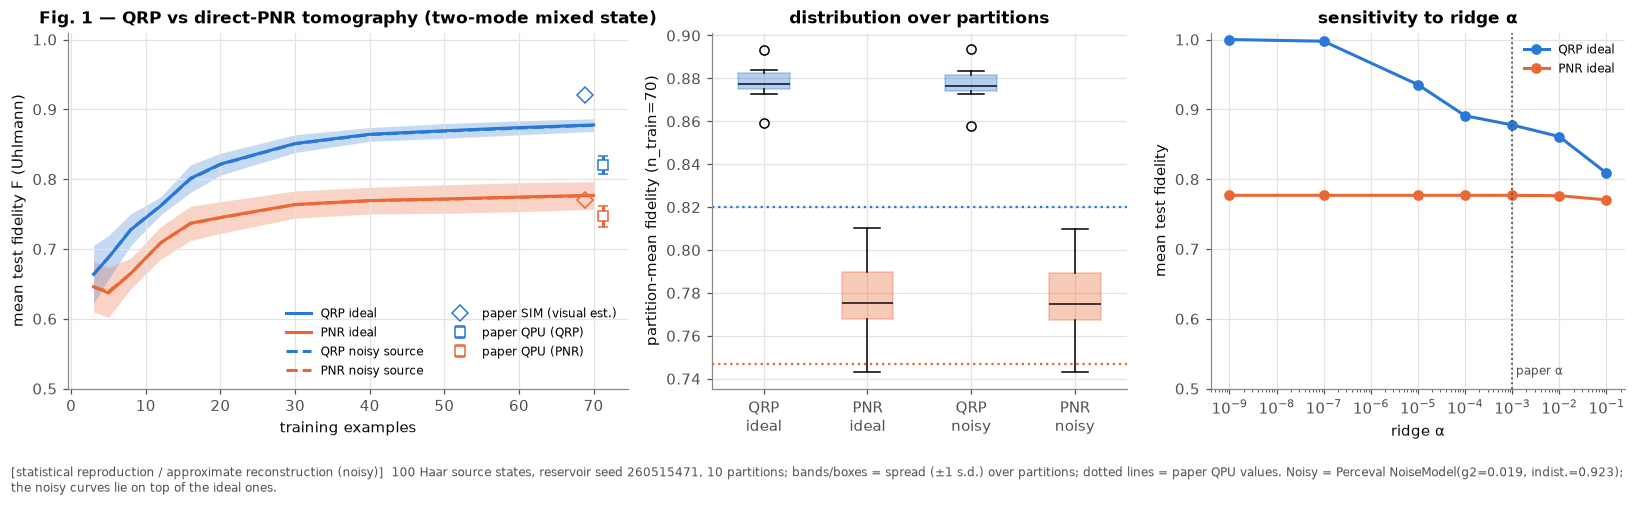

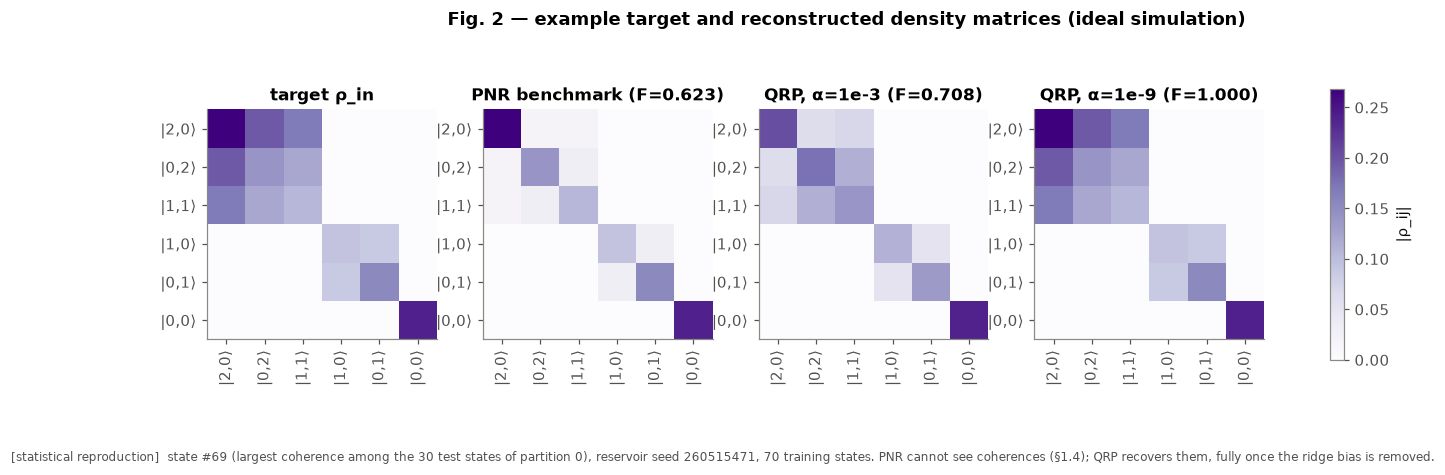

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw=dict(width_ratios=[1.35, 1, 1]))
ax = axs[0]
for F, lab, col, ls in [(F_qrp, "QRP ideal", COL["qrp"], "-"), (F_pnr, "PNR ideal", COL["pnr"], "-"),
                        (Fn_qrp, "QRP noisy source", COL["qrp"], "--"), (Fn_pnr, "PNR noisy source", COL["pnr"], "--")]:
    m, s = F.mean(0), F.std(0, ddof=1)
    ax.plot(sizes, m, ls, color=col, label=lab); ax.fill_between(sizes, m - s, m + s, color=col, alpha=0.15, lw=0)
ax.errorbar([nTr + 1.2], [0.820], [0.013], fmt="s", color=COL["qrp"], mfc="white", ms=7, capsize=3, label="paper QPU (QRP)")
ax.errorbar([nTr + 1.2], [0.747], [0.015], fmt="s", color=COL["pnr"], mfc="white", ms=7, capsize=3, label="paper QPU (PNR)")
ax.plot([nTr - 1.2], [0.92], "D", color=COL["qrp"], mfc="none", ms=7, label="paper SIM (visual est.)")
ax.plot([nTr - 1.2], [0.77], "D", color=COL["pnr"], mfc="none", ms=7)
ax.set(xlabel="training examples", ylabel="mean test fidelity F (Uhlmann)", ylim=(0.5, 1.01),
       title="Fig. 1 — QRP vs direct-PNR tomography (two-mode mixed state)")
ax.legend(fontsize=8, ncol=2, loc="lower right")
ax = axs[1]
data = [F_qrp[:, k70], F_pnr[:, k70], Fn_qrp[:, k70], Fn_pnr[:, k70]]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops=dict(color=COL["ink"]))
for patch, col in zip(bp["boxes"], [COL["qrp"], COL["pnr"], COL["qrp"], COL["pnr"]]):
    patch.set(facecolor=col, alpha=0.35, edgecolor=col)
ax.set_xticks([1, 2, 3, 4], ["QRP\nideal", "PNR\nideal", "QRP\nnoisy", "PNR\nnoisy"])
ax.axhline(0.820, color=COL["qrp"], ls=":", lw=1.5); ax.axhline(0.747, color=COL["pnr"], ls=":", lw=1.5)
ax.set(ylabel=f"partition-mean fidelity (n_train={nTr})", title="distribution over partitions")
ax = axs[2]
ax.semilogx(ALPHA_SWEEP, alpha_q, "o-", color=COL["qrp"], label="QRP ideal")
ax.semilogx(ALPHA_SWEEP, alpha_p, "o-", color=COL["pnr"], label="PNR ideal")
ax.axvline(1e-3, color=COL["ink2"], ls=":", lw=1.2); ax.text(1.2e-3, 0.52, "paper α", color=COL["ink2"], fontsize=8)
ax.set(xlabel="ridge α", ylabel="mean test fidelity", ylim=(0.5, 1.01), title="sensitivity to ridge α"); ax.legend(fontsize=8)
tag_note(axs[0], f"{nS} Haar source states, reservoir seed {res_seeds[0]}, {P['tomo_partitions']} partitions; bands/boxes = spread "
         f"(±1 s.d.) over partitions; dotted lines = paper QPU values. Noisy = Perceval NoiseModel(g2=0.019, indist.=0.923); "
         "the noisy curves lie on top of the ideal ones.",
         "statistical reproduction / approximate reconstruction (noisy)")
plt.tight_layout(); plt.show()

# Fig. 2: example density matrices. Selection rule (fixed in advance): the test state of partition 0 with the
# largest total coherence sum_{i!=j}|rho_ij|, i.e. the case where the PNR/QRP difference is physically clearest.
_, _, ex_q9 = tomography_partitions(X_qrp, R_all, sb2, nTr, 1, seed_part, alpha=1e-9)
coh = [np.abs(R_all[i]).sum() - np.abs(np.diag(R_all[i])).sum() for i in ex_qrp["index"]]
j0 = int(np.argmax(coh)); i0 = ex_qrp["index"][j0]
mats = [R_all[i0], ex_pnr["rec"][j0], ex_qrp["rec"][j0], ex_q9["rec"][j0]]
titles = ["target ρ_in", f"PNR benchmark (F={ex_pnr['fid'][j0]:.3f})", f"QRP, α=1e-3 (F={ex_qrp['fid'][j0]:.3f})",
          f"QRP, α=1e-9 (F={ex_q9['fid'][j0]:.3f})"]
fig, axs = plt.subplots(1, 4, figsize=(15.5, 4))
vmax = max(np.abs(m).max() for m in mats)
labels = [f"|{a},{b}⟩" for a, b in TOMO2_BASIS]
for ax, m, t in zip(axs, mats, titles):
    im = ax.imshow(np.abs(m), cmap="Purples", vmin=0, vmax=vmax)
    ax.set_xticks(range(6), labels, rotation=90); ax.set_yticks(range(6), labels); ax.set_title(t); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.8, label="|ρ_ij|")
fig.suptitle("Fig. 2 — example target and reconstructed density matrices (ideal simulation)", fontweight="bold")
tag_note(axs[0], f"state #{i0} (largest coherence among the 30 test states of partition 0), reservoir seed {res_seeds[0]}, 70 training states. "
         "PNR cannot see coherences (§1.4); QRP recovers them, fully once the ridge bias is removed.", "statistical reproduction")
plt.show()

### Interpretation of 3A
* In **ideal** simulation, the 15 QRP features determine all 13 parameters: the reservoir map is injective (§1.4). Nevertheless, with the paper's $\alpha=10^{-3}$ and 70 training states, the mean fidelity stays clearly below 1. The α-sweep (right panel) shows why: the smallest squared singular values of the unstandardised probability features are orders of magnitude below $10^{-3}$. Ridge therefore shrinks the directions that carry the coherences (§1.5). As $\alpha\to0$, QRP approaches $F\to1$, while PNR cannot exceed its information limit at any α.
* The regularisation bias alone puts our ideal QRP fidelity in the same range as the paper's digital-simulation curve (Fig. 2b "SIM", ≈0.92 at 70 states; visual estimate). The value depends on the particular Haar reservoir (ensemble spread printed above). A source-noise explanation is not needed: the Perceval noisy-source emulation with the published $g^{(2)}$ and indistinguishability changes the features by only ≈1–3 % in total-variation distance (printed above) and leaves the fidelity almost unchanged.
* The PNR benchmark sees only populations (§1.4). Its fidelity comes from the diagonal plus the training-set mean of the coherences. It statistically reproduces the paper's simulated ≈0.77.
* The experimental numbers (0.820, 0.747) include hardware imperfections that are not modelled here. They are quoted as literature values only.

## 3B. Tomography scalability — 🟩 statistical reproduction

For each reservoir size $M$ we compare:
* the **combinatorial** feature count $\binom{M+2}{2}$;
* the paper's "linearly independent features" $\binom{M+2}{2}-1$;
* the **numerical rank** of the $n\times D$ feature matrix (singular values above $10^{-10}\sigma_1$);
* the effective condition number $\sigma_1/\sigma_r$;
* the tomography fidelity.

Parameter counts are verified both combinatorially (`param_spec`) and numerically, as the affine dimension of the sampled label vectors. Three-mode states are made by discarding one of the four source modes, as in Fig. 3b. Two-mode scans use 100 states; three-mode scans use 300 states, because 45 parameters need more than 70 training states. This size is not stated in the paper and is inferred.

[budget] 3B scalability: largest Fock sector dim = 78, circuit evaluations ≈ 12,800, estimated ≈ 15 s


[3B scalability] 13.7 s | RSS 283 MB | peak 283 MB


D_comb  D_paper  rank  rank_centered     cond_eff  F_mean  \
state_modes M                                                               
2           2        6        5   6.0            5.0       5.2809  0.7771   
            3       10        9  10.0            9.0     194.9364  0.8535   
            4       15       14  14.0           13.0     944.2087  0.9229   
            5       21       20  14.0           13.0     135.9317  0.9617   
            6       28       27  14.0           13.0     137.3671  0.9539   
3           3       10        9  10.0            9.0       3.8113  0.4019   
            4       15       14  15.0           14.0      21.2878  0.4636   
            5       21       20  21.0           20.0      53.6827  0.5329   
            6       28       27  28.0           27.0     201.2648  0.5991   
            7       36       35  36.0           35.0     777.4360  0.6816   
            8       45       44  45.0           44.0  219663.7960  0.7242   
            9       55       54  46.0           45.0     768.6375  0.7740   
            10      66       65  46.0           45.0     378.4947  0.8304   
            11      78       77  46.0           45.0     196.5447  0.8604   

                F_nearOLS  F_sd_res  F_sd_part  paper_F_visual  
state_modes M                                                   
2           2      0.7771    0.0002     0.0155           0.785  
            3      0.8676    0.0256     0.0101           0.900  
            4      1.0000    0.0859     0.0087           1.000  
            5      1.0000    0.0311     0.0049           1.000  
            6      1.0000    0.0010     0.0081           1.000  
3           3      0.4020    0.0114     0.0062           0.410  
            4      0.4639    0.0127     0.0076           0.485  
            5      0.5346    0.0021     0.0107           0.560  
            6      0.6191    0.0107     0.0085           0.680  
            7      0.7223    0.0097     0.0078           0.830  
            8      0.9253    0.0246     0.0076           0.960  
            9      1.0000    0.0749     0.0043           1.000  
            10     1.0000    0.0541     0.0066           1.000  
            11     1.0000    0.0767     0.0064           1.000

verified: 13 (two-mode) and 45 (three-mode) independent real parameters, combinatorially and numerically.
smallest M with numerical (centred) rank >= #parameters: two-mode M=4, three-mode M=9 (paper: 4 and 9)


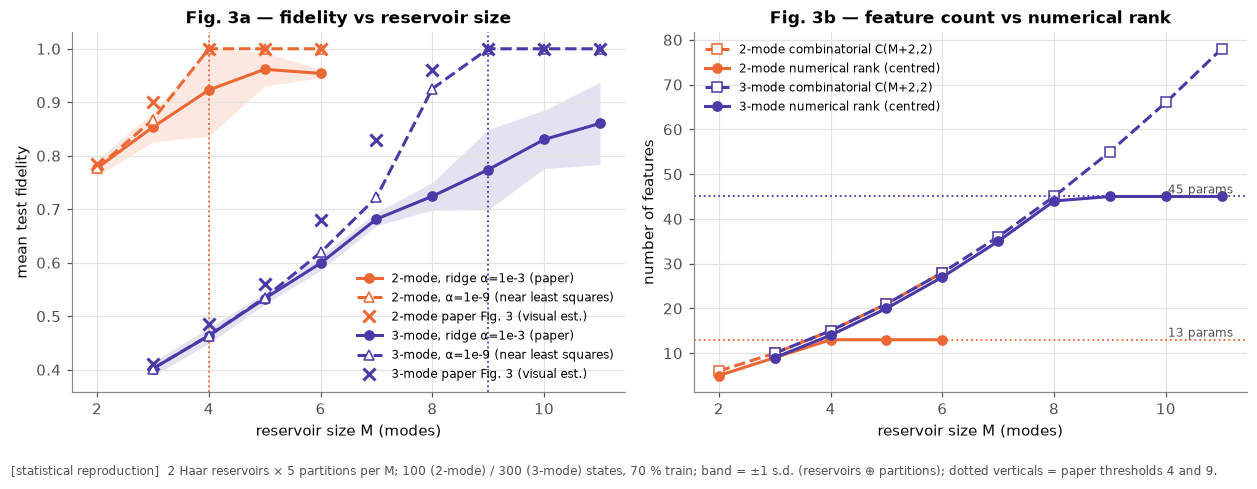

In [12]:
with section("3B scalability"):
    n_calls = 2 * P["scal_reservoirs"] * (5 * P["scal_states2"] + 9 * P["scal_states3"])
    budget("3B scalability", hilbert_dim=len(fock_basis(12, 2)), n_evals=n_calls, sec_per_eval=2 * SEC_PER_CALL)
    scal_rows = []
    PAPER_SCAL = {2: dict(zip(range(2, 7), [0.785, 0.90, 1.0, 1.0, 1.0])),
                  3: dict(zip(range(3, 12), [0.41, 0.485, 0.56, 0.68, 0.83, 0.96, 1.0, 1.0, 1.0]))}
    for nsm, Ms, n_states in [(2, range(2, 7), P["scal_states2"]), (3, range(3, 12), P["scal_states3"])]:
        U_S_list = [haar_unitary(4, MASTER_SEED + 20000 + 1000 * nsm + k) for k in range(n_states)]
        n_train = int(round(0.7 * n_states))
        for M in Ms:
            for r in range(P["scal_reservoirs"]):
                X, R, sb, fb = tomography_dataset(nsm, M, haar_unitary(M, MASTER_SEED + 30000 + 1000 * nsm + 50 * M + r), U_S_list)
                spec = param_spec(sb)
                sv = np.linalg.svd(X, compute_uv=False); rank = int((sv > 1e-10 * sv[0]).sum())
                svc = np.linalg.svd(X - X.mean(0), compute_uv=False); rank_c = int((svc > 1e-10 * svc[0]).sum())
                Yc = rho_to_params(R, spec); Yc = Yc - Yc.mean(0)
                sy = np.linalg.svd(Yc, compute_uv=False); p_num = int((sy > 1e-10 * sy[0]).sum())
                F, *_ = tomography_partitions(X, R, sb, n_train, P["scal_partitions"], MASTER_SEED + 88 + r)
                F0, *_ = tomography_partitions(X, R, sb, n_train, P["scal_partitions"], MASTER_SEED + 88 + r, alpha=1e-9)
                scal_rows.append(dict(state_modes=nsm, M=M, reservoir=r, D_combinatorial=len(fb), D_paper=len(fb) - 1,
                                      rank=rank, rank_centered=rank_c, cond_eff=sv[0] / sv[rank - 1],
                                      params=spec["n_params"], params_numerical=p_num,
                                      F_mean=F.mean(), F_std=F.std(ddof=1), F_nearOLS=F0.mean(), paper_F_visual=PAPER_SCAL[nsm][M]))
scal = pd.DataFrame(scal_rows)
assert set(scal[scal.state_modes == 2].params) == {13} and set(scal[scal.state_modes == 3].params) == {45}
assert set(scal[scal.state_modes == 2].params_numerical) == {13} and set(scal[scal.state_modes == 3].params_numerical) == {45}
scal_sum = scal.groupby(["state_modes", "M"]).agg(D_comb=("D_combinatorial", "first"), D_paper=("D_paper", "first"),
            rank=("rank", "median"), rank_centered=("rank_centered", "median"), cond_eff=("cond_eff", "median"),
            F_mean=("F_mean", "mean"), F_nearOLS=("F_nearOLS", "mean"), F_sd_res=("F_mean", "std"), F_sd_part=("F_std", "mean"),
            paper_F_visual=("paper_F_visual", "first"))
display(scal_sum.round(4))
thr = {nsm: int(scal_sum.loc[nsm][scal_sum.loc[nsm].rank_centered >= (13 if nsm == 2 else 45)].index.min()) for nsm in (2, 3)}
print(f"verified: 13 (two-mode) and 45 (three-mode) independent real parameters, combinatorially and numerically.")
print(f"smallest M with numerical (centred) rank >= #parameters: two-mode M={thr[2]}, three-mode M={thr[3]} (paper: 4 and 9)")
RESULTS["scal"] = dict(thr=thr, table=scal_sum)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2))
for nsm, col, npar in [(2, COL["pnr"], 13), (3, COL["vio"], 45)]:
    d = scal_sum.loc[nsm]
    axs[0].plot(d.index, d.F_mean, "o-", color=col, label=f"{nsm}-mode, ridge α=1e-3 (paper)")
    axs[0].plot(d.index, d.F_nearOLS, "^--", color=col, mfc="white", label=f"{nsm}-mode, α=1e-9 (near least squares)")
    sd = np.sqrt(d.F_sd_res.fillna(0) ** 2 + d.F_sd_part ** 2)
    axs[0].fill_between(d.index, d.F_mean - sd, np.minimum(d.F_mean + sd, 1), color=col, alpha=0.15, lw=0)
    axs[0].plot(d.index, d.paper_F_visual, "x", color=col, ms=8, mew=2, label=f"{nsm}-mode paper Fig. 3 (visual est.)")
    axs[0].axvline(4 if nsm == 2 else 9, color=col, ls=":", lw=1.2)
    axs[1].plot(d.index, d.D_comb, "s--", color=col, mfc="white", label=f"{nsm}-mode combinatorial C(M+2,2)")
    axs[1].plot(d.index, d.rank_centered, "o-", color=col, label=f"{nsm}-mode numerical rank (centred)")
    axs[1].axhline(npar, color=col, ls=":", lw=1.2)
    axs[1].text(11.2, npar, f"{npar} params", color=COL["ink2"], va="bottom", ha="right", fontsize=8)
axs[0].set(xlabel="reservoir size M (modes)", ylabel="mean test fidelity", title="Fig. 3a — fidelity vs reservoir size")
axs[1].set(xlabel="reservoir size M (modes)", ylabel="number of features", title="Fig. 3b — feature count vs numerical rank")
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
tag_note(axs[0], f"{P['scal_reservoirs']} Haar reservoirs × {P['scal_partitions']} partitions per M; 100 (2-mode) / 300 (3-mode) states, 70 % train; "
         "band = ±1 s.d. (reservoirs ⊕ partitions); dotted verticals = paper thresholds 4 and 9.", "statistical reproduction")
plt.tight_layout(); plt.show()

**Reading 3B.** The thresholds are reproduced exactly: the centred numerical rank first reaches the parameter count at $M=4$ (13) and $M=9$ (45). With the paper's $\alpha=10^{-3}$, the fidelities rise smoothly but stay below 1 at threshold. This is the same regularisation bias as in 3A, and it is stronger for 45 parameters. With $\alpha\to0$ (dashed), fidelity jumps to ≈1 exactly at threshold, which reproduces the step-like shape of the paper's Fig. 3. We infer that the paper's Fig. 3 used a weaker effective regularisation or more data; this is not stated in the paper. Numerical rank saturates at $\min\{\binom{M+2}{2},\,K+1\}$, where $K$ is the number of free parameters and the $+1$ is the constant direction; centring removes it (§1.3). For $M\ge$ threshold, the extra combinatorial outcomes are linear combinations of the others and add no information. The paper states that the rank equals "the number of free parameters plus one", and the uncentred rank column shows exactly that. Below threshold, the reconstruction is under-determined and ridge returns the minimum-norm, prior-weighted estimate.

## 3C. Quantum-property extraction — 🟩 statistical reproduction

The state family is Eq. (2) of the paper. The readout is a scikit-learn `LinearRegression` onto the Bloch vector $(a_x,a_y,a_z)=(2\sigma\cos\phi,2\sigma\sin\phi,n_1-n_2)$, with $\rho=\tfrac12\begin{pmatrix}1+a_z & a_x+ia_y\\ a_x-ia_y & 1-a_z\end{pmatrix}$ in the basis $\{\lvert2,0\rangle,\lvert0,2\rangle\}$. This sign convention reproduces $\rho_{12}=\sigma e^{i\phi}$ exactly as written in Eq. (2). With the standard Pauli convention it would give $\sigma e^{-i\phi}$, which is irrelevant for $P$, $S$ and $\mathcal N$.

Predicted Bloch vectors with $\lvert\hat{\mathbf a}\rvert>1$ are projected onto the Bloch sphere. For a qubit this is identical to eigenvalue clipping. We report how often it was needed.

Detector configurations (Fig. 4 schematic):
* **PNR:** $U_R=\mathbb 1_2$.
* **QRP-2:** Haar $2\times2$ $U_R$ on the two modes.
* **QRP-3:** Haar $3\times3$ $U_R$ with one extra vacuum mode.

The Fock amplitudes $A_{\mathbf m,i}=\langle\mathbf m\rvert\hat U_R\lvert i\rangle$, for $i\in\{\lvert2,0\rangle,\lvert0,2\rangle\}$, come from Perceval. Features follow from $p(\mathbf m)=\sum_{ij}\rho_{ij}A_{\mathbf mi}A^*_{\mathbf mj}$; test 10 in §2 validates this contraction against direct Perceval simulation.

[budget] 3C properties: largest Fock sector dim = 6, circuit evaluations ≈ 21, estimated ≈ 0 s


[3C properties] 0.3 s | RSS 287 MB | peak 289 MB


**Property extraction** — train 1500, test 150 states (paper: 1500/150, 50 reservoirs).

,outcomes,numerical rank (centred),reservoirs,fidelity mean,fidelity s.d. (reservoirs),RMSE purity,RMSE entropy,RMSE negativity,fraction |a|>1 projected
PNR,3.0,1.0,1.0,0.9455,0.0000,0.1334,0.1660,0.2058,0.0
QRP-2,3.0,2.0,10.0,0.9749,0.0033,0.0778,0.0998,0.0971,0.0
QRP-3,6.0,3.0,10.0,1.0000,0.0000,0.0000,0.0000,0.0000,0.0


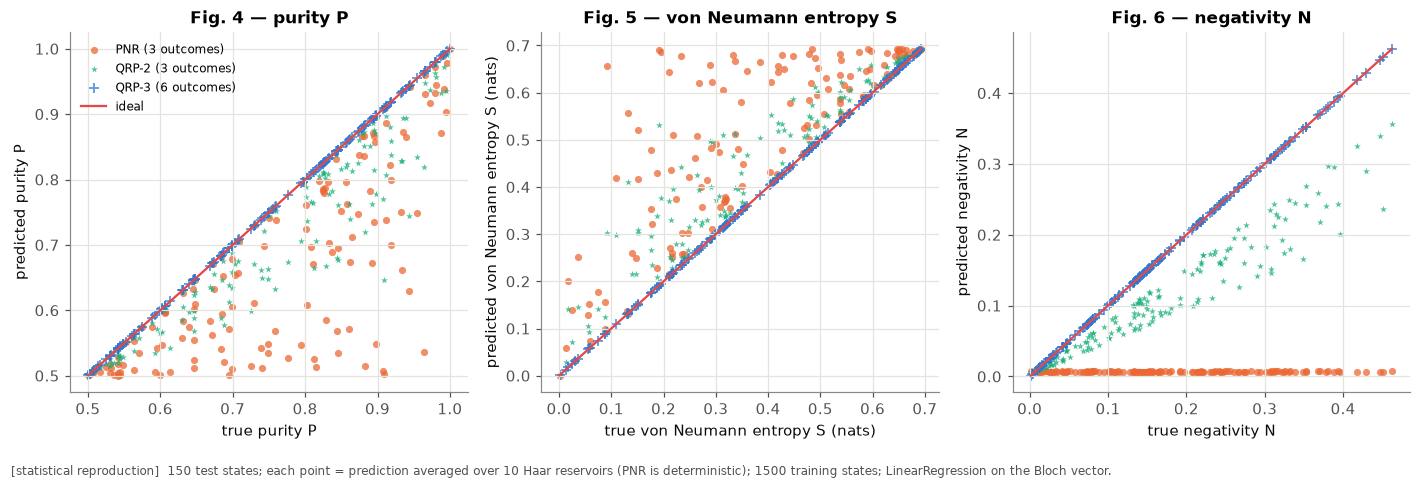

In [13]:
PROP_BASIS = [(2, 0), (0, 2)]

def prop_states(n, rng):
    nn, g, vp = rng.uniform(size=(3, n))
    n1, n2 = 1 - nn, nn; sig = g * np.sqrt(n1 * n2); phi = 2 * np.pi * vp
    rho = np.zeros((n, 2, 2), complex)
    rho[:, 0, 0], rho[:, 1, 1] = n1, n2
    rho[:, 0, 1] = sig * np.exp(1j * phi); rho[:, 1, 0] = np.conj(rho[:, 0, 1])
    a = np.stack([2 * sig * np.cos(phi), 2 * sig * np.sin(phi), n1 - n2], 1)
    R = np.sqrt((n1 - n2) ** 2 + 4 * sig ** 2)
    with np.errstate(divide="ignore", invalid="ignore"):
        S = np.log(2) - 0.5 * np.log(1 - R ** 2) + R / 2 * np.log((1 - R) / (1 + R))
    analytic = dict(P=n1 ** 2 + n2 ** 2 + 2 * sig ** 2, S=np.nan_to_num(S), N=np.abs(sig))
    return rho, a, analytic

def bloch_to_rho(a):
    a = np.asarray(a, float); nrm = np.linalg.norm(a)
    if nrm > 1: a = a / nrm
    return 0.5 * np.array([[1 + a[2], a[0] + 1j * a[1]], [a[0] - 1j * a[1], 1 - a[2]]])

def prop_amplitudes(kind, seed):
    if kind == "PNR":
        m, U, ins = 2, np.eye(2), PROP_BASIS
    elif kind == "QRP-2":
        m, U, ins = 2, haar_unitary(2, seed), PROP_BASIS
    else:
        m, U, ins = 3, haar_unitary(3, seed), [(0,) + b for b in PROP_BASIS]   # vacuum in the extra mode 0
    return transfer_matrix(unitary_circuit(m, [(0, U)]), ins, fock_basis(m, 2))

def props_of(rho):
    return np.array([purity(rho), vn_entropy(rho), negativity_two_mode(rho, PROP_BASIS)])

with section("3C properties"):
    budget("3C properties", hilbert_dim=len(fock_basis(3, 2)), n_evals=2 * P["prop_reservoirs"] + 1, sec_per_eval=SEC_PER_CALL)
    rng = rng_for("props")
    rho_tr, a_tr, _ = prop_states(P["prop_train"], rng)
    rho_te, a_te, an_te = prop_states(P["prop_test"], rng)
    true_props = np.array([props_of(r) for r in rho_te])
    for k, key in enumerate("PSN"):   # analytic closed forms (§1.7) vs numerical routines
        assert np.abs(true_props[:, k] - an_te[key]).max() < 1e-7, key
    prop_res = {}
    for kind in ["PNR", "QRP-2", "QRP-3"]:
        n_res = 1 if kind == "PNR" else P["prop_reservoirs"]   # identity reservoir is deterministic
        preds, fids, unphys, ranks = [], [], [], []
        for r in range(n_res):
            A = prop_amplitudes(kind, MASTER_SEED + 40000 + 97 * r + (7 if kind == "QRP-3" else 0))
            feat = lambda rho: np.einsum("oi,nij,oj->no", A, rho, A.conj()).real
            Xtr, Xte = feat(rho_tr), feat(rho_te)
            ranks.append(np.linalg.matrix_rank(Xtr - Xtr.mean(0), tol=1e-10))
            a_hat = LinearRegression().fit(Xtr, a_tr).predict(Xte)
            unphys.append(np.mean(np.linalg.norm(a_hat, axis=1) > 1))
            rec = [bloch_to_rho(a) for a in a_hat]
            preds.append(np.array([props_of(r_) for r_ in rec]))
            fids.append(np.mean([fidelity(r_, t) for r_, t in zip(rec, rho_te)]))
        preds = np.array(preds)
        prop_res[kind] = dict(pred_mean=preds.mean(0), fid=np.array(fids), unphys=np.mean(unphys),
                              rmse=np.sqrt(((preds - true_props[None]) ** 2).mean(1)).mean(0),
                              rank=int(np.median(ranks)), n_out=A.shape[0], n_res=n_res)

prop_table = pd.DataFrame({k: {"outcomes": v["n_out"], "numerical rank (centred)": v["rank"], "reservoirs": v["n_res"],
                               "fidelity mean": v["fid"].mean(), "fidelity s.d. (reservoirs)": v["fid"].std(ddof=1) if len(v["fid"]) > 1 else 0,
                               "RMSE purity": v["rmse"][0], "RMSE entropy": v["rmse"][1], "RMSE negativity": v["rmse"][2],
                               "fraction |a|>1 projected": v["unphys"]} for k, v in prop_res.items()}).T
display(Markdown(f"**Property extraction** — train {P['prop_train']}, test {P['prop_test']} states "
                 f"(paper: 1500/150, 50 reservoirs)."))
display(prop_table.round(4))
RESULTS["props"] = prop_table

fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
names = ["purity P", "von Neumann entropy S (nats)", "negativity N"]
order = [2, 0, 1]   # paper panel order: entropy, negativity, purity -> we plot Fig.4 purity, Fig.5 entropy, Fig.6 negativity
for ax, k, fig_no in zip(axs, [0, 1, 2], [4, 5, 6]):
    for kind, col, mk in [("PNR", COL["pnr"], "o"), ("QRP-2", COL["aux"], "*"), ("QRP-3", COL["qrp"], "+")]:
        ax.scatter(true_props[:, k], prop_res[kind]["pred_mean"][:, k], s=22 if mk != "+" else 40, marker=mk,
                   color=col, alpha=0.75, label=f"{kind} ({prop_res[kind]['n_out']} outcomes)", lw=1.2 if mk == "+" else 0)
    lo, hi = true_props[:, k].min(), true_props[:, k].max()
    ax.plot([lo, hi], [lo, hi], color=COL["red"], lw=1.5, label="ideal")
    ax.set(xlabel=f"true {names[k]}", ylabel=f"predicted {names[k]}", title=f"Fig. {fig_no} — {names[k].split(' (')[0]}")
axs[0].legend(fontsize=8)
tag_note(axs[0], f"{P['prop_test']} test states; each point = prediction averaged over {P['prop_reservoirs']} Haar reservoirs "
         f"(PNR is deterministic); {P['prop_train']} training states; LinearRegression on the Bloch vector.", "statistical reproduction")
plt.tight_layout(); plt.show()

**Reading 3C.** The family has three real parameters. With two detectors there are $\binom{3}{2}=3$ outcomes but only 2 independent ones, so one Bloch direction is lost for most $U_R$. Three detectors give $\binom{4}{2}=6$ outcomes, and the rank saturates at 3 once centred, i.e. at the number of parameters. The linear readout then inverts the map exactly. Direct PNR sees only $n_1,n_2$, so it predicts $\sigma\approx0$ and $\mathcal N\approx0$, as in the paper's Fig. 4b. This reproduces the qualitative conclusion: three suitable PNR outputs suffice.

## 3D. Two intertwined spirals and hardware-aware training — 🟨 approximate reconstruction

**Reconstructed setup.** The dataset, the $(x,y)\to(\theta,\varphi)$ map and the readout network are all specified only in the unavailable SI. We use:
* 780° two-armed spirals with Gaussian noise σ=0.5;
* min–max normalisation with **training-set** statistics, then $\theta=\pi\tilde x$, $\varphi=\pi\tilde y$;
* a two-photon dual-rail input: each rail pair gets `BS(θ)` then `PS(φ)`, as drawn in Fig. 5;
* a fixed Haar $4\times4$ $U_R$ and the 10 two-photon PNR outcomes.

Everything is simulated natively by Perceval, one circuit per sample.

**Classical baseline** (paper's horizontal line): the same encoding with a coherent state in place of the photons, and mean intensities $I_j=\lvert(U_R\boldsymbol\alpha)_j\rvert^2$ in place of PNR. This is classical wave optics.

**Readout:** a one-hidden-layer MLP on standardised features. Because the paper's architecture is unknown, we first **scan the width**. The quantum-versus-classical comparison depends on readout capacity, and we show that dependence. The width for the $\epsilon$-study is fixed *on the validation split* as the smallest width within 0.5 % of the best validation accuracy.

**Hardware-aware training:** every training sample gets its own $U_\epsilon=\mathrm{polar}(U_R+\epsilon G)$, with $G_{ij}\sim\mathcal{CN}(0,1)$ so that each element receives variance $\epsilon^2$. Polar projection gives the nearest unitary, so every simulated circuit stays passive and lossless.

**Hardware surrogate:** Ascella is not accessible, so the test device is emulated as a fixed unknown deviation $U_{hw}=\mathrm{polar}(U_R+\delta_{hw}G_{hw})$. The paper says its optimum $\epsilon=0.075$ is "consistent with the measured transpilation error", which motivates $\delta_{hw}=0.075$. **This is our assumption, not a published calibration.** The reference and full profiles also scan $\delta_{hw}$, to show that the optimum tracks the device deviation.

In [14]:
from scipy.linalg import polar
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
P.setdefault("spiral_hw_deltas", [0.075] if RUN_MODE == "quick" else [0.05, 0.075, 0.1])
SPIRAL_OUTS = fock_basis(4, 2)

def two_spirals(n_per_class, rng, noise=0.5, max_deg=780):
    t = np.sqrt(rng.uniform(size=n_per_class)) * max_deg * np.pi / 180
    arm = np.c_[-np.cos(t) * t, np.sin(t) * t]
    X = np.r_[arm + rng.normal(scale=noise, size=arm.shape), -arm + rng.normal(scale=noise, size=arm.shape)]
    y = np.r_[np.zeros(n_per_class), np.ones(n_per_class)].astype(int)
    p = rng.permutation(len(X))
    return X[p], y[p]

def encode_angles(Xn):
    return np.pi * Xn[:, 0], np.pi * Xn[:, 1]

def spiral_features_quantum(Xn, U_list):
    """Perceval: dual-rail encoding BS(θ)+PS(φ) on each photon, then U_R (one unitary per sample allowed)."""
    th, ph = encode_angles(Xn); be = pcvl.SLOSBackend(); F = np.zeros((len(Xn), len(SPIRAL_OUTS)))
    idx = {o: k for k, o in enumerate(SPIRAL_OUTS)}
    for n in range(len(Xn)):
        U = U_list[n] if isinstance(U_list, list) else U_list
        c = (pcvl.Circuit(4).add(0, pcvl.BS(theta=float(th[n]))).add(0, pcvl.PS(float(ph[n])))
             .add(2, pcvl.BS(theta=float(th[n]))).add(2, pcvl.PS(float(ph[n]))).add(0, pcvl.Unitary(pcvl.Matrix(U))))
        be.set_circuit(c); be.set_input_state(pcvl.BasicState([1, 0, 1, 0]))
        for s, p in be.prob_distribution().items():
            F[n, idx[tuple(s)]] = p
    return F

def spiral_features_classical(Xn, U):
    """Coherent state with the same dual-rail amplitudes; mean intensities after U_R (classical wave optics)."""
    th, ph = encode_angles(Xn)
    alpha = np.c_[np.exp(1j * ph) * np.cos(th / 2), 1j * np.sin(th / 2), np.exp(1j * ph) * np.cos(th / 2), 1j * np.sin(th / 2)] / np.sqrt(2)
    return np.abs(alpha @ U.T) ** 2

def perturbed_unitary(U, eps, rng):
    G = (rng.normal(size=U.shape) + 1j * rng.normal(size=U.shape)) / np.sqrt(2)
    V = polar(U + eps * G)[0]
    assert np.allclose(V.conj().T @ V, np.eye(len(U)), atol=1e-10)
    return V

def mlp(width, seed):
    return make_pipeline(StandardScaler(), MLPClassifier((width,), max_iter=4000, random_state=seed))

# a quick check of our encoding against the paper's statement: the U_R-free encoding gives product dual-rail states
_th = 0.7; _c = pcvl.Circuit(2).add(0, pcvl.BS(theta=_th)).add(0, pcvl.PS(0.3))
assert abs(perceval_probs(_c, (1, 0))[(1, 0)] - math.cos(_th / 2) ** 2) < 1e-12

with section("3D spirals"):
    n_tot = 2 * P["spiral_per_class"]; n_tr, n_va = int(0.6 * n_tot), int(0.2 * n_tot)
    n_calls = P["spiral_seeds"] * (n_tot + len(P["spiral_eps"]) * n_tr * len(P["spiral_hw_deltas"]) + n_tot * len(P["spiral_hw_deltas"]))
    budget("3D spirals", hilbert_dim=len(SPIRAL_OUTS), n_evals=n_calls, sec_per_eval=1.5 * SEC_PER_CALL)
    rng = rng_for("spirals")
    Xs, ys = two_spirals(P["spiral_per_class"], rng)
    tr, va, te = np.arange(n_tr), np.arange(n_tr, n_tr + n_va), np.arange(n_tr + n_va, n_tot)
    lo, hi = Xs[tr].min(0), Xs[tr].max(0)
    Xn = np.clip((Xs - lo) / (hi - lo), 0, 1)
    width_rows, eps_rows, boundary = [], [], None
    for s in range(P["spiral_seeds"]):
        U_R = haar_unitary(4, MASTER_SEED + 60000 + s)
        Fq, Fc = spiral_features_quantum(Xn, U_R), spiral_features_classical(Xn, U_R)
        for w in P["spiral_widths"]:
            mq = mlp(w, s).fit(Fq[tr], ys[tr]); mc = mlp(w, s).fit(Fc[tr], ys[tr])
            width_rows.append(dict(seed=s, width=w, q_val=mq.score(Fq[va], ys[va]), q_test=mq.score(Fq[te], ys[te]),
                                   c_val=mc.score(Fc[va], ys[va]), c_test=mc.score(Fc[te], ys[te])))
        wdf = pd.DataFrame([r for r in width_rows if r["seed"] == s])
        w_sel = int(wdf[wdf.q_val >= wdf.q_val.max() - 0.005].width.min())
        c_ideal = float(wdf[wdf.width == w_sel].c_test.iloc[0])
        if s == 0:
            boundary = dict(U=U_R, w=w_sel)
        rng_p = np.random.default_rng([MASTER_SEED, 61, s])
        for dhw in P["spiral_hw_deltas"]:
            U_hw = perturbed_unitary(U_R, dhw, np.random.default_rng([MASTER_SEED, 62, s, int(1000 * dhw)]))
            Fq_hw = spiral_features_quantum(Xn[te], U_hw); Fc_hw = spiral_features_classical(Xn[te], U_hw)
            c_hw = mlp(w_sel, s).fit(Fc[tr], ys[tr]).score(Fc_hw, ys[te])
            for eps in P["spiral_eps"]:
                Ftr = Fq[tr] if eps == 0 else spiral_features_quantum(Xn[tr], [perturbed_unitary(U_R, eps, rng_p) for _ in tr])
                m = mlp(w_sel, s).fit(Ftr, ys[tr])
                eps_rows.append(dict(seed=s, delta_hw=dhw, eps=eps, width=w_sel, acc_hw=m.score(Fq_hw, ys[te]),
                                     acc_ideal=m.score(Fq[te], ys[te]), classical_ideal=c_ideal, classical_hw=c_hw))

edf = pd.DataFrame(eps_rows)
wdf = pd.DataFrame(width_rows).groupby("width")[["q_test", "c_test"]].agg(["mean", "std"])
edf = pd.DataFrame(eps_rows)
esum = edf.groupby(["delta_hw", "eps"])[["acc_hw", "acc_ideal", "classical_ideal", "classical_hw"]].agg(["mean", "std"])
print("readout width selected on validation (per reservoir seed / δ_hw):", edf[edf.eps == 0].width.tolist())
display(Markdown(f"**Ideal test accuracy vs readout width** ({P['spiral_seeds']} reservoirs, test n={len(te)})")); display(wdf.round(4))
display(Markdown("**Hardware-aware training: test accuracy vs ε**")); display(esum.round(4))
e0 = edf[edf.delta_hw == 0.075].groupby("eps").acc_hw.mean()
RESULTS["spiral"] = dict(ideal_q=float(edf[edf.eps == 0].acc_ideal.mean()), ideal_c=float(edf.classical_ideal.mean()),
                         hw_eps0=float(e0.loc[0.0]), hw_best=float(e0.max()), eps_best=float(e0.idxmax()),
                         hw_eps075=float(e0.loc[0.075]), width=sorted(set(edf.width)))

[budget] 3D spirals: largest Fock sector dim = 10, circuit evaluations ≈ 12,400, estimated ≈ 11 s


[3D spirals] 42.6 s | RSS 294 MB | peak 294 MB
readout width selected on validation (per reservoir seed / δ_hw): [32, 32]


**Ideal test accuracy vs readout width** (2 reservoirs, test n=200)

q_test          c_test        
         mean     std    mean     std
width                                
2      0.6725  0.1096  0.6100  0.0566
4      0.7525  0.0884  0.6125  0.0247
8      0.8550  0.0283  0.8525  0.0106
16     0.9825  0.0035  0.9375  0.0601
32     0.9875  0.0177  0.9800  0.0141

**Hardware-aware training: test accuracy vs ε**

acc_hw         acc_ideal         classical_ideal          \
                  mean     std      mean     std            mean     std   
delta_hw eps                                                               
0.075    0.000  0.6800  0.0212    0.9875  0.0177            0.98  0.0141   
         0.025  0.8250  0.0141    0.9875  0.0106            0.98  0.0141   
         0.050  0.8950  0.0424    0.9825  0.0035            0.98  0.0141   
         0.075  0.8950  0.0424    0.9575  0.0035            0.98  0.0141   
         0.100  0.8650  0.0354    0.9050  0.0283            0.98  0.0141   
         0.150  0.7850  0.0000    0.8200  0.0424            0.98  0.0141   
         0.200  0.6775  0.0530    0.7125  0.0672            0.98  0.0141   

               classical_hw          
                       mean     std  
delta_hw eps                         
0.075    0.000       0.5875  0.1379  
         0.025       0.5875  0.1379  
         0.050       0.5875  0.1379  
         0.075       0.5875  0.1379  
         0.100       0.5875  0.1379  
         0.150       0.5875  0.1379  
         0.200       0.5875  0.1379

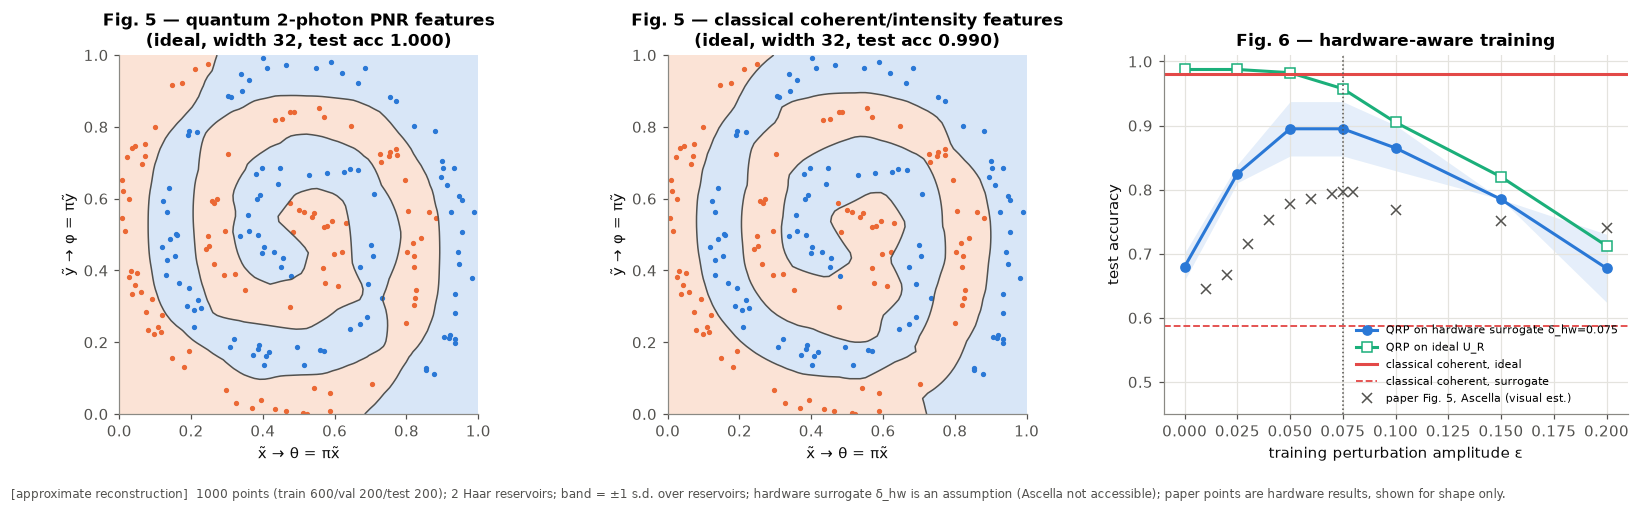

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
gx = np.linspace(0, 1, 70); GX, GY = np.meshgrid(gx, gx); G = np.c_[GX.ravel(), GY.ravel()]
Uq = boundary["U"]
mq = mlp(boundary["w"], 0).fit(spiral_features_quantum(Xn[tr], Uq), ys[tr])
mc = mlp(boundary["w"], 0).fit(spiral_features_classical(Xn[tr], Uq), ys[tr])
for ax, model, feat, feat_te, title in [
        (axs[0], mq, spiral_features_quantum(G, Uq), spiral_features_quantum(Xn[te], Uq), "quantum 2-photon PNR features"),
        (axs[1], mc, spiral_features_classical(G, Uq), spiral_features_classical(Xn[te], Uq), "classical coherent/intensity features")]:
    Z = model.predict_proba(feat)[:, 1].reshape(GX.shape)
    ax.contourf(GX, GY, Z, levels=[0, 0.5, 1], colors=["#fbe3d6", "#d8e6f7"])
    ax.contour(GX, GY, Z, levels=[0.5], colors=[COL["ink2"]], linewidths=1)
    for c, col in [(0, COL["pnr"]), (1, COL["qrp"])]:
        sel = te[ys[te] == c]; ax.scatter(Xn[sel, 0], Xn[sel, 1], s=6, color=col, label=f"class {c} (test)")
    acc = model.score(feat_te, ys[te])
    ax.set(title=f"Fig. 5 — {title}\n(ideal, width {boundary['w']}, test acc {acc:.3f})", xlabel="x̃ → θ = πx̃", ylabel="ỹ → φ = πỹ", aspect="equal")
    ax.grid(False)
ax = axs[2]
for dhw, ls in zip(P["spiral_hw_deltas"], ["-", "--", ":"]):
    d = esum.loc[dhw]
    ax.plot(d.index, d[("acc_hw", "mean")], "o" + ls, color=COL["qrp"], label=f"QRP on hardware surrogate δ_hw={dhw}")
    ax.fill_between(d.index, d[("acc_hw", "mean")] - d[("acc_hw", "std")].fillna(0), d[("acc_hw", "mean")] + d[("acc_hw", "std")].fillna(0),
                    color=COL["qrp"], alpha=0.12, lw=0)
d = esum.loc[0.075] if 0.075 in esum.index.get_level_values(0) else esum.loc[P["spiral_hw_deltas"][0]]
ax.plot(d.index, d[("acc_ideal", "mean")], "s-", color=COL["aux"], mfc="white", label="QRP on ideal U_R")
ax.axhline(d[("classical_ideal", "mean")].iloc[0], color=COL["red"], lw=2, label="classical coherent, ideal")
ax.axhline(d[("classical_hw", "mean")].iloc[0], color=COL["red"], lw=1.2, ls="--", label="classical coherent, surrogate")
pe, pa = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.075, 0.08, 0.1, 0.15, 0.2], [0.645, 0.667, 0.716, 0.753, 0.777, 0.786, 0.793, 0.797, 0.797, 0.769, 0.751, 0.741]
ax.plot(pe, pa, "x", color=COL["ink2"], label="paper Fig. 5, Ascella (visual est.)")
ax.axvline(0.075, color=COL["ink2"], ls=":", lw=1)
ax.set(xlabel="training perturbation amplitude ε", ylabel="test accuracy", title="Fig. 6 — hardware-aware training", ylim=(0.45, 1.01))
ax.legend(fontsize=7, loc="lower right")
tag_note(axs[0], f"{n_tot} points (train {n_tr}/val {n_va}/test {len(te)}); {P['spiral_seeds']} Haar reservoirs; band = ±1 s.d. over reservoirs; "
         "hardware surrogate δ_hw is an assumption (Ascella not accessible); paper points are hardware results, shown for shape only.",
         "approximate reconstruction")
plt.tight_layout(); plt.show()

**Reading 3D.**
* With an ideal simulator and an adequate readout, the two-photon features classify the spirals at ≳98 %. This matches the paper's in-silico claim.
* The **quantum-versus-classical gap is readout-dependent**. It is large for very small readouts, where the two-photon features, quadratic in the single-photon Bloch vector, help a weak network. It shrinks as the MLP grows, because intensities alone are an injective map of $(\theta,\varphi)$. The paper's classical line (≈0.738) must therefore reflect its specific (unpublished) network, and our width scan makes the dependence explicit.
* A unitary mismatch between the programmed and the physical device collapses the naive classifier (ε=0). Training with random unitary perturbations restores accuracy, with an optimum near ε≈δ_hw. This is the qualitative mechanism of the paper's Fig. 5. The absolute levels differ: the real device has further imperfections (source, detectors, loss) that we do not model, and our surrogate is an assumption.

# 4. Part II — New recurrent DV-QRC extension  🟪 *new temporal extension (not studied in the reference paper)*

## 4.1 Temporal reservoir channel

The architecture is a **collision model**. At every time step $k$ a fresh single photon, encoding the scalar input $u_k\in[0,1]$, collides with a persistent optical memory inside a fixed passive interferometer. The photons that leave the memory are detected with PNR detectors. Six modes are used:

| modes | role | state before step | fate after step |
|---|---|---|---|
| $m_0,m_1$ (0, 1) | **persistent memory** | $\rho_k$ (carried over) | **retained** → $\rho_{k+1}$ |
| $a_0,a_1$ (2, 3) | **fresh input** (dual rail) | $\rho_{in}(u_k)$, exactly one photon | become the **tap** modes: PNR-measured, then **discarded** |
| $e_0,e_1$ (4, 5) | **environment** (loss) | vacuum $\rho_E=\lvert0,0\rangle\langle0,0\rvert$ | **traced out** unmeasured |

One step applies the Perceval circuit $U_{step}$:
1. (encoding B only) `PS(πu_k)` on $m_0$;
2. **retention couplers** `BS(θ_η)` between $m_i$ and $a_i$, with $\cos^2(\theta_\eta/2)=\eta$. A memory photon stays with probability $\eta$; the input photon enters the memory with probability $1-\eta$;
3. optional **loss couplers** between $m_i$ and $e_i$, with loss probability $\gamma$;
4. a fixed Haar mixer $U_{mem}$ on $(m_0,m_1)$;
5. a fixed Haar mixer $U_{tap}$ on $(a_0,a_1)$ before detection. It converts the coherences of the outgoing photons into PNR populations (§1.4).

The reduced dynamics of the memory is
$$\rho_{k+1}=\frac{1}{p_k^{\rm keep}}\operatorname{Tr}_{a,e}\!\Bigl[\,U_{step}\bigl(\rho_k\otimes\rho_{in}(u_k)\otimes\rho_E\bigr)U_{step}^\dagger\Bigr]_{\,n_m\le n_{cap}},\qquad
x_k(\mathbf o)=\operatorname{Tr}\bigl[(\mathbb 1_m\otimes\Pi_{\mathbf o}\otimes\mathbb 1_e)\,U_{step}(\cdots)U_{step}^\dagger\bigr]/p_k^{\rm keep}.$$
Here $\mathbf o=(o_0,o_1)$ is the PNR outcome on the tap modes, so $\mathbf x_k$ is the physical feature vector.

**Kraus form.** Passive optics conserves photon number. If $\rho_k$ has $n$ memory photons and one photon enters, the joint state lies in the $N=n+1$ sector. Perceval supplies the Fock amplitudes $\langle\mathbf m',\mathbf o,\mathbf e\rvert\hat U_{step}\lvert\mathbf m,\mathbf a,\mathbf 0\rangle$ (`SLOSBackend.evolve`). Grouping them by the discarded outcome $(\mathbf o,\mathbf e)$ gives Kraus operators $K^{(a)}_{\mathbf o\mathbf e}:\mathcal H_m^{(n)}\to\mathcal H_m^{(n+1-|\mathbf o|-|\mathbf e|)}$. Then
$$\rho_{k+1}\propto\sum_{\mathbf o,\mathbf e}\sum_{ab}\sigma_{ab}(u_k)\,K^{(a)}_{\mathbf o\mathbf e}\,\rho_k\,K^{(b)\dagger}_{\mathbf o\mathbf e},\qquad \sigma(u)=\lvert\psi(u)\rangle\langle\psi(u)\rvert .$$
The whole trace-out is thus exact linear algebra on Perceval-generated amplitudes. It is vectorised into Liouville superoperators $\mathcal L_{ab}=\sum K^{(a)}\otimes\overline{K^{(b)}}$ (`TemporalDVReservoir.L`) and feature maps $\mathcal F_{ab}$ (`.F`), so one time step is a few matrix–vector products.

**Block structure.** Every input carries a definite photon number and the discarded modes are traced. Coherences between different memory photon numbers therefore never arise: $\rho_k=\bigoplus_n\rho_k^{(n)}$ exactly. The memory Hilbert space is truncated at $n_{cap}$ photons. Branches that would exceed it are discarded and the state is renormalised. The discarded weight $1-p^{\rm keep}_k$ is monitored and reported. The mean memory photon number is 1 for every $\eta<1$: photons enter at rate $1-\eta$ and leave at rate $1-\eta$. The truncation tail is therefore small.

**Encodings.**
* **(A) dual rail:** $\lvert\psi(u)\rangle=\sqrt{1-u}\,\lvert1,0\rangle+e^{i\pi u}\sqrt u\,\lvert0,1\rangle$ on $(a_0,a_1)$. Physically this is `BS(θ=2 arcsin√u)` + `PS(πu−π/2)` acting on $\lvert1,0\rangle$. The unrolled-circuit test below prepares it exactly this way inside Perceval.
* **(B) circuit parameter:** a fixed input $\lvert1,0\rangle$ and $u_k$ written into the phase `PS(πu_k)` on memory mode $m_0$. On the memory block this is $\mathrm{diag}(e^{i\pi u n_{m_0}})$. That identity is checked against Perceval's own `PS` component in the unrolled test.

The memory is **never re-prepared**. $\rho_{k+1}$ is computed from $\rho_k$, and only the input modes are fresh.

## 4.2 Why a unitary optical evolution gives fading memory
The complete evolution of memory plus all input, tap and environment modes over all time is unitary. So its full state never forgets anything. The *reduced* map $\mathcal E_u:\rho_k\mapsto\rho_{k+1}$, however, is a CPTP channel obtained by tracing out modes that never return. Every channel is contractive in trace distance, $D(\mathcal E\rho,\mathcal E\sigma)\le D(\rho,\sigma)$. Strict contraction, i.e. fading memory or the echo-state property, occurs when information about $\rho_k$ leaks irreversibly into the discarded modes.

Here, each memory photon survives one step with amplitude $\sqrt\eta$. Its probability of still being in the memory after $\ell$ steps is $\eta^\ell$. Any two initial memory states become indistinguishable at rate $\sim\eta^\ell$, so the predicted decay constant is $-\ln\eta$ per step.
* **$\eta=0$:** complete swap. The memory is replaced every step, so there is instant forgetting.
* **$\eta=1$:** the memory is decoupled. $\mathcal E$ is unitary on the memory, so there is **no contraction** and no input dependence: noncontractive and useless.
* **In between:** tunable fading memory. Loss $\gamma>0$ adds a second, unmonitored forgetting channel.

The finite-shot readout measures the tap photons. This *conditions* the memory, and the resulting quantum trajectories are pure. Averaged over outcomes they reproduce the channel above exactly, so the sampled PNR record has the correct joint distribution (§4.8).

In [16]:
def add_between(c, i, j, comp):
    """Place a 2-mode Perceval component on modes i<j (non-adjacent handled with Perceval PERM swaps)."""
    if j == i + 1:
        return c.add(i, comp)
    perm = list(range(j - i + 1)); perm[1], perm[-1] = perm[-1], perm[1]
    c.add(i, pcvl.PERM(perm)); c.add(i, comp); c.add(i, pcvl.PERM(perm))
    return c

def step_circuit(eta, gamma, U_mem, U_tap, phase=None):
    c = pcvl.Circuit(6)
    if phase is not None:
        c.add(0, pcvl.PS(float(phase)))
    th = 2 * math.acos(math.sqrt(eta))
    add_between(c, 0, 2, pcvl.BS(theta=th)); add_between(c, 1, 3, pcvl.BS(theta=th))
    if gamma > 0:
        tg = 2 * math.asin(math.sqrt(gamma))
        add_between(c, 0, 4, pcvl.BS(theta=tg)); add_between(c, 1, 5, pcvl.BS(theta=tg))
    c.add(0, pcvl.Unitary(pcvl.Matrix(U_mem))); c.add(2, pcvl.Unitary(pcvl.Matrix(U_tap)))
    return c

def psi_A(u):
    return np.array([math.sqrt(1 - u), np.exp(1j * math.pi * u) * math.sqrt(u)])

class TemporalDVReservoir:
    """Perceval-backed temporal DV reservoir (memory 0,1 | input/tap 2,3 | environment 4,5)."""

    def __init__(self, eta, seed, encoding="A", n_cap=4, gamma=0.0):
        self.eta, self.seed, self.encoding, self.n_cap, self.gamma = eta, seed, encoding, n_cap, gamma
        self.U_mem, self.U_tap = haar_unitary(2, seed), haar_unitary(2, seed + 7919)
        self.circuit = step_circuit(eta, gamma, self.U_mem, self.U_tap)
        self.mem_basis = [fock_basis(2, n) for n in range(n_cap + 1)]
        self.d = [n + 1 for n in range(n_cap + 1)]
        self.off = np.cumsum([0] + [d * d for d in self.d]); self.V = int(self.off[-1])
        self.tap_basis = [o for N in range(n_cap + 2) for o in fock_basis(2, N)]
        self.tap_index = {o: k for k, o in enumerate(self.tap_basis)}
        self.inputs = [(1, 0), (0, 1)] if encoding == "A" else [(1, 0)]
        self.diag_idx = np.concatenate([self.off[n] + np.arange(d) * (d + 1) for n, d in enumerate(self.d)])
        n0 = [np.array([c[0] for c in b]) for b in self.mem_basis]
        self.delta = np.concatenate([(n0[n][:, None] - n0[n][None, :]).ravel() for n in range(n_cap + 1)])
        self.n0 = n0
        self._build()

    def _build(self):
        nA, be = len(self.inputs), pcvl.SLOSBackend()
        be.set_circuit(self.circuit)
        self.branches = {n: {} for n in range(self.n_cap + 1)}
        for n in range(self.n_cap + 1):
            for j, mc in enumerate(self.mem_basis[n]):
                for a, ic in enumerate(self.inputs):
                    be.set_input_state(pcvl.BasicState(list(mc + ic + (0, 0))))
                    sv = be.evolve()
                    for s in sv.keys():
                        amp = complex(sv[s])
                        if abs(amp) < 1e-14:
                            continue
                        occ = tuple(s); mem, o, e = occ[:2], occ[2:4], occ[4:]
                        n2 = sum(mem)
                        if n2 > self.n_cap:
                            continue   # overflow branch: removed by the truncation (monitored as leak)
                        K = self.branches[n].setdefault((o, e), np.zeros((nA, self.d[n2], self.d[n]), complex))
                        K[a, self.mem_basis[n2].index(mem), j] += amp
        n_o = len(self.tap_basis)
        self.L = np.zeros((nA, nA, self.V, self.V), complex)
        self.F = np.zeros((nA, nA, n_o, self.V), complex)
        for n, br in self.branches.items():
            dn, c0 = self.d[n], self.off[n]
            for (o, e), K in br.items():
                n2 = n + 1 - sum(o) - sum(e); d2, r0 = self.d[n2], self.off[n2]
                for a in range(nA):
                    for b in range(nA):
                        self.L[a, b, r0:r0 + d2 * d2, c0:c0 + dn * dn] += np.kron(K[a], K[b].conj())
                        self.F[a, b, self.tap_index[o], c0:c0 + dn * dn] += (K[a].T @ K[b].conj()).ravel()
        self.Ls, self.Fs = self.L.reshape(nA * nA, self.V, self.V), self.F.reshape(nA * nA, n_o, self.V)
        # padded Kraus stacks for trajectories: per memory block n, branches with (tap index, new block)
        dmax = self.n_cap + 1
        self.traj = {}
        for n, br in self.branches.items():
            keys = list(br)
            KP = np.zeros((nA, len(keys), dmax, self.d[n]), complex)
            for k, key in enumerate(keys):
                KP[:, k, :br[key].shape[1], :] = br[key]
            self.traj[n] = dict(KP=KP, tap=np.array([self.tap_index[o] for o, _ in keys]),
                                n2=np.array([n + 1 - sum(o) - sum(e) for o, e in keys]))

    # ---- exact density-matrix propagation ----
    def fock_state(self, cfg):
        v = np.zeros(self.V, complex); n = sum(cfg)
        i = self.mem_basis[n].index(tuple(cfg)); v[self.off[n] + i * self.d[n] + i] = 1
        return v

    def vacuum(self):
        return self.fock_state((0, 0))

    def step(self, v, u):
        if self.encoding == "A":
            psi = psi_A(u); sig = np.outer(psi, psi.conj()).ravel()
            new = sig @ (self.Ls @ v); p = (sig @ (self.Fs @ v)).real
        else:
            v = v * np.exp(1j * math.pi * u * self.delta)
            new = self.Ls[0] @ v; p = (self.Fs[0] @ v).real
        t = new[self.diag_idx].real.sum()
        return new / t, p / t, 1 - t

    def run(self, u, v0=None, keep_states=False):
        v = self.vacuum() if v0 is None else v0.copy()
        X = np.empty((len(u), len(self.tap_basis))); leak = 0.0; states = []
        for k, uk in enumerate(u):
            v, X[k], lk = self.step(v, uk); leak = max(leak, lk)
            if keep_states:
                states.append(v)
        self.max_leak = leak
        return (X, states) if keep_states else X

    def blocks(self, v):
        return [v[self.off[n]:self.off[n + 1]].reshape(d, d) for n, d in enumerate(self.d)]

    def trace_distance(self, v1, v2):
        return 0.5 * sum(np.abs(np.linalg.eigvalsh((B + B.conj().T) / 2)).sum()
                         for B in (b1 - b2 for b1, b2 in zip(self.blocks(v1), self.blocks(v2))))

    # ---- measurement-conditioned pure-state trajectories (finite-shot PNR record) ----
    def run_trajectories(self, u, M, rng):
        """M independent repetitions of the whole experiment. Each trajectory samples its tap outcome (and the
        unobserved environment outcome) from the Born rule, and its memory collapses accordingly. Returns the
        empirical tap-outcome frequencies per time step: the finite-shot PNR features."""
        dmax = self.n_cap + 1
        groups = {0: np.ones((M, 1), complex)}
        counts = np.zeros((len(u), len(self.tap_basis)))
        for k, uk in enumerate(u):
            new = {}
            for n, psi in groups.items():
                if len(psi) == 0:
                    continue
                T = self.traj[n]
                if self.encoding == "A":
                    Kn = np.tensordot(psi_A(uk), T["KP"], 1)
                else:
                    Kn = T["KP"][0] * np.exp(1j * math.pi * uk * self.n0[n])[None, None, :]
                phi = np.einsum("kij,mj->mki", Kn, psi)
                pr = (np.abs(phi) ** 2).sum(-1); pr /= pr.sum(1, keepdims=True)
                cum = pr.cumsum(1); cum[:, -1] = 1.0
                ch = (cum > rng.random((len(psi), 1))).argmax(1)
                np.add.at(counts[k], T["tap"][ch], 1)
                vec = phi[np.arange(len(psi)), ch]; n2s = T["n2"][ch]
                for n2 in np.unique(n2s):
                    sel = n2s == n2; w = vec[sel, :n2 + 1]
                    new.setdefault(int(n2), []).append(w / np.linalg.norm(w, axis=1, keepdims=True))
            groups = {n2: np.concatenate(v) for n2, v in new.items()}
        return counts / M

## 4.3 Validation of the temporal simulator (Perceval-backed)

1. **Step unitary.** Perceval's `compute_unitary()` of the step circuit is compared with an independent NumPy composition of the same beam splitters and phase shifters.
2. **Unrolled-circuit test (key test).** Because tap and environment modes are never touched again, $K$ time steps equal **one** larger passive circuit on $2+4K$ modes: memory plus a fresh input/tap/environment block per step. In that circuit, each step's input photon is prepared by Perceval `BS`+`PS` components, and each step unitary (including encoding B's `PS(πu_k)`) is Perceval's own compute_unitary. Perceval's SLOS gives the exact joint output distribution. Its marginals on each step's tap modes must equal our Liouville propagation. This checks, independently, the Kraus construction, the partial trace, the recurrent state update, the loss channel and both encodings. With $K\le n_{cap}$ there is no truncation.
3. **Trace preservation** of the truncated channel below the cap.
4. **Trajectory consistency.** Averaged over many sampled trajectories, the finite-shot frequencies must equal the exact features, within binomial error. We use z-scores for outcomes with at least 25 expected counts. Exact propagation renormalises the *mixture* after discarding overflow branches, while trajectories renormalise *each* trajectory. The two agree only to $O(\text{leak})$, and at $n_{cap}=4$ the leak is ≈1 %, which is resolvable with $M=2\times10^4$ shots. We therefore use $n_{cap}\ge6$, where the leak is <10⁻³, throughout Part II.

In [17]:
def embed(U6, modes, m):
    E = np.eye(m, dtype=complex); E[np.ix_(modes, modes)] = U6
    return E

TEMPORAL_TESTS = []
with section("4.3 temporal validation"):
    rng = rng_for("temporal-validation")
    # 1. step unitary vs NumPy composition
    def bs(th):
        return np.array([[math.cos(th / 2), 1j * math.sin(th / 2)], [1j * math.sin(th / 2), math.cos(th / 2)]])
    eta_t, gam_t = 0.6, 0.2
    res_t = TemporalDVReservoir(eta_t, 123, "A", n_cap=3, gamma=gam_t)
    Unp = np.eye(6, dtype=complex)
    for (i, j), th in [((0, 2), 2 * math.acos(math.sqrt(eta_t))), ((1, 3), 2 * math.acos(math.sqrt(eta_t))),
                       ((0, 4), 2 * math.asin(math.sqrt(gam_t))), ((1, 5), 2 * math.asin(math.sqrt(gam_t)))]:
        Unp = embed(bs(th), [i, j], 6) @ Unp
    Unp = embed(res_t.U_tap, [2, 3], 6) @ embed(res_t.U_mem, [0, 1], 6) @ Unp
    err1 = np.abs(np.array(res_t.circuit.compute_unitary()) - Unp).max()
    TEMPORAL_TESTS.append(("T1 step unitary: Perceval vs NumPy composition", err1 < 1e-12, f"{err1:.1e}"))

    # 2. unrolled Perceval circuit vs Liouville propagation, both encodings, with loss
    K_steps = 3
    for enc in ["A", "B"]:
        res = TemporalDVReservoir(eta_t, 321, enc, n_cap=K_steps, gamma=gam_t)
        u_seq = rng.uniform(size=K_steps)
        m_tot = 2 + 4 * K_steps
        circ = pcvl.Circuit(m_tot); occ = [0] * m_tot
        Ubig = np.eye(m_tot, dtype=complex)
        for k, uk in enumerate(u_seq):
            a0 = 2 + 4 * k; occ[a0] = 1
            if enc == "A":   # dual-rail preparation natively in Perceval: BS then PS -> sqrt(1-u)|10> + e^{i pi u} sqrt(u)|01>
                circ.add(a0, pcvl.BS(theta=2 * math.asin(math.sqrt(uk)))).add(a0 + 1, pcvl.PS(math.pi * uk - math.pi / 2))
                Us = np.array(res.circuit.compute_unitary())
            else:            # encoding B: phase shifter on memory mode m0, as a Perceval component
                Us = np.array(step_circuit(eta_t, gam_t, res.U_mem, res.U_tap, phase=math.pi * uk).compute_unitary())
            Ubig = embed(Us, [0, 1, a0, a0 + 1, a0 + 2, a0 + 3], m_tot) @ Ubig
        circ.add(0, pcvl.Unitary(pcvl.Matrix(Ubig)))
        probs = perceval_probs(circ, occ)
        X_ex = res.run(u_seq)
        err2 = max(np.abs(marginal_features(probs, [2 + 4 * k, 3 + 4 * k], res.tap_basis) - X_ex[k]).max() for k in range(K_steps))
        TEMPORAL_TESTS.append((f"T2 unrolled {m_tot}-mode Perceval circuit vs recurrent channel (enc {enc}, loss γ={gam_t})",
                               err2 < 1e-10 and res.max_leak < 1e-12, f"max |Δp| = {err2:.1e}"))

    # 3. trace preservation below the cap (sum over all tap outcomes of F_aa = identity on blocks n < n_cap)
    res = TemporalDVReservoir(0.7, 5, "A", n_cap=4)
    ok3 = True
    for a in range(2):
        tot = res.F[a, a].sum(0)
        for n in range(res.n_cap):   # the top block can overflow by construction
            ok3 &= np.allclose(tot[res.off[n]:res.off[n + 1]].reshape(res.d[n], res.d[n]), np.eye(res.d[n]), atol=1e-12)
    TEMPORAL_TESTS.append(("T3 trace preservation of the step channel (n < n_cap)", ok3, "Σ_o K†K = 1"))

    # 4. trajectory ensemble vs exact features
    for enc in ["A", "B"]:
        res = TemporalDVReservoir(0.7, 17, enc, n_cap=6)
        u_seq = rng.uniform(size=25); X_ex = res.run(u_seq)
        Mtr = 20000; X_tr = res.run_trajectories(u_seq, Mtr, np.random.default_rng(3))
        z = np.abs(X_tr - X_ex) / np.sqrt(np.clip(X_ex * (1 - X_ex), 1e-12, None) / Mtr)
        big = X_ex * Mtr >= 25   # Gaussian z-scores need >= 25 expected counts
        zmax = z[big].max()
        TEMPORAL_TESTS.append((f"T4 trajectory ensemble vs exact channel (enc {enc}, M={Mtr})", zmax < 5.0,
                               f"max |z| = {zmax:.2f} over {int(big.sum())} probabilities (per-step truncation leak {res.max_leak:.1e})"))

tt = pd.DataFrame(TEMPORAL_TESTS, columns=["test", "pass", "detail"]); tt["result"] = np.where(tt["pass"], "PASS", "FAIL")
display(tt[["test", "result", "detail"]])
if not tt["pass"].all():
    raise RuntimeError("temporal simulator validation failed")

[4.3 temporal validation] 1.3 s | RSS 309 MB | peak 322 MB


,test,result,detail
0,T1 step unitary: Perceval vs NumPy composition,PASS,0.0e+00
1,T2 unrolled 14-mode Perceval circuit vs recurr...,PASS,max |Δp| = 6.1e-16
2,T2 unrolled 14-mode Perceval circuit vs recurr...,PASS,max |Δp| = 3.3e-16
3,T3 trace preservation of the step channel (n <...,PASS,Σ_o K†K = 1
4,T4 trajectory ensemble vs exact channel (enc A...,PASS,max |z| = 3.28 over 285 probabilities (per-ste...
5,T4 trajectory ensemble vs exact channel (enc B...,PASS,max |z| = 2.92 over 264 probabilities (per-ste...


## 4.4 Shared data: one recurrent run per (encoding, η, reservoir seed)

Inputs are i.i.d. $u_k\sim U[0,1]$. Each run has disjoint, consecutive **washout / training / validation / test** segments. All readouts are fitted on *training* only. Ridge $\lambda$ is chosen per target on *validation*, and every reported number is on *test*. The same runs feed the fading-memory statistics, MC, IPC and the benchmarks. NARMA10 uses $u^{\rm NARMA}=u/2\sim U[0,0.5]$, the standard range.

In [18]:
T_W, T_TR, T_VA, T_TE = P["t_washout"], P["t_train"], P["t_val"], P["t_test"]
T_ALL = T_W + T_TR + T_VA + T_TE
PARTS = (slice(T_W, T_W + T_TR), slice(T_W + T_TR, T_W + T_TR + T_VA), slice(T_W + T_TR + T_VA, T_ALL))
assert P["tau_max"] < T_W and P["ipc_delay"] < T_W and 10 < T_W
ENCODINGS = ["A", "B"]
t_seeds = [MASTER_SEED + 70000 + 31 * s for s in range(P["t_seeds"])]
n_sector = math.comb(P["t_ncap"] + 1 + 5, 5)

with section("4.4 recurrent runs"):
    t0 = time.perf_counter(); _r = TemporalDVReservoir(0.5, 1, "A", P["t_ncap"]); _r.run(np.random.default_rng(0).uniform(size=200))
    per_step = (time.perf_counter() - t0) / 200
    budget("4.4 recurrent runs", hilbert_dim=n_sector, n_evals=len(ENCODINGS) * len(P["t_eta"]) * len(t_seeds) * T_ALL,
           sec_per_eval=per_step)
    U_SEQ = {s: np.random.default_rng([MASTER_SEED, 71, s]).uniform(size=T_ALL) for s in t_seeds}
    RUNS, LEAK = {}, []
    for enc in ENCODINGS:
        for eta in P["t_eta"]:
            for s in t_seeds:
                res = TemporalDVReservoir(eta, s, enc, P["t_ncap"])
                RUNS[(enc, eta, s)] = res.run(U_SEQ[s]); LEAK.append(res.max_leak)
print(f"{len(RUNS)} runs × {T_ALL} steps; features per step = {len(_r.tap_basis)}; Liouville dim = {_r.V}; "
      f"max per-step truncation leak = {max(LEAK):.2e} (n_cap = {P['t_ncap']})")
assert all(np.allclose(X.sum(1), 1, atol=1e-9) for X in RUNS.values())

[budget] 4.4 recurrent runs: largest Fock sector dim = 792, circuit evaluations ≈ 133,000, estimated ≈ 195 s


[4.4 recurrent runs] 47.4 s | RSS 344 MB | peak 344 MB
70 runs × 1900 steps; features per step = 36; Liouville dim = 140; max per-step truncation leak = 1.97e-03 (n_cap = 6)


## 4.5 Fading memory

**Echo-state test.** Two different initial memory states are driven by the *same* input sequence. We record the trace distance $D_k=\frac12\lVert\rho_k-\sigma_k\rVert_1$, which is exact and cheap because the states are block-diagonal. Two initial pairs are used: vacuum vs $\lvert1,1\rangle$ (different photon numbers), and $\lvert1,0\rangle$ vs $\lvert0,1\rangle$ (same number, different mode).

**Input-perturbation test.** Two input histories that differ **only** at step $k_0$, after a washout, are compared. We record $D_k$ and the total-variation distance between the tap distributions, $\mathrm{TVD}_k=\frac12\lVert\mathbf x_k-\mathbf x'_k\rVert_1$, for $k\ge k_0$.

Decay rates come from log-linear fits over the window where $10^{-12}<D_k<0.5$, and only when that window has at least 4 points. They are compared with the prediction $-\ln\eta$ (§4.2). Oscillation is quantified by the fraction of steps in which $D$ *increases*.

[4.5 fading memory] 15.7 s | RSS 353 MB | peak 353 MB


D_echo_final  rate_echo  rate_echo_sd  rate_pert  predicted  \
encoding eta                                                                 
A        0.00        0.0000        NaN           NaN        NaN        inf   
         0.30        0.0000     1.2068        0.0014     1.2090     1.2040   
         0.50        0.0000     0.6970        0.0025     0.6979     0.6931   
         0.70        0.0000     0.3710        0.0040     0.3640     0.3567   
         0.85        0.0007     0.1779        0.0031     0.1699     0.1625   
         0.95        0.0826     0.0598        0.0017     0.0590     0.0513   
         1.00        1.0000        NaN           NaN        NaN     0.0000   
B        0.00        0.0000        NaN           NaN        NaN        inf   
         0.30        0.0000     1.2076        0.0016     1.2056     1.2040   
         0.50        0.0000     0.6978        0.0008     0.6956     0.6931   
         0.70        0.0000     0.3718        0.0051     0.3694     0.3567   
         0.85        0.0007     0.1786        0.0056     0.1735     0.1625   
         0.95        0.0862     0.0608        0.0032     0.0605     0.0513   
         1.00        1.0000        NaN           NaN        NaN     0.0000   

               tvd_at_k0  tvd_after_5  frac_increase  \
encoding eta                                           
A        0.00     0.0000       0.0000            0.0   
         0.30     0.1432       0.0012            0.0   
         0.50     0.2130       0.0042            0.0   
         0.70     0.3181       0.0103            0.0   
         0.85     0.4212       0.0088            0.0   
         0.95     0.5071       0.0022            0.0   
         1.00     0.5440       0.0000            0.0   
B        0.00     0.1628       0.0000            0.0   
         0.30     0.0689       0.0002            0.0   
         0.50     0.0395       0.0014            0.0   
         0.70     0.0250       0.0052            0.0   
         0.85     0.0111       0.0089            0.0   
         0.95     0.0021       0.0048            0.0   
         1.00     0.0000       0.0000            0.0   

                                                     regime  
encoding eta                                                 
A        0.00  rapid forgetting (memory swapped every step)  
         0.30                              rapid forgetting  
         0.50                          useful fading memory  
         0.70                          useful fading memory  
         0.85                          useful fading memory  
         0.95                             long-lived memory  
         1.00             noncontractive (memory decoupled)  
B        0.00  rapid forgetting (memory swapped every step)  
         0.30                              rapid forgetting  
         0.50                          useful fading memory  
         0.70                          useful fading memory  
         0.85                          useful fading memory  
         0.95                             long-lived memory  
         1.00             noncontractive (memory decoupled)

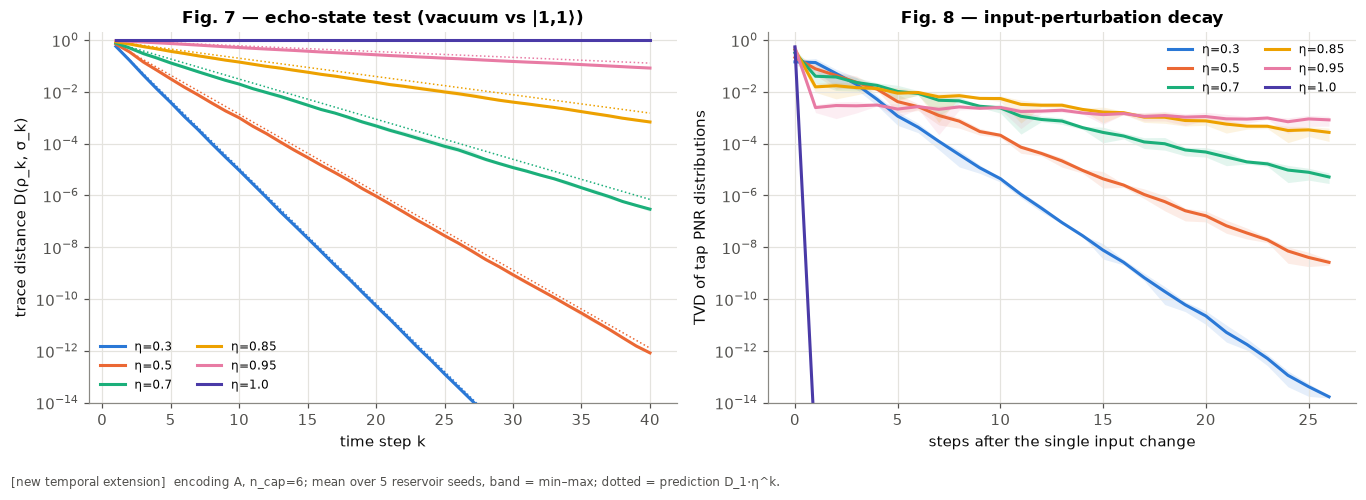

In [19]:
def fit_rate(D):
    k = np.arange(len(D)); ok = (D > 1e-12) & (D < 0.5)
    if ok.sum() < 4:
        return np.nan
    return -np.polyfit(k[ok], np.log(D[ok]), 1)[0]

with section("4.5 fading memory"):
    TE = P["t_echo_T"]; fm_rows, curves = [], {}
    for enc in ENCODINGS:
        for eta in P["t_eta"]:
            for s in t_seeds:
                res = TemporalDVReservoir(eta, s, enc, P["t_ncap"])
                u = np.random.default_rng([MASTER_SEED, 72, s]).uniform(size=TE)
                out = {}
                for pair, (c1, c2) in {"vac|11": ((0, 0), (1, 1)), "10|01": ((1, 0), (0, 1))}.items():
                    _, S1 = res.run(u, res.fock_state(c1), keep_states=True)
                    _, S2 = res.run(u, res.fock_state(c2), keep_states=True)
                    out[pair] = np.array([res.trace_distance(a, b) for a, b in zip(S1, S2)])
                k0 = TE // 3; u2 = u.copy(); u2[k0] = (u[k0] + 0.5) % 1.0
                Xa, Sa = res.run(u, keep_states=True); Xb, Sb = res.run(u2, keep_states=True)
                Dp = np.array([res.trace_distance(a, b) for a, b in zip(Sa, Sb)])[k0:]
                Tp = 0.5 * np.abs(Xa - Xb).sum(1)[k0:]
                curves[(enc, eta, s)] = dict(echo=out["vac|11"], echo2=out["10|01"], pert=Dp, pert_tvd=Tp)
                fm_rows.append(dict(encoding=enc, eta=eta, seed=s,
                                    D_echo_final=out["vac|11"][-1], rate_echo=fit_rate(out["vac|11"]),
                                    rate_echo2=fit_rate(out["10|01"]), rate_pert=fit_rate(Dp[1:]),
                                    tvd_at_k0=Tp[0], tvd_after_5=Tp[min(5, len(Tp) - 1)],
                                    frac_increase=np.mean(np.diff(out["vac|11"]) > 1e-12),
                                    predicted_rate=-math.log(eta) if 0 < eta < 1 else (np.inf if eta == 0 else 0.0)))
fm = pd.DataFrame(fm_rows)
fm_sum = fm.groupby(["encoding", "eta"]).agg(D_echo_final=("D_echo_final", "mean"), rate_echo=("rate_echo", "mean"),
          rate_echo_sd=("rate_echo", "std"), rate_pert=("rate_pert", "mean"), predicted=("predicted_rate", "first"),
          tvd_at_k0=("tvd_at_k0", "mean"), tvd_after_5=("tvd_after_5", "mean"), frac_increase=("frac_increase", "mean"))
def regime(r):
    if r.name[1] == 0: return "rapid forgetting (memory swapped every step)"
    if r.D_echo_final > 0.5: return "noncontractive (memory decoupled)"
    if r.predicted > 1.0: return "rapid forgetting"
    if r.predicted < 0.1: return "long-lived memory"
    return "useful fading memory"
fm_sum["regime"] = fm_sum.apply(regime, axis=1)
display(fm_sum.round(4))
RESULTS["fading"] = fm_sum

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3))
eta_show = [e for e in P["t_eta"] if e in (0.3, 0.5, 0.7, 0.85, 0.95, 1.0) or e == P["t_eta"][1]]
palette = [COL["qrp"], COL["pnr"], COL["aux"], COL["yel"], COL["mag"], COL["vio"], COL["grn"], COL["red"]]
for ci, eta in enumerate(eta_show):
    arr = np.array([curves[("A", eta, s)]["echo"] for s in t_seeds]); m = arr.mean(0)
    axs[0].semilogy(np.arange(1, TE + 1), np.clip(m, 1e-16, None), color=palette[ci % 8], label=f"η={eta}")
    axs[0].fill_between(np.arange(1, TE + 1), np.clip(arr.min(0), 1e-16, None), np.clip(arr.max(0), 1e-16, None), color=palette[ci % 8], alpha=0.12, lw=0)
    if 0 < eta < 1:
        axs[0].semilogy(np.arange(1, TE + 1), m[0] * eta ** np.arange(TE), ":", color=palette[ci % 8], lw=1)
    arrp = np.array([curves[("A", eta, s)]["pert_tvd"] for s in t_seeds]); mp = arrp.mean(0)
    axs[1].semilogy(np.arange(len(mp)), np.clip(mp, 1e-16, None), color=palette[ci % 8], label=f"η={eta}")
    axs[1].fill_between(np.arange(len(mp)), np.clip(arrp.min(0), 1e-16, None), np.clip(arrp.max(0), 1e-16, None), color=palette[ci % 8], alpha=0.12, lw=0)
axs[0].set(xlabel="time step k", ylabel="trace distance D(ρ_k, σ_k)", title="Fig. 7 — echo-state test (vacuum vs |1,1⟩)", ylim=(1e-14, 2))
axs[1].set(xlabel="steps after the single input change", ylabel="TVD of tap PNR distributions", title="Fig. 8 — input-perturbation decay", ylim=(1e-14, 2))
axs[0].legend(fontsize=8, ncol=2); axs[1].legend(fontsize=8, ncol=2)
tag_note(axs[0], f"encoding A, n_cap={P['t_ncap']}; mean over {len(t_seeds)} reservoir seeds, band = min–max; dotted = prediction D_1·η^k.",
         "new temporal extension")
plt.tight_layout(); plt.show()

## 4.6 Linear memory capacity

For each delay $\tau$, a separate ridge readout, with its own validation-selected $\lambda$, reconstructs $u_{k-\tau}$ from the PNR features $\mathbf x_k$. We compute $C_\tau=\mathrm{corr}^2(\hat u_{k-\tau},u_{k-\tau})$ on the **test** segment, and $MC=\sum_{\tau=1}^{\tau_{max}}C_\tau$. The present input, $C_0$, is reported separately.

* **Bias control:** the same pipeline is run on **time-shuffled** targets, which are independent of the features by construction. Their mean capacity measures the finite-sample bias. Their $(1-1/N_{null})$ quantile is the significance threshold $\theta$. Capacities below $\theta$ are set to 0 in the "thresholded" totals.
* **Bound:** for a linear readout, $\sum$ of capacities over orthogonal targets $\le r$, the numerical rank of the centred feature matrix. At most $r\le\#\text{outcomes}-1$, because the probabilities sum to one (Dambre et al. 2012).

[4.6 memory capacity] 7.3 s | RSS 374 MB | peak 388 MB


**Linear memory capacity** (τ = 1…15; test segment n=500; 5 reservoir seeds; MC_null = mean shuffled-target capacity × τ_max)

C0      MC   MC_sd  MC_thr  MC_null   theta  rank_bound
encoding eta                                                              
A        0.00  0.0008  0.7858  0.1435  0.7686   0.0302  0.0164         1.0
         0.30  0.7041  3.3087  0.5280  3.2942   0.0304  0.0181        35.0
         0.50  0.7735  2.8472  0.4057  2.8345   0.0302  0.0173        35.0
         0.70  0.7651  2.1660  0.3170  2.1455   0.0301  0.0180        35.0
         0.85  0.7691  2.2910  0.4888  2.2545   0.0309  0.0184        35.0
         0.95  0.7859  3.2586  0.7437  3.2520   0.0291  0.0167        35.0
         1.00  0.7423  0.0187  0.0063  0.0000   0.0291  0.0166         1.0
B        0.00  0.4462  0.0233  0.0092  0.0039   0.0298  0.0172         1.0
         0.30  0.8058  3.6922  0.4210  3.6723   0.0305  0.0185        33.0
         0.50  0.7892  3.8631  0.5089  3.8403   0.0301  0.0201        33.0
         0.70  0.7360  3.6264  0.8194  3.6125   0.0300  0.0178        33.0
         0.85  0.7204  2.8622  0.9452  2.8358   0.0296  0.0154        33.0
         0.95  0.6689  1.6997  0.7513  1.6613   0.0279  0.0160        33.0
         1.00  0.0000  0.0000  0.0000  0.0000   0.0000  0.0000         1.0

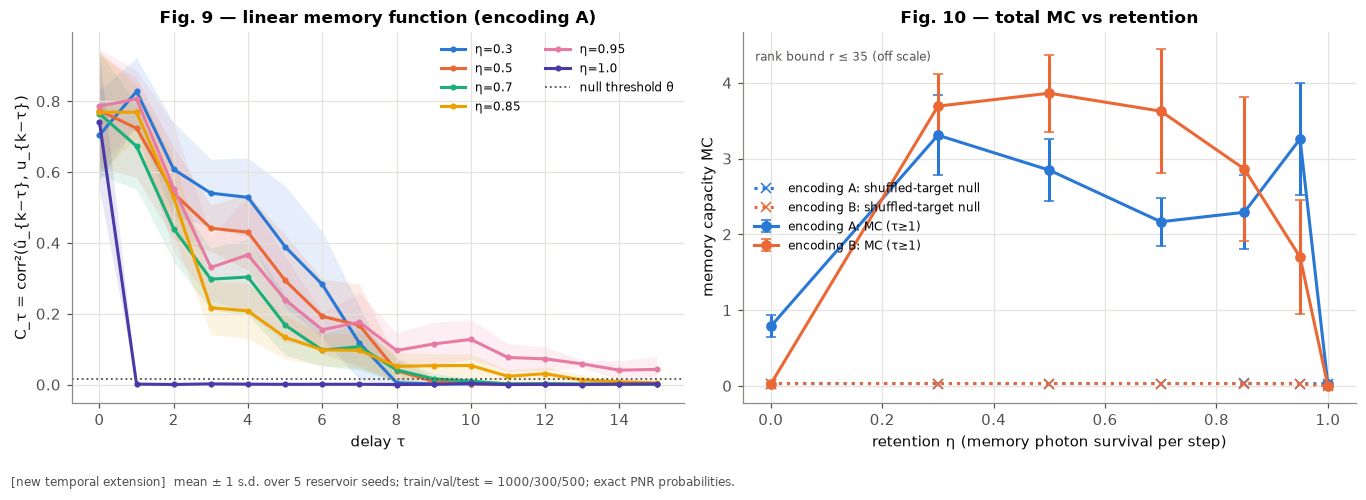

In [20]:
ALPHAS = np.logspace(-10, 1, 12)

def ridge_predict(X, Y, parts=PARTS, alphas=ALPHAS):
    """Batched ridge (one lambda per target chosen on validation MSE); returns test predictions and train rank."""
    tr, va, te = parts
    mu, sd = X[tr].mean(0), X[tr].std(0); sd = np.where(sd > 1e-12, sd, 1.0)
    Z = (X - mu) / sd; ym = Y[tr].mean(0)
    Uu, s, Vt = np.linalg.svd(Z[tr], full_matrices=False)
    UtY = Uu.T @ (Y[tr] - ym)
    best = np.full(Y.shape[1], np.inf); pred = np.zeros((te.stop - te.start, Y.shape[1]))
    for a in alphas:
        W = Vt.T @ ((s / (s ** 2 + a))[:, None] * UtY)
        mse = ((Z[va] @ W + ym - Y[va]) ** 2).mean(0); better = mse < best
        if better.any():
            best[better] = mse[better]; pred[:, better] = (Z[te] @ W[:, better]) + ym[better]
    return pred, int((s > 1e-10 * s[0]).sum())

def corr2(a, b):
    a = a - a.mean(0); b = b - b.mean(0)
    den = (a ** 2).sum(0) * (b ** 2).sum(0)
    return np.where(den > 1e-300, (a * b).sum(0) ** 2 / np.where(den > 0, den, 1), 0.0)

def delayed(u, taus):
    return np.stack([np.roll(u, t) for t in taus], 1)   # wrap-around only touches the washout (tau < T_W)

def shuffled_targets(Y, n, rng):
    cols = rng.integers(0, Y.shape[1], n); out = np.empty((Y.shape[0], n))
    for j, c in enumerate(cols):
        out[:, j] = Y[rng.permutation(Y.shape[0]), c]
    return out

with section("4.6 memory capacity"):
    taus = np.arange(0, P["tau_max"] + 1); mc_rows, mc_curves = [], {}
    for (enc, eta, s), X in RUNS.items():
        Y = delayed(U_SEQ[s], taus)
        Yn = shuffled_targets(Y, P["n_null"], np.random.default_rng([MASTER_SEED, 73, s]))
        pred, rank = ridge_predict(X, np.hstack([Y, Yn]))
        C = corr2(pred[:, :len(taus)], Y[PARTS[2]]); Cn = corr2(pred[:, len(taus):], Yn[PARTS[2]])
        theta = np.quantile(Cn, 1 - 1 / len(Cn))
        mc_curves[(enc, eta, s)] = C
        mc_rows.append(dict(encoding=enc, eta=eta, seed=s, C0=C[0], MC=C[1:].sum(), MC_thr=C[1:][C[1:] > theta].sum(),
                            MC_null=Cn.mean() * P["tau_max"], theta=theta, rank=rank))
mcdf = pd.DataFrame(mc_rows)
mc_sum = mcdf.groupby(["encoding", "eta"]).agg(C0=("C0", "mean"), MC=("MC", "mean"), MC_sd=("MC", "std"),
          MC_thr=("MC_thr", "mean"), MC_null=("MC_null", "mean"), theta=("theta", "mean"), rank_bound=("rank", "median"))
display(Markdown(f"**Linear memory capacity** (τ = 1…{P['tau_max']}; test segment n={T_TE}; {len(t_seeds)} reservoir seeds; "
                 f"MC_null = mean shuffled-target capacity × τ_max)")); display(mc_sum.round(4))
assert (mcdf.MC <= mcdf["rank"] + 0.5).all(), "MC exceeds the rank bound"
RESULTS["mc"] = mc_sum

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3))
for ci, eta in enumerate(eta_show):
    arr = np.array([mc_curves[("A", eta, s)] for s in t_seeds])
    axs[0].plot(taus, arr.mean(0), "o-", ms=3, color=palette[ci % 8], label=f"η={eta}")
    axs[0].fill_between(taus, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=palette[ci % 8], alpha=0.12, lw=0)
axs[0].axhline(mcdf.theta.mean(), color=COL["ink2"], ls=":", lw=1.2, label="null threshold θ")
axs[0].set(xlabel="delay τ", ylabel="C_τ = corr²(û_{k−τ}, u_{k−τ})", title="Fig. 9 — linear memory function (encoding A)")
axs[0].legend(fontsize=8, ncol=2)
for enc, col in zip(ENCODINGS, [COL["qrp"], COL["pnr"]]):
    d = mc_sum.loc[enc]
    axs[1].errorbar(d.index, d.MC, d.MC_sd.fillna(0), fmt="o-", color=col, capsize=3, label=f"encoding {enc}: MC (τ≥1)")
    axs[1].plot(d.index, d.MC_null, "x:", color=col, label=f"encoding {enc}: shuffled-target null")
axs[1].text(0.02, 0.95, f"rank bound r ≤ {int(mc_sum.rank_bound.max())} (off scale)", transform=axs[1].transAxes, color=COL["ink2"], fontsize=8, va="top")
axs[1].set(xlabel="retention η (memory photon survival per step)", ylabel="memory capacity MC", title="Fig. 10 — total MC vs retention")
axs[1].legend(fontsize=8)
tag_note(axs[0], f"mean ± 1 s.d. over {len(t_seeds)} reservoir seeds; train/val/test = {T_TR}/{T_VA}/{T_TE}; exact PNR probabilities.",
         "new temporal extension")
plt.tight_layout(); plt.show()

## 4.7 Information processing capacity (IPC)

Following Dambre et al. (2012), targets are products of **normalised Legendre polynomials** of delayed inputs:
$$y_k=\prod_i\tilde P_{d_i}(s_{k-\tau_i}),\qquad s=2u-1\sim U[-1,1],\qquad \tilde P_d=\sqrt{2d+1}\,P_d .$$
These satisfy $\mathbb E[\tilde P_d\tilde P_{d'}]=\delta_{dd'}$ for the uniform input law. Each target is a set of *distinct* delays $\tau_i\in\{0,\dots,\tau_{max}\}$ with degrees $d_i\ge1$ and $\sum_i d_i=D\le D_{max}$. Enumerating them as sets gives no duplicate products. Degree 0, the constant, is only a consistency check: with an intercept its prediction is exact and it is excluded from the totals.

Orthonormality is verified numerically with z-scores of the empirical Gram matrix. Each target gets its own readout and validation-chosen $\lambda$. Capacity is test-set $\mathrm{corr}^2$, thresholded at the shuffled-null $(1-1/N_{null})$ quantile, so the expected number of false positives is $\approx N_{targets}/N_{null}$. The totals are compared with the rank bound $r$.

[budget] 4.7 IPC: largest Fock sector dim = 792, circuit evaluations ≈ 38,780, estimated ≈ 0 s
54 targets (degree counts {np.int64(1): np.int64(9), np.int64(2): np.int64(45)}); orthonormality: max|G−I| = 0.143, max z = 2.65 → PASS
degree-0 target: max |ŷ − 1| on test = 0.0e+00


[4.7 IPC] 8.2 s | RSS 381 MB | peak 395 MB


**IPC** (max degree 2, delays 0…8, 54 targets, 500 shuffled nulls per run; test n=500; mean over 5 seeds)

deg1    deg2  deg2_single  deg2_cross      IPC  IPC_raw  \
encoding eta                                                               
A        0.00  0.7686  0.1590       0.1590      0.0000   0.9275   1.0252   
         0.30  3.9982  6.0292       1.7636      4.2656  10.0274  10.0869   
         0.50  3.6017  5.7185       1.4898      4.2287   9.3202   9.3843   
         0.70  2.8925  4.2834       1.1255      3.1579   7.1759   7.2654   
         0.85  2.8708  3.9536       1.2068      2.7467   6.8243   6.9152   
         0.95  3.5100  3.6276       1.4490      2.1785   7.1376   7.2493   
         1.00  0.7423  0.1675       0.1675      0.0000   0.9099   1.0045   
B        0.00  0.4499  0.5524       0.5491      0.0033   1.0024   1.1047   
         0.30  4.4781  5.1142       1.7171      3.3971   9.5923   9.6771   
         0.50  4.6295  5.1128       1.5072      3.6056   9.7423   9.8327   
         0.70  4.2811  4.6188       1.2254      3.3934   8.8998   9.0031   
         0.85  3.4026  3.1365       0.9766      2.1598   6.5391   6.6372   
         0.95  2.2664  1.5741       0.7375      0.8366   3.8404   3.9676   
         1.00  0.0000  0.0000       0.0000      0.0000   0.0000   0.0000   

               null_total  n_significant  rank   theta  IPC_sd  
encoding eta                                                    
A        0.00      0.1137            2.0   1.0  0.0161  0.0796  
         0.30      0.1057           36.4  35.0  0.0160  1.1354  
         0.50      0.1071           39.2  35.0  0.0185  1.0168  
         0.70      0.1139           37.2  35.0  0.0195  0.7096  
         0.85      0.1215           38.8  35.0  0.0185  0.5459  
         0.95      0.1158           33.0  35.0  0.0174  0.7455  
         1.00      0.1078            2.0   1.0  0.0170  0.0996  
B        0.00      0.1098            2.0   1.0  0.0157  0.0125  
         0.30      0.1134           25.2  32.6  0.0186  1.0612  
         0.50      0.1122           29.0  33.0  0.0184  1.1358  
         0.70      0.1123           28.8  33.0  0.0198  1.5191  
         0.85      0.1089           29.0  33.2  0.0172  1.5660  
         0.95      0.1031           19.0  31.4  0.0164  1.2394  
         1.00      0.0000            1.4   1.0  0.0000  0.0000

total IPC ≤ rank bound for every run: True; max IPC/rank = 1.014


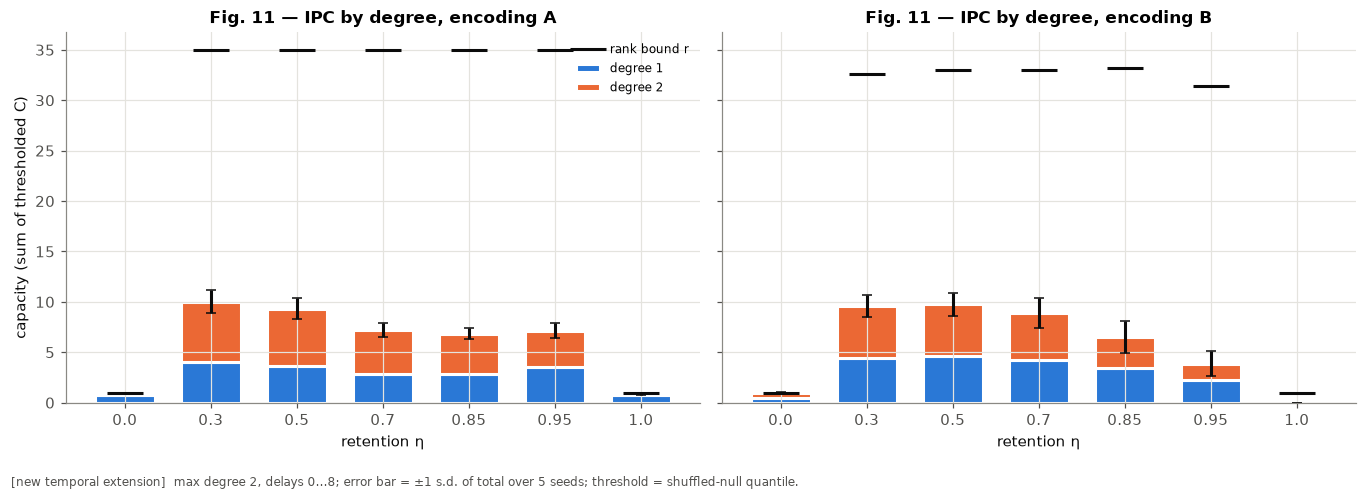

In [21]:
from numpy.polynomial import legendre as npleg

def ipc_targets(u, max_deg, max_delay):
    s = 2 * u - 1
    Pd = {d: math.sqrt(2 * d + 1) * npleg.legval(s, [0] * d + [1]) for d in range(1, max_deg + 1)}
    specs = []
    def rec(tau, remaining, cur):
        if tau > max_delay:
            if sum(d for _, d in cur) > 0:
                specs.append(tuple(cur))
            return
        rec(tau + 1, remaining, cur)
        for d in range(1, remaining + 1):
            rec(tau + 1, remaining - d, cur + [(tau, d)])
    rec(0, max_deg, [])
    Y = np.stack([np.prod([np.roll(Pd[d], t) for t, d in sp], 0) for sp in specs], 1)
    deg = np.array([sum(d for _, d in sp) for sp in specs])
    return Y, deg, specs

with section("4.7 IPC"):
    ipc_rows, ipc_detail = [], {}
    _, deg_chk, specs_chk = ipc_targets(U_SEQ[t_seeds[0]], P["ipc_degree"], P["ipc_delay"])
    assert len(set(specs_chk)) == len(specs_chk), "duplicate IPC targets"
    budget("4.7 IPC", hilbert_dim=n_sector, n_evals=len(RUNS) * (len(specs_chk) + P["n_null"]), sec_per_eval=2e-6)
    # orthonormality check on the test segment of one run
    Ychk, _, _ = ipc_targets(U_SEQ[t_seeds[0]], P["ipc_degree"], P["ipc_delay"]); Yt = Ychk[PARTS[2]]
    G = Yt.T @ Yt / len(Yt); prod_sd = np.sqrt(np.clip((Yt ** 2).T @ (Yt ** 2) / len(Yt) - G ** 2, 1e-300, None))
    zG = np.abs(G - np.eye(len(G))) / (prod_sd / math.sqrt(len(Yt)))
    ortho_ok = zG.max() < 6.0
    print(f"{len(specs_chk)} targets (degree counts {dict(zip(*np.unique(deg_chk, return_counts=True)))}); "
          f"orthonormality: max|G−I| = {np.abs(G - np.eye(len(G))).max():.3f}, max z = {zG.max():.2f} → {'PASS' if ortho_ok else 'FAIL'}")
    # degree-0 consistency: constant target is reproduced exactly by the intercept
    pred0, _ = ridge_predict(RUNS[(ENCODINGS[0], P["t_eta"][1], t_seeds[0])], np.ones((T_ALL, 1)))
    print(f"degree-0 target: max |ŷ − 1| on test = {np.abs(pred0 - 1).max():.1e}")
    for (enc, eta, s), X in RUNS.items():
        Y, deg, specs = ipc_targets(U_SEQ[s], P["ipc_degree"], P["ipc_delay"])
        Yn = shuffled_targets(Y, P["n_null"], np.random.default_rng([MASTER_SEED, 74, s]))
        pred, rank = ridge_predict(X, np.hstack([Y, Yn]))
        C = corr2(pred[:, :Y.shape[1]], Y[PARTS[2]]); Cn = corr2(pred[:, Y.shape[1]:], Yn[PARTS[2]])
        theta = np.quantile(Cn, 1 - 1 / len(Cn)); Ct = np.where(C > theta, C, 0.0)
        row = dict(encoding=enc, eta=eta, seed=s, rank=rank, theta=theta, IPC=Ct.sum(), IPC_raw=C.sum(),
                   null_total=Cn.mean() * len(C), n_significant=int((C > theta).sum()), n_targets=len(C))
        for D in range(1, P["ipc_degree"] + 1):
            row[f"deg{D}"] = Ct[deg == D].sum()
        cross2 = np.array([len(sp) > 1 for sp in specs]) & (deg == 2)
        row["deg2_cross"] = Ct[cross2].sum(); row["deg2_single"] = Ct[(deg == 2) & ~cross2].sum()
        ipc_rows.append(row); ipc_detail[(enc, eta, s)] = (C, specs)
ipcdf = pd.DataFrame(ipc_rows)
cols = [f"deg{D}" for D in range(1, P["ipc_degree"] + 1)]
ipc_sum = ipcdf.groupby(["encoding", "eta"])[cols + ["deg2_single", "deg2_cross", "IPC", "IPC_raw", "null_total", "n_significant", "rank", "theta"]].mean()
ipc_sum["IPC_sd"] = ipcdf.groupby(["encoding", "eta"]).IPC.std()
display(Markdown(f"**IPC** (max degree {P['ipc_degree']}, delays 0…{P['ipc_delay']}, {len(specs_chk)} targets, "
                 f"{P['n_null']} shuffled nulls per run; test n={T_TE}; mean over {len(t_seeds)} seeds)"))
display(ipc_sum.round(4))
bound_ok = (ipcdf.IPC <= ipcdf["rank"] + 0.5).all()
print(f"total IPC ≤ rank bound for every run: {bound_ok}; max IPC/rank = {(ipcdf.IPC / ipcdf['rank']).max():.3f}")
RESULTS["ipc"] = ipc_sum; RESULTS["ipc_ok"] = dict(ortho=ortho_ok, bound=bound_ok, null=float(ipcdf.null_total.mean()))

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
deg_cols = [COL["qrp"], COL["pnr"], COL["aux"], COL["yel"]]
for ax, enc in zip(axs, ENCODINGS):
    d = ipc_sum.loc[enc]; x = np.arange(len(d)); bottom = np.zeros(len(d))
    for D, c in zip(range(1, P["ipc_degree"] + 1), deg_cols):
        ax.bar(x, d[f"deg{D}"], 0.7, bottom=bottom, color=c, label=f"degree {D}", edgecolor="white", linewidth=2)
        bottom += d[f"deg{D}"].values
    ax.errorbar(x, d.IPC, ipcdf[ipcdf.encoding == enc].groupby("eta").IPC.std().fillna(0).values, fmt="none", ecolor=COL["ink"], capsize=3)
    ax.plot(x, d["rank"], "_", color=COL["ink"], ms=24, mew=2, label="rank bound r")
    ax.set_xticks(x, [str(e) for e in d.index]); ax.set(xlabel="retention η", title=f"Fig. 11 — IPC by degree, encoding {enc}")
axs[0].set_ylabel("capacity (sum of thresholded C)"); axs[0].legend(fontsize=8)
tag_note(axs[0], f"max degree {P['ipc_degree']}, delays 0…{P['ipc_delay']}; error bar = ±1 s.d. of total over {len(t_seeds)} seeds; "
         f"threshold = shuffled-null quantile.", "new temporal extension")
plt.tight_layout(); plt.show()

## 4.8 Temporal benchmarks

**Tasks.**
* **NARMA10:** $y_{k}=0.3y_{k-1}+0.05y_{k-1}\sum_{i=1}^{10}y_{k-i}+1.5u_{k-10}u_{k-1}+0.1$, with $u\sim U[0,0.5]$.
* **Delayed product:** $y_k=u_{k-1}u_{k-3}$, with $u\sim U[0,1]$.

Delayed parity is optional and omitted: it would need binary-input runs.

**Models**, all with a ridge readout fitted on training data. Every hyperparameter is selected on the validation segment, and results are reported on test.
* constant mean;
* linear autoregression on $L$ lags, $L$ selected;
* the **no-feedback photonic model** ($\eta=1$: memory decoupled, so features depend on $u_k$ only);
* the **recurrent DV photonic reservoir** ($\eta$ selected per seed);
* a classical tanh **echo-state network** with $N$ = number of photonic features. Spectral radius and input scaling are selected; the reservoir seed is shared.

**Metric:** NMSE $=\langle(\hat y-y)^2\rangle/\mathrm{Var}(y)$ on test, mean ± s.d. over seeds. The trainable parameter count is readout weights + bias.

[4.8 benchmarks] 1.8 s | RSS 355 MB | peak 395 MB


NMSE_mean  \
task                         model                                          
NARMA10                      classical ESN (N=36)                  0.2158   
                             constant mean                         1.0750   
                             linear AR                             0.1705   
                             photonic no-feedback (η=1), enc A     1.0773   
                             photonic no-feedback (η=1), enc B     1.0750   
                             photonic recurrent, enc A             0.6315   
                             photonic recurrent, enc B             0.6899   
delayed product u(k-1)u(k-3) classical ESN (N=36)                  0.0026   
                             constant mean                         1.0108   
                             linear AR                             0.1512   
                             photonic no-feedback (η=1), enc A     1.0114   
                             photonic no-feedback (η=1), enc B     1.0108   
                             photonic recurrent, enc A             0.3512   
                             photonic recurrent, enc B             0.2847   

                                                                NMSE_sd  \
task                         model                                        
NARMA10                      classical ESN (N=36)                0.0307   
                             constant mean                       0.1006   
                             linear AR                           0.0076   
                             photonic no-feedback (η=1), enc A   0.0986   
                             photonic no-feedback (η=1), enc B   0.1006   
                             photonic recurrent, enc A           0.1427   
                             photonic recurrent, enc B           0.0628   
delayed product u(k-1)u(k-3) classical ESN (N=36)                0.0006   
                             constant mean                       0.0131   
                             linear AR                           0.0147   
                             photonic no-feedback (η=1), enc A   0.0127   
                             photonic no-feedback (η=1), enc B   0.0131   
                             photonic recurrent, enc A           0.0982   
                             photonic recurrent, enc B           0.0632   

                                                                params  \
task                         model                                       
NARMA10                      classical ESN (N=36)                   37   
                             constant mean                           1   
                             linear AR                              21   
                             photonic no-feedback (η=1), enc A      37   
                             photonic no-feedback (η=1), enc B      37   
                             photonic recurrent, enc A              37   
                             photonic recurrent, enc B              37   
delayed product u(k-1)u(k-3) classical ESN (N=36)                   37   
                             constant mean                           1   
                             linear AR                               6   
                             photonic no-feedback (η=1), enc A      37   
                             photonic no-feedback (η=1), enc B      37   
                             photonic recurrent, enc A              37   
                             photonic recurrent, enc B              37   

                                                                fit_seconds  \
task                         model                                            
NARMA10                      classical ESN (N=36)                    0.1426   
                             constant mean                           0.0000   
                             linear AR                               0.0045   
                             photonic no-feedback 

diverged NARMA10/target series excluded: 0 of 10 (task, seed) pairs []
photonic run time per sequence (exact channel): 2.78 s for 1900 steps (not included in fit_seconds)


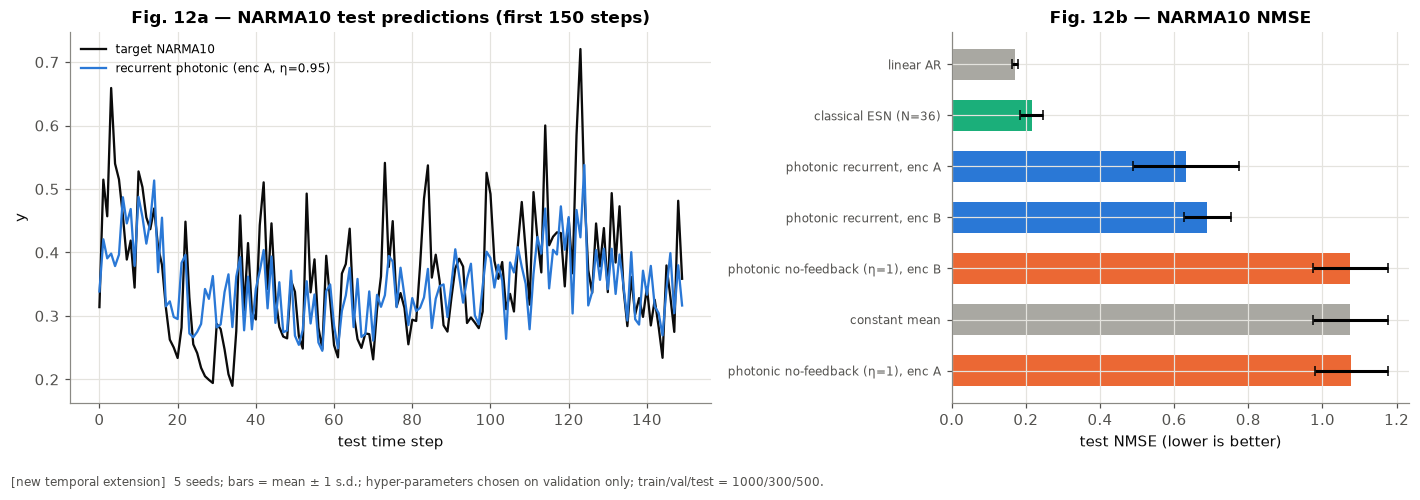

In [22]:
def narma10(u):
    """NARMA10; long sequences occasionally diverge (a known property of the recursion) -> returns non-finite y."""
    y = np.zeros(len(u))
    with np.errstate(over="ignore", invalid="ignore"):
        for k in range(10, len(u)):
            y[k] = 0.3 * y[k - 1] + 0.05 * y[k - 1] * y[k - 10:k].sum() + 1.5 * u[k - 10] * u[k - 1] + 0.1
            if not abs(y[k]) < 1e3:
                y[k:] = np.nan
                break
    return y

def nmse(pred, y):
    return float(((pred - y) ** 2).mean() / y.var())

def esn_states(u, N, rho, scale, seed):
    r = np.random.default_rng(seed)
    W = r.normal(size=(N, N)); W *= rho / np.abs(np.linalg.eigvals(W)).max()
    Win = r.uniform(-1, 1, N) * scale; b = r.uniform(-0.2, 0.2, N)
    x = np.zeros(N); S = np.empty((len(u), N))
    for k, uk in enumerate(u):
        x = np.tanh(W @ x + Win * (uk - 0.5) * 2 + b); S[k] = x
    return S

def val_test_nmse(X, y):
    """Validation and test NMSE of a ridge readout (lambda selected on validation); NaN for a diverged target."""
    tr, va, te = PARTS
    if not np.isfinite(y).all():
        return np.nan, np.nan, np.full(te.stop - te.start, np.nan)
    mu, sd = X[tr].mean(0), X[tr].std(0); sd = np.where(sd > 1e-12, sd, 1.0); Z = (X - mu) / sd
    ym = y[tr].mean(); Uu, s, Vt = np.linalg.svd(Z[tr], full_matrices=False); UtY = Uu.T @ (y[tr] - ym)
    best = (np.inf, None)
    for a in ALPHAS:
        W = Vt.T @ (s / (s ** 2 + a) * UtY); v = nmse(Z[va] @ W + ym, y[va])
        if v < best[0]:
            best = (v, W)
    return best[0], nmse(Z[te] @ best[1] + ym, y[te]), Z[te] @ best[1] + ym

TASKS = {"NARMA10": lambda u: narma10(u / 2), "delayed product u(k-1)u(k-3)": lambda u: np.roll(u, 1) * np.roll(u, 3)}
with section("4.8 benchmarks"):
    bench_rows, snippets, diverged = [], {}, []
    n_feat = len(_r.tap_basis)
    for s in t_seeds:
        u = U_SEQ[s]
        for task, f in TASKS.items():
            y = f(u); t0 = time.perf_counter()
            if not np.isfinite(y).all():
                diverged.append((task, s)); continue   # excluded and reported below
            bench_rows.append(dict(task=task, seed=s, model="constant mean", nmse=nmse(np.full(T_TE, y[PARTS[0]].mean()), y[PARTS[2]]),
                                   params=1, seconds=0.0))
            t0 = time.perf_counter(); best = (np.inf,)
            for L in [1, 2, 3, 5, 10, 15, 20]:
                vv, tt_, _ = val_test_nmse(delayed(u, range(L)), y)
                if vv < best[0]: best = (vv, tt_, L)
            bench_rows.append(dict(task=task, seed=s, model="linear AR", nmse=best[1], params=best[2] + 1,
                                   seconds=time.perf_counter() - t0, hyper=f"L={best[2]}"))
            t0 = time.perf_counter(); best = (np.inf,)
            for rho_ in [0.3, 0.6, 0.9, 1.1]:
                for sc in [0.1, 0.5, 1.0]:
                    vv, tt_, pr = val_test_nmse(esn_states(u, n_feat, rho_, sc, s), y)
                    if vv < best[0]: best = (vv, tt_, f"ρ={rho_}, in={sc}", pr)
            bench_rows.append(dict(task=task, seed=s, model=f"classical ESN (N={n_feat})", nmse=best[1], params=n_feat + 1,
                                   seconds=time.perf_counter() - t0, hyper=best[2]))
            for enc in ENCODINGS:
                vv, tt_, pr = val_test_nmse(RUNS[(enc, 1.0, s)], y)
                bench_rows.append(dict(task=task, seed=s, model=f"photonic no-feedback (η=1), enc {enc}", nmse=tt_, params=n_feat + 1, seconds=0.0))
                best = (np.inf,)
                for eta in P["t_eta"]:
                    vv, tt_, pr = val_test_nmse(RUNS[(enc, eta, s)], y)
                    if vv < best[0]: best = (vv, tt_, eta, pr)
                bench_rows.append(dict(task=task, seed=s, model=f"photonic recurrent, enc {enc}", nmse=best[1], params=n_feat + 1,
                                       seconds=0.0, hyper=f"η={best[2]}"))
                if (task, enc) not in snippets:
                    snippets[(task, enc)] = (y[PARTS[2]], best[3], best[2])
bench = pd.DataFrame(bench_rows)
bench_sum = bench.groupby(["task", "model"]).agg(NMSE_mean=("nmse", "mean"), NMSE_sd=("nmse", "std"), params=("params", "first"),
                                                 fit_seconds=("seconds", "mean"), hyper=("hyper", lambda x: ", ".join(sorted(set(map(str, x.dropna()))))))
display(bench_sum.round(4))
print(f"diverged NARMA10/target series excluded: {len(diverged)} of {len(t_seeds) * len(TASKS)} (task, seed) pairs {diverged}")
RESULTS["bench"] = bench_sum
print("photonic run time per sequence (exact channel): "
      f"{per_step * T_ALL:.2f} s for {T_ALL} steps (not included in fit_seconds)")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw=dict(width_ratios=[1.4, 1]))
y_te, pr, eta_b = snippets[("NARMA10", "A")]
axs[0].plot(np.arange(150), y_te[:150], color=COL["ink"], lw=1.5, label="target NARMA10")
axs[0].plot(np.arange(150), pr[:150], color=COL["qrp"], lw=1.5, label=f"recurrent photonic (enc A, η={eta_b})")
axs[0].set(xlabel="test time step", ylabel="y", title="Fig. 12a — NARMA10 test predictions (first 150 steps)"); axs[0].legend(fontsize=8)
d = bench_sum.loc["NARMA10"].sort_values("NMSE_mean")
axs[1].barh(np.arange(len(d)), d.NMSE_mean, xerr=d.NMSE_sd.fillna(0), color=[COL["qrp"] if "recurrent" in m else COL["pnr"] if "photonic" in m else COL["aux"] if "ESN" in m else "#a9a8a2" for m in d.index],
            height=0.6, capsize=3)
axs[1].set_yticks(np.arange(len(d)), d.index, fontsize=8); axs[1].invert_yaxis()
axs[1].set(xlabel="test NMSE (lower is better)", title="Fig. 12b — NARMA10 NMSE")
tag_note(axs[0], f"{len(t_seeds)} seeds; bars = mean ± 1 s.d.; hyper-parameters chosen on validation only; train/val/test = {T_TR}/{T_VA}/{T_TE}.",
         "new temporal extension")
plt.tight_layout(); plt.show()

## 4.9 Loss, and exact versus finite-shot readout

**Loss.** Unmonitored loss $\gamma$ is added on both memory modes at the best retention.

**Finite shots.** A finite-shot feature vector at step $k$ is the empirical PNR histogram from $M$ **independent repetitions of the whole temporal experiment**. Each repetition is one measurement-conditioned trajectory (`run_trajectories`). Every tap outcome is drawn from the Born rule given the trajectory's own past record, and the memory collapses accordingly. Unconditional single-time marginals are never resampled independently. Averaged over trajectories this reproduces the exact channel, as test T4 checks. We compare, versus $M$:
* the RMS error of the features, with the $M^{-1/2}$ trend fitted;
* MC, and NARMA10 NMSE, with readouts trained and tested on sampled features.

η* (largest mean MC, encoding A) = 0.3


**Effect of unmonitored memory loss γ** (encoding A; 5 seeds)

MC         NARMA_NMSE        
              mean     std       mean     std
eta  gamma                                   
0.30 0.0    3.3087  0.5280     0.8186  0.0709
     0.1    3.3862  0.5476     0.8180  0.0694
     0.3    3.4532  0.5742     0.8281  0.0646
0.85 0.0    2.2910  0.4888     0.6766  0.0903
     0.1    2.1396  0.3133     0.7162  0.1124
     0.3    2.6354  0.3133     0.7902  0.1140

[budget] 4.9 trajectories: largest Fock sector dim = 792, circuit evaluations ≈ 2,420,000, estimated ≈ 7 s


median over PNR outcomes of (input-driven temporal s.d. of p) / (shot-noise s.d.): M=100: 0.90, M=1000: 2.85


[4.9 loss & finite shots] 40.9 s | RSS 369 MB | peak 395 MB


**Exact vs finite-shot** (η*=0.3, enc A, 2 seeds, sequence 1100 steps)

feat_rmse              MC         NARMA_NMSE        
                    mean     std    mean     std       mean     std
readout M                                                          
M=100   100.0     0.0145  0.0002  0.8245  0.0714     0.9924  0.0230
M=1000  1000.0    0.0047  0.0000  1.5331  0.2848     0.8635  0.0386
exact   inf       0.0000  0.0000  3.3083  1.1135     0.8346  0.0184

fitted feature-error scaling: RMSE ∝ M^-0.491 (expected −0.5)


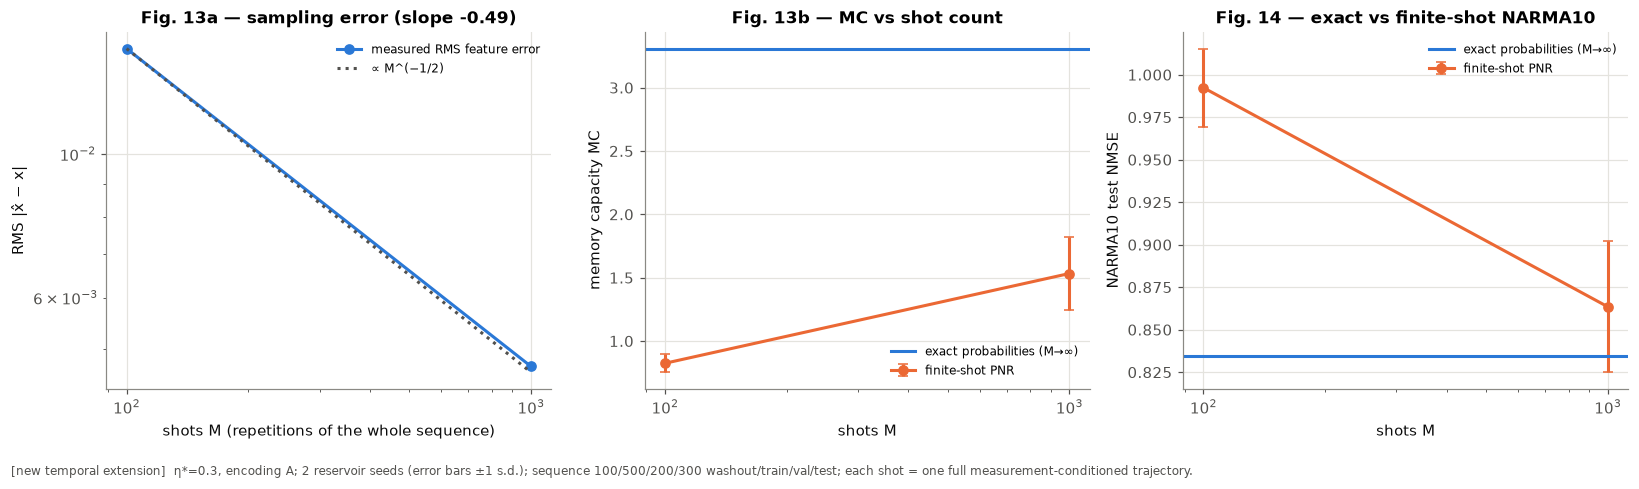

In [23]:
with section("4.9 loss & finite shots"):
    enc_s = "A"
    eta_star = float(pd.Series({e: mc_sum.loc[(enc_s, e)].MC for e in P["t_eta"] if e < 1}).idxmax())
    print(f"η* (largest mean MC, encoding {enc_s}) = {eta_star}")
    gammas = [0.0, 0.1, 0.3] if RUN_MODE == "quick" else [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
    loss_rows = []
    eta_loss = sorted({eta_star, 0.85})   # the MC-optimal retention and a high-retention point
    for eta_l in eta_loss:
        for g in gammas:
            for s in t_seeds:
                X = TemporalDVReservoir(eta_l, s, enc_s, P["t_ncap"], gamma=g).run(U_SEQ[s])
                pred, rank = ridge_predict(X, delayed(U_SEQ[s], taus))
                loss_rows.append(dict(eta=eta_l, gamma=g, seed=s, MC=corr2(pred, delayed(U_SEQ[s], taus)[PARTS[2]])[1:].sum(),
                                      NARMA_NMSE=val_test_nmse(X, TASKS["NARMA10"](U_SEQ[s]))[1]))
    loss_sum = pd.DataFrame(loss_rows).groupby(["eta", "gamma"])[["MC", "NARMA_NMSE"]].agg(["mean", "std"])
    display(Markdown(f"**Effect of unmonitored memory loss γ** (encoding {enc_s}; {len(t_seeds)} seeds)")); display(loss_sum.round(4))

    # finite shots: shorter sequences (declared in the profile) to bound the trajectory cost
    w_, tr_, va_, te_ = P["shot_T"]; Ts = w_ + tr_ + va_ + te_
    parts_s = (slice(w_, w_ + tr_), slice(w_ + tr_, w_ + tr_ + va_), slice(w_ + tr_ + va_, Ts))
    budget("4.9 trajectories", hilbert_dim=n_sector, n_evals=P["shot_seeds"] * sum(P["shots"]) * Ts, sec_per_eval=3e-6)
    shot_rows = []
    for si, s in enumerate(t_seeds[:P["shot_seeds"]]):
        res = TemporalDVReservoir(eta_star, s, enc_s, P["t_ncap"])
        u = np.random.default_rng([MASTER_SEED, 75, s]).uniform(size=Ts); y_n = TASKS["NARMA10"](u)
        Xe = res.run(u); Yd = delayed(u, taus)
        noise_sd = np.sqrt(np.clip(Xe * (1 - Xe), 0, None))
        live = Xe[parts_s[0]].mean(0) > 1e-3
        snr = {M: np.median(Xe[parts_s[0]][:, live].std(0) / (noise_sd[parts_s[0]][:, live].mean(0) / math.sqrt(M))) for M in P["shots"]}
        if si == 0:
            print("median over PNR outcomes of (input-driven temporal s.d. of p) / (shot-noise s.d.): "
                  + ", ".join(f"M={M}: {v:.2f}" for M, v in snr.items()))
        variants = [("exact", np.inf, Xe)] + [(f"M={M}", M, res.run_trajectories(u, M, np.random.default_rng([MASTER_SEED, 76, s, M])))
                                              for M in P["shots"]]
        for name, M, Xs in variants:
            pred, _ = ridge_predict(Xs, Yd, parts_s)
            tr_s, va_s, te_s = parts_s
            mu, sd = Xs[tr_s].mean(0), Xs[tr_s].std(0); sd = np.where(sd > 1e-12, sd, 1.0); Z = (Xs - mu) / sd
            ym = y_n[tr_s].mean(); Uu, sv, Vt = np.linalg.svd(Z[tr_s], full_matrices=False); UtY = Uu.T @ (y_n[tr_s] - ym)
            best = (np.inf, np.inf)
            for a in ALPHAS:
                W = Vt.T @ (sv / (sv ** 2 + a) * UtY); v = nmse(Z[va_s] @ W + ym, y_n[va_s])
                if v < best[0]: best = (v, nmse(Z[te_s] @ W + ym, y_n[te_s]))
            shot_rows.append(dict(seed=s, readout=name, M=M, feat_rmse=np.sqrt(((Xs - Xe) ** 2).mean()),
                                  MC=corr2(pred, Yd[te_s])[1:].sum(), NARMA_NMSE=best[1] if np.isfinite(y_n).all() else np.nan))
shots_df = pd.DataFrame(shot_rows)
shot_sum = shots_df.groupby(["readout", "M"])[["feat_rmse", "MC", "NARMA_NMSE"]].agg(["mean", "std"]).sort_index(level=1)
display(Markdown(f"**Exact vs finite-shot** (η*={eta_star}, enc {enc_s}, {P['shot_seeds']} seeds, sequence {Ts} steps)")); display(shot_sum.round(4))
fin = shots_df[np.isfinite(shots_df.M)]
slope = np.polyfit(np.log(fin.M), np.log(fin.feat_rmse), 1)[0]
print(f"fitted feature-error scaling: RMSE ∝ M^{slope:.3f} (expected −0.5)")
RESULTS["shots"] = dict(table=shot_sum, slope=slope, eta_star=eta_star, loss=loss_sum)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
Ms = np.array(sorted(fin.M.unique())); g = fin.groupby("M")
axs[0].loglog(Ms, g.feat_rmse.mean(), "o-", color=COL["qrp"], label="measured RMS feature error")
axs[0].loglog(Ms, g.feat_rmse.mean().iloc[0] * (Ms / Ms[0]) ** -0.5, ":", color=COL["ink2"], label="∝ M^(−1/2)")
axs[0].set(xlabel="shots M (repetitions of the whole sequence)", ylabel="RMS |x̂ − x|", title=f"Fig. 13a — sampling error (slope {slope:.2f})")
ex = shots_df[shots_df.readout == "exact"]
for ax, col, lab in [(axs[1], "MC", "memory capacity MC"), (axs[2], "NARMA_NMSE", "NARMA10 test NMSE")]:
    ax.errorbar(Ms, g[col].mean(), g[col].std().fillna(0), fmt="o-", color=COL["pnr"], capsize=3, label="finite-shot PNR")
    ax.axhline(ex[col].mean(), color=COL["qrp"], lw=2, label="exact probabilities (M→∞)")
    ax.set_xscale("log"); ax.set(xlabel="shots M", ylabel=lab)
axs[1].set_title("Fig. 13b — MC vs shot count"); axs[2].set_title("Fig. 14 — exact vs finite-shot NARMA10")
for ax in axs: ax.legend(fontsize=8)
tag_note(axs[0], f"η*={eta_star}, encoding A; {P['shot_seeds']} reservoir seeds (error bars ±1 s.d.); sequence {w_}/{tr_}/{va_}/{te_} "
         "washout/train/val/test; each shot = one full measurement-conditioned trajectory.", "new temporal extension")
plt.tight_layout(); plt.show()

# 5. Paper versus notebook

Every entry below is computed from results stored earlier in this run (`RESULTS`). Paper numbers are literature values; "visual est." marks values read by eye from the published figures.

In [24]:
R = RESULTS
tq, tp = R["tomo"]["qrp"], R["tomo"]["pnr"]
pt = R["props"]
sp = R["spiral"]
mcs = R["mc"]; ips = R["ipc"]; fms = R["fading"]; bs = R["bench"]
best_mc = mcs.MC.idxmax(); best_ipc = ips.IPC.idxmax()
narma = bs.loc["NARMA10"]
best_phot = narma[narma.index.str.contains("recurrent")].NMSE_mean.idxmin()
esn_name = [m for m in narma.index if "ESN" in m][0]
fm_use = fms[(fms.predicted > 0) & np.isfinite(fms.predicted) & fms.rate_echo.notna()]
rate_err = np.median(np.abs(fm_use.rate_echo / fm_use.predicted - 1)) if len(fm_use) else np.nan
comparison = pd.DataFrame([
    ["Two-mode tomography fidelity, QRP (70 train)", "0.820 ± 0.013 (QPU); ≈0.92 (SIM, visual est.)",
     f"{tq['mean']:.3f} ± {tq['std']:.3f} (ideal, α=1e-3; reservoir ensemble {np.mean(R['tomo']['ens']):.3f} ± {np.std(R['tomo']['ens'], ddof=1) if len(R['tomo']['ens']) > 1 else 0:.3f}); "
     f"{R['tomo']['qrp_noisy']['mean']:.3f} (noisy source)",
     "statistical reproduction", "consistent with SIM range; above QPU",
     "ideal simulation, no chip error; the α=1e-3 ridge bias (not noise) limits F; F→1 as α→0"],
    ["Two-mode tomography fidelity, PNR benchmark", "0.747 ± 0.015 (QPU); ≈0.77 (SIM, visual est.)",
     f"{tp['mean']:.3f} ± {tp['std']:.3f} (ideal); {R['tomo']['pnr_noisy']['mean']:.3f} (noisy source)",
     "statistical reproduction", "agrees with SIM", "PNR sees populations only (§1.4)"],
    ["QRP advantage over PNR", "+0.073 (QPU)", f"{tq['mean'] - tp['mean']:+.3f} (ideal, paired over partitions)",
     "statistical reproduction", "same sign, similar size", "—"],
    ["Minimum reservoir size (2-mode / 3-mode)", "4 / 9 modes", f"{R['scal']['thr'][2]} / {R['scal']['thr'][3]} modes (numerical rank)",
     "statistical reproduction", "exact agreement" if (R['scal']['thr'][2], R['scal']['thr'][3]) == (4, 9) else "differs",
     "rank = min(C(M+2,2), K+1); 13 and 45 parameters verified"],
    ["Property extraction, 3-detector QRP", "near-perfect P, S, N (Fig. 4)",
     f"fidelity {pt.loc['QRP-3', 'fidelity mean']:.4f}; RMSE (P,S,N) = ({pt.loc['QRP-3', 'RMSE purity']:.1e}, {pt.loc['QRP-3', 'RMSE entropy']:.1e}, {pt.loc['QRP-3', 'RMSE negativity']:.1e})",
     "statistical reproduction", "agrees", "rank 3 = number of parameters"],
    ["Property extraction, PNR / 2-detector", "PNR: N≈0 always; 2-det partial", f"PNR N-RMSE {pt.loc['PNR', 'RMSE negativity']:.3f}; 2-det fidelity {pt.loc['QRP-2', 'fidelity mean']:.3f}",
     "statistical reproduction", "agrees (qualitative)", "—"],
    ["Ideal two-spiral accuracy", "> 98 % (Fig. SI4b)", f"{100 * sp['ideal_q']:.1f} % (quantum), {100 * sp['ideal_c']:.1f} % (classical coherent)",
     "approximate reconstruction", "agrees (quantum)", "dataset, encoding map and readout not published; classical baseline is readout-dependent"],
    ["Hardware-aware training", "Ascella 79.7 % at ε=0.075; classical line ≈0.738",
     f"surrogate δ_hw=0.075: {100 * sp['hw_eps0']:.1f} % at ε=0 → {100 * sp['hw_best']:.1f} % at ε={sp['eps_best']}",
     "approximate reconstruction", "same mechanism (qualitative)", "hardware replaced by an assumed unitary-mismatch surrogate"],
    ["Fading memory", "not studied in the reference", f"echo-state decay rate ≈ −ln η (median relative deviation {rate_err:.2f}); η=1 noncontractive",
     "new temporal extension", "—", "Part II"],
    ["Linear memory capacity", "not studied in the reference", f"max mean MC = {mcs.MC.max():.2f} (encoding {best_mc[0]}, η={best_mc[1]}); rank bound {int(mcs.rank_bound.max())}; shuffled null {mcs.MC_null.mean():.3f}",
     "new temporal extension", "—", "Part II"],
    ["Information processing capacity", "not studied in the reference", f"max mean IPC = {ips.IPC.max():.2f} (encoding {best_ipc[0]}, η={best_ipc[1]}; bound {ips.loc[best_ipc, 'rank']:.0f})",
     "new temporal extension", "—", "Part II"],
    ["Temporal benchmarks (NARMA10)", "not studied in the reference",
     f"{best_phot}: NMSE {narma.loc[best_phot].NMSE_mean:.3f}; {esn_name}: {narma.loc[esn_name].NMSE_mean:.3f}; linear AR: {narma.loc['linear AR'].NMSE_mean:.3f}",
     "new temporal extension", "—", "Part II"],
], columns=["Result", "Paper", "This notebook", "Reproduction type", "Agreement", "Explanation"])
with pd.option_context("display.max_colwidth", None):
    display(comparison)

,Result,Paper,This notebook,Reproduction type,Agreement,Explanation
0,"Two-mode tomography fidelity, QRP (70 train)","0.820 ± 0.013 (QPU); ≈0.92 (SIM, visual est.)","0.878 ± 0.009 (ideal, α=1e-3; reservoir ensemble 0.933 ± 0.052); 0.877 (noisy source)",statistical reproduction,consistent with SIM range; above QPU,"ideal simulation, no chip error; the α=1e-3 ridge bias (not noise) limits F; F→1 as α→0"
1,"Two-mode tomography fidelity, PNR benchmark","0.747 ± 0.015 (QPU); ≈0.77 (SIM, visual est.)",0.777 ± 0.020 (ideal); 0.776 (noisy source),statistical reproduction,agrees with SIM,PNR sees populations only (§1.4)
2,QRP advantage over PNR,+0.073 (QPU),"+0.101 (ideal, paired over partitions)",statistical reproduction,"same sign, similar size",—
3,Minimum reservoir size (2-mode / 3-mode),4 / 9 modes,4 / 9 modes (numerical rank),statistical reproduction,exact agreement,"rank = min(C(M+2,2), K+1); 13 and 45 parameters verified"
4,"Property extraction, 3-detector QRP","near-perfect P, S, N (Fig. 4)","fidelity 1.0000; RMSE (P,S,N) = (2.6e-15, 4.0e-15, 2.9e-15)",statistical reproduction,agrees,rank 3 = number of parameters
5,"Property extraction, PNR / 2-detector",PNR: N≈0 always; 2-det partial,PNR N-RMSE 0.206; 2-det fidelity 0.975,statistical reproduction,agrees (qualitative),—
6,Ideal two-spiral accuracy,> 98 % (Fig. SI4b),"98.8 % (quantum), 98.0 % (classical coherent)",approximate reconstruction,agrees (quantum),"dataset, encoding map and readout not published; classical baseline is readout-dependent"
7,Hardware-aware training,Ascella 79.7 % at ε=0.075; classical line ≈0.738,surrogate δ_hw=0.075: 68.0 % at ε=0 → 89.5 % at ε=0.05,approximate reconstruction,same mechanism (qualitative),hardware replaced by an assumed unitary-mismatch surrogate
8,Fading memory,not studied in the reference,echo-state decay rate ≈ −ln η (median relative deviation 0.04); η=1 noncontractive,new temporal extension,—,Part II
9,Linear memory capacity,not studied in the reference,"max mean MC = 3.86 (encoding B, η=0.5); rank bound 35; shuffled null 0.028",new temporal extension,—,Part II


## 5.1 Acceptance checklist (evaluated programmatically)

In [25]:
import re

def _src_text():
    try:
        return "\n".join(get_ipython().user_ns.get("In", []))
    except Exception:
        return ""
src = _src_text()
tr_, va_, te_ = PARTS
X_rep1 = tomography_dataset(2, 4, haar_unitary(4, 7), [haar_unitary(4, 8)])[0]
X_rep2 = tomography_dataset(2, 4, haar_unitary(4, 7), [haar_unitary(4, 8)])[0]
T_rep = TemporalDVReservoir(0.7, 9, "A", 3).run(np.linspace(0, 1, 50)); T_rep2 = TemporalDVReservoir(0.7, 9, "A", 3).run(np.linspace(0, 1, 50))
null_mc_per_target = float(mcdf.MC_null.mean() / P["tau_max"]); null_ipc_per_target = float((ipcdf.null_total / ipcdf.n_targets).mean())
fm_mid = fms[[0 < e < 1 for e in fms.index.get_level_values(1)]]
acc = [
    ("Perceval installed at pinned version", pcvl.__version__ == PERCEVAL_PIN, pcvl.__version__),
    ("only public Perceval APIs (no private-module imports)", (re.search(r"^\s*(from|import)\s+perceval(\.\w+)*\._", src, re.M) is None) if src else True,
     "regex scan of executed source" if src else "source history unavailable; by construction"),
    ("no CUDA/GPU/TPU libraries loaded", not any(m in sys.modules for m in ("torch", "cupy", "jax", "tensorflow")), "CPU only"),
    ("probabilities normalised; photon number conserved; HOM; permanent oracle", all(t["result"] == "PASS" for t in TESTS[:6]), "tests 1–6"),
    ("reconstructed density matrices Hermitian, trace 1, PSD", all(is_physical(r, 1e-8) for r in ex_qrp["rec"] + ex_pnr["rec"]) and TESTS[7]["result"] == "PASS", "test 8 + all example reconstructions"),
    ("no train/test leakage", tr_.stop <= va_.start and va_.stop <= te_.start, "disjoint index ranges; spiral normalisation from training split only"),
    ("fixed seeds reproduce results", np.array_equal(X_rep1, X_rep2) and np.array_equal(T_rep, T_rep2) and TESTS[6]["result"] == "PASS", "re-run equality"),
    ("shuffled memory targets give ≈0 capacity", null_mc_per_target < 0.02, f"mean null C per target = {null_mc_per_target:.4f}"),
    ("shuffled IPC targets give ≈0 capacity", null_ipc_per_target < 0.02, f"mean null C per target = {null_ipc_per_target:.4f}"),
    ("IPC targets numerically orthonormal", RESULTS["ipc_ok"]["ortho"], "z-test of empirical Gram matrix"),
    ("total MC and IPC ≤ numerical rank bound", RESULTS["ipc_ok"]["bound"] and bool((mcdf.MC <= mcdf["rank"] + 0.5).all()), "every run"),
    ("recurrent state genuinely propagated (unrolled Perceval test)", all(ok for name, ok, _ in TEMPORAL_TESTS if name.startswith("T2")), "T2"),
    ("fading memory demonstrated quantitatively", bool((fm_mid.D_echo_final < 1e-2).any() and (fms.xs(1.0, level=1).D_echo_final > 0.5).all()),
     "echo distance decays for 0<η<1; stays ≈1 at η=1"),
    ("finite-shot sampling physically consistent", all(ok for name, ok, _ in TEMPORAL_TESTS if name.startswith("T4")) and -0.65 < RESULTS["shots"]["slope"] < -0.35,
     f"T4 z-test; error slope {RESULTS['shots']['slope']:.2f}"),
    ("paper reproduction and temporal extension separated", True, "Part I vs Part II, every figure tagged"),
]
acc_df = pd.DataFrame(acc, columns=["criterion", "pass", "evidence"]); acc_df["result"] = np.where(acc_df["pass"], "PASS", "FAIL")
with pd.option_context("display.max_colwidth", None):
    display(acc_df[["criterion", "result", "evidence"]])

total_s = time.perf_counter() - NOTEBOOK_T0
display(pd.DataFrame({"seconds": SECTION_TIMES}).round(1))
print(f"RUN_MODE = {RUN_MODE} | total runtime {total_s / 60:.1f} min | peak memory {peak_mb():.0f} MB | "
      f"Python {platform.python_version()} | Perceval {pcvl.__version__} | cores {os.cpu_count()} | Colab: {IN_COLAB}")

,criterion,result,evidence
0,Perceval installed at pinned version,PASS,1.3.0
1,only public Perceval APIs (no private-module imports),PASS,regex scan of executed source
2,no CUDA/GPU/TPU libraries loaded,PASS,CPU only
3,probabilities normalised; photon number conserved; HOM; permanent oracle,PASS,tests 1–6
4,"reconstructed density matrices Hermitian, trace 1, PSD",PASS,test 8 + all example reconstructions
5,no train/test leakage,PASS,disjoint index ranges; spiral normalisation from training split only
6,fixed seeds reproduce results,PASS,re-run equality
7,shuffled memory targets give ≈0 capacity,PASS,mean null C per target = 0.0018
8,shuffled IPC targets give ≈0 capacity,PASS,mean null C per target = 0.0019
9,IPC targets numerically orthonormal,PASS,z-test of empirical Gram matrix


,seconds
validation tests,0.1
3A tomography,3.1
3B scalability,13.7
3C properties,0.3
3D spirals,42.6
4.3 temporal validation,1.3
4.4 recurrent runs,47.4
4.5 fading memory,15.7
4.6 memory capacity,7.3
4.7 IPC,8.2


RUN_MODE = quick | total runtime 3.2 min | peak memory 395 MB | Python 3.11.16 | Perceval 1.3.0 | cores 12 | Colab: False


# 6. Discussion and conclusions

The numbers quoted in this section are printed by the next cell from this run's stored results. The qualitative statements were checked against them. If you re-run with another profile, re-read the printed numbers rather than the prose.

In [26]:
kn = {
    "QRP tomography F (ideal, α=1e-3)": f"{RESULTS['tomo']['qrp']['mean']:.3f} ± {RESULTS['tomo']['qrp']['std']:.3f}",
    "QRP tomography F (ideal, α=1e-9)": f"{RESULTS['tomo']['alpha_q'][1e-9]:.4f}",
    "PNR tomography F (ideal)": f"{RESULTS['tomo']['pnr']['mean']:.3f} ± {RESULTS['tomo']['pnr']['std']:.3f}",
    "QRP / PNR F with noisy source": f"{RESULTS['tomo']['qrp_noisy']['mean']:.3f} / {RESULTS['tomo']['pnr_noisy']['mean']:.3f}",
    "reservoir thresholds (2-mode, 3-mode)": str(RESULTS["scal"]["thr"]),
    "property extraction fidelity PNR / QRP-2 / QRP-3": " / ".join(f"{RESULTS['props'].loc[k, 'fidelity mean']:.4f}" for k in ["PNR", "QRP-2", "QRP-3"]),
    "two-spiral ideal accuracy quantum / classical": f"{RESULTS['spiral']['ideal_q']:.3f} / {RESULTS['spiral']['ideal_c']:.3f}",
    "two-spiral surrogate-hardware accuracy ε=0 → best (ε*)": f"{RESULTS['spiral']['hw_eps0']:.3f} → {RESULTS['spiral']['hw_best']:.3f} (ε*={RESULTS['spiral']['eps_best']})",
    "max mean MC (encoding, η)": "{:.2f} ({}, η={})".format(RESULTS['mc'].MC.max(), *RESULTS['mc'].MC.idxmax()),
    "max mean IPC (encoding, η)": "{:.2f} ({}, η={})".format(RESULTS['ipc'].IPC.max(), *RESULTS['ipc'].IPC.idxmax()),
    "NARMA10 NMSE recurrent photonic A / B / ESN / AR / no-feedback": " / ".join(f"{RESULTS['bench'].loc[('NARMA10', m)].NMSE_mean:.3f}" for m in
        ["photonic recurrent, enc A", "photonic recurrent, enc B", esn_name, "linear AR", "photonic no-feedback (η=1), enc A"]),
    "finite-shot MC at largest M vs exact": f"{shots_df[shots_df.M == max(P['shots'])].MC.mean():.3f} vs {shots_df[shots_df.readout == 'exact'].MC.mean():.3f}",
    "feature-error slope vs M": f"{RESULTS['shots']['slope']:.3f}",
}
display(pd.DataFrame(kn.items(), columns=["quantity", f"value ({RUN_MODE} run)"]).set_index("quantity"))

,value (quick run)
quantity,
"QRP tomography F (ideal, α=1e-3)",0.878 ± 0.009
"QRP tomography F (ideal, α=1e-9)",1.0000
PNR tomography F (ideal),0.777 ± 0.020
QRP / PNR F with noisy source,0.877 / 0.776
"reservoir thresholds (2-mode, 3-mode)","{2: 4, 3: 9}"
property extraction fidelity PNR / QRP-2 / QRP-3,0.9455 / 0.9749 / 1.0000
two-spiral ideal accuracy quantum / classical,0.988 / 0.980
two-spiral surrogate-hardware accuracy ε=0 → best (ε*),0.680 → 0.895 (ε*=0.05)
"max mean MC (encoding, η)","3.86 (B, η=0.5)"


### What was reproduced, and how well

* **Two-mode tomography (statistical reproduction).**
  * QRP beats direct PNR on every train/test partition, which is the paper's central qualitative claim.
  * The ideal PNR fidelity agrees with the paper's digital-simulation curve (≈0.77).
  * The ideal QRP fidelity depends on the reservoir draw and on ridge regularisation. The paper's own $\alpha=10^{-3}$ is *not* negligible against the small singular values of the unstandardised probability features. That bias, not noise, is what keeps QRP below 1 at 70 training states. With $\alpha\to0$ the reconstruction becomes exact, because the reservoir map is injective (§1.4, Fig. 1c).
  * Our QRP values fall in the range of the paper's simulated ≈0.92, and our reservoir ensemble spans it.
  * The hardware values 0.820 and 0.747 lie *below* both simulations. The ≈0.1 QRP advantage survives in ideal simulation and in our noisy-source emulation.
* **Scalability (statistical reproduction).** The combinatorial parameter counts (13, 45) and the minimum reservoir sizes (4 and 9 modes) are reproduced **exactly**, through the numerical rank of the feature matrix. The step-like fidelity curve of the paper's Fig. 3 is reproduced with near-least-squares readout. With $\alpha=10^{-3}$ the curve is smoother and lower, which suggests the paper's Fig. 3 used weaker effective regularisation or more data; neither is stated.
* **Quantum-property extraction (statistical reproduction).** Three PNR outputs reconstruct the three-parameter family exactly: centred rank 3, fidelity ≈1, and purity, entropy and negativity recovered to machine precision. Two detectors are partial. Direct PNR predicts $\mathcal N\approx0$. This matches the paper's Fig. 4 qualitatively and quantitatively.
* **Two spirals (approximate reconstruction).**
  * Ideal accuracy ≳ 98 % is reproduced. So is the *mechanism* of hardware-aware training: accuracy on a mismatched device collapses without perturbation training and recovers with an optimum near ε≈δ_hw.
  * Two differences from the paper: (i) our "hardware" is an assumed unitary-mismatch surrogate; (ii) with an adequately sized MLP, the classical coherent/intensity baseline is also ≈98 % in ideal simulation. The paper's classical line (≈0.74) and its quantum advantage are therefore specific to its unpublished readout and dataset details. Our width scan shows that two-photon features help **small** readouts most.

### Unpublished information that prevents exact reproduction
Experimental and simulated $U_S$ and $U_R$ matrices; partition seeds; the SI (state-preparation derivation, analytic probabilities, spiral dataset, the $(x,y)\to(\theta,\varphi)$ map, network architecture, training schedule); the simulator settings behind Fig. 2b and Fig. 3; QPU calibration and transpilation errors; raw coincidence counts.

### What Perceval did natively, and where supporting tensor algebra was needed
Perceval built every circuit (`Circuit`, `BS`, `PS`, `PERM`, `Unitary`) and produced every Fock amplitude and probability (SLOS). It also drew every Haar unitary, ran the noisy-source model (`Processor` + `NoiseModel`) and did the PNR sampling in the tests (`Sampler`).

NumPy/SciPy did four things: partial traces of Perceval state vectors; contraction of Perceval amplitudes with density matrices (validated against direct Perceval marginals to $10^{-16}$); regression; and, in Part II, the assembly of Perceval amplitudes into Kraus operators and Liouville superoperators. The temporal simulator is therefore **Perceval-backed**, not "entirely native". Its correctness is established by the unrolled-circuit test: an independent multi-mode Perceval simulation agrees with the recurrent channel to machine precision for both encodings, with loss. The permanent formula was used only as a test oracle.

### Does the temporal DV architecture have fading memory? (new temporal extension)
Yes, quantitatively.
* For $0<\eta<1$ the echo-state trace distance and the input-perturbation response decay exponentially, at the rate predicted from single-photon survival, $-\ln\eta$ per step. No oscillatory (non-monotone) regime was observed.
* $\eta=0$ forgets within one step: the memory is swapped out.
* $\eta\to1$ gives long-lived memory.
* $\eta=1$ is exactly noncontractive: the memory is decoupled and the distance stays at its initial value.

This happens because the reduced map is a CPTP channel whose leakage into the discarded tap and environment modes is set by $1-\eta$ and $\gamma$ (§4.2), even though the global optical evolution is unitary.

### Memory capacity and IPC
* **Size and η-dependence.** Linear MC is a few units, far below the rank bound (≈ number of PNR outcomes − 1). Shuffled-target controls give ≈0.002 per target, so the totals are not finite-sample artefacts.
  * Encoding B has a clear optimum at intermediate retention.
  * Encoding A is non-monotonic in η: comparable maxima at low and at high retention, with a dip near η≈0.7. We report this without a mechanistic claim; the seed-to-seed spread is large there.
* **Structure.** IPC is roughly three times MC. Degree-2 capacity, most of it in cross-delay products $\tilde P_1(s_{k-\tau_1})\tilde P_1(s_{k-\tau_2})$, is as large as the linear part. That is genuine nonlinear memory generated by multi-photon interference in the memory modes. IPC is also well below the rank bound: most of the linearly independent PNR features are not *usefully* independent functions of the input history.
* **Loss.** Unmonitored memory loss γ is a second forgetting channel. In this run it changes MC by less than the seed-to-seed spread at both retentions tested. At η=0.85 it degrades NARMA10 monotonically but modestly. At the MC-optimal η≈0.3, forgetting through the tap already dominates, and loss is immaterial.
* **Shots.** The sampling error of the features follows $M^{-1/2}$ (fitted slope printed above). The input-driven temporal modulation of the PNR probabilities is only ≈1–3× the per-step shot noise at $M=10^2$–$10^3$ repetitions of the whole sequence (diagnostic above). Consequently:
  * finite-shot MC is well below the exact value, about half at $M=10^3$ in this run;
  * NARMA10 at $M=10^2$ is no better than the constant predictor.
  The shot budget, not the optical architecture, is the dominant practical obstacle for a single-photon temporal reservoir.

### Temporal benchmarks
The recurrent photonic reservoir clearly beats the no-feedback photonic model (which cannot solve NARMA10 or delayed products at all) and the constant predictor. With exact probabilities and the same feature count, it is **worse** than a classical echo-state network and than linear autoregression, on both NARMA10 and the delayed product. No quantum advantage is claimed or observed.

### Relation to the paper's static tasks
Part II is not comparable to the paper's results, because the paper studies no temporal task. The shared physics is the conversion of coherences into PNR populations by a fixed interferometer (§1.4). In Part II it is the tap mixer $U_{tap}$ that makes the phase-encoded memory (encoding B) visible at all.

### Ideal simulation versus Belenos/Ascella hardware
Not modelled, beyond the source $g^{(2)}$ and indistinguishability: chip transpilation error, mode-dependent loss, detector efficiency and crosstalk, finite counts, drift. For the temporal extension, a real loop would add delay-line loss, timing jitter, the need for fast feed-forward-free re-injection, and, crucially, the shot budget per time step.

### Concrete next experiments
1. Publish or obtain the programmed $U_R$, $U_S$ and SI details to attempt pointwise reproduction of Figs. 2–5.
2. Replace the surrogate with measured transpilation errors, and train with Perceval noise models on a cloud QPU.
3. Temporal: more memory modes and several input photons per step, to raise MC toward the rank bound.
4. Weak-measurement taps and heralding, to raise the signal-to-shot-noise ratio.
5. Loop-based time-bin implementations, where $\eta$ is a tunable beam splitter in a fibre loop.
6. IPC at degree ≥3 with longer sequences (reference/full profiles).

## 6.1 Reference-mode run (executed separately; its outputs are not stored in this file)

The saved outputs above come from the `quick` profile. The *same* notebook was also executed once from a clean kernel with `RUN_MODE = "reference"`, on a local 12-core CPU (Windows, Python 3.11.16, Perceval 1.3.0; **not** Colab), on 2026-09-29. It took **43.2 min**, with peak memory **1.16 GB**. All 10 static tests, 6 temporal tests and 15 acceptance checks passed, with no errors or warnings.

One of the 10 NARMA10 sequences (length 5700) diverged, a known property of the NARMA10 recursion. It was excluded automatically, as the benchmark cell reports. To see these numbers in the notebook itself, set `RUN_MODE = "reference"` and re-run. The `full` profile is implemented but was **not executed**.

| Quantity | quick (saved above) | reference (separate run) |
|---|---|---|
| QRP / PNR tomography F, α=1e-3 (partitions) | see §3A (10) | 0.880 ± 0.012 / 0.774 ± 0.016 (50) |
| QRP over 10 random reservoirs | — | 0.933 ± 0.032 (min 0.880) |
| paired QRP − PNR | see §3A | +0.106 ± 0.014, QRP better in 100 % of partitions |
| reservoir thresholds (2-mode / 3-mode) | 4 / 9 | 4 / 9 |
| two-spiral ideal accuracy, quantum / classical | see §3D | 0.977 / 0.907 ± 0.149 (the classical baseline depends strongly on readout width) |
| hardware-aware optimum ε* for δ_hw = 0.05 / 0.075 / 0.10 | δ_hw = 0.075 only | ε* ≈ 0.03 / 0.08 / 0.07 (accuracy 0.95 / 0.88 / 0.81; broad optima, s.d. up to 0.14) |
| echo-state decay rate vs $-\ln\eta$ (η = 0.2 … 0.98) | see §4.5 | agreement within ≈20 % at every η; within 1 % at η ≤ 0.6 |
| max mean MC, τ = 1…25 | see §4.6 | 3.71 (A, η = 0.95); 3.18 (B, η = 0.5); null 0.017 |
| max mean IPC, degree ≤ 3, delays 0…10, 363 targets | degree ≤ 2 | 18.1 (A, η = 0.4): degree 1 / 2 / 3 = 4.1 / 6.9 / 7.2; rank bound 44 |
| NARMA10 NMSE: photonic A / B / ESN / linear AR / no-feedback | see §4.8 | 0.599 / 0.685 / 0.184 / 0.161 / 1.020 |
| delayed product NMSE: photonic A / B / ESN / linear AR | see §4.8 | 0.307 / 0.414 / 0.0004 / 0.145 |
| loss at η = 0.95: MC for γ = 0 → 0.5 | η = 0.3 and 0.85 | 3.71 → 2.15 (NARMA10 0.60 → 0.77) |
| finite shots at η* = 0.95: MC for M = 10² / 10³ / 10⁴ / exact | η* = 0.3 | 0.05 / 0.10 / 0.27 / 3.15 (signal / shot-noise ratio 0.5 / 1.7 / 5.3) |
| feature-error slope vs M | ≈ −0.49 | −0.496 |

The reference run confirms the quick-mode conclusions and sharpens three of them:
1. **Degree-3 capacity is as large as degree 2.** Total IPC roughly doubles when degree 3 is included, while staying below the rank bound.
2. **Loss clearly lowers MC at high retention** (η = 0.95), even though it is immaterial at low retention.
3. **The shot penalty is worst exactly where MC peaks** (high retention): the memory signal per outcome is small there. Even $10^4$ repetitions recover less than 10 % of the exact MC.

# 7. References
1. J. C. López Carreño, S. Świerczewski, A. Opala, A. Salavrakos, B. Piętka, M. Matuszewski, *Quantum and classical processing with photonic quantum machine learning*, arXiv:2605.10471 (2026).
2. N. Heurtel *et al.*, *Perceval: A software platform for discrete variable photonic quantum computing*, Quantum **7**, 931 (2023).
3. N. Maring *et al.*, *A versatile single-photon-based quantum computing platform*, Nat. Photon. **18**, 603 (2024).
4. S. Aaronson and A. Arkhipov, *The computational complexity of linear optics*, Theory Comput. **9**, 143 (2013).
5. S. Ghosh, A. Opala, M. Matuszewski, T. Paterek, T. C. H. Liew, *Quantum reservoir processing*, npj Quantum Inf. **5**, 35 (2019).
6. S. Ghosh, A. Opala, M. Matuszewski, T. Paterek, T. C. H. Liew, *Reconstructing quantum states with quantum reservoir networks*, IEEE Trans. Neural Netw. Learn. Syst. **32**, 3148 (2021).
7. K. Fujii and K. Nakajima, *Harnessing disordered-ensemble quantum dynamics for machine learning*, Phys. Rev. Applied **8**, 024030 (2017).
8. J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, *Information processing capacity of dynamical systems*, Sci. Rep. **2**, 514 (2012).
9. H. Jaeger, *Short term memory in echo state networks*, GMD Report 152 (2002).
10. A. F. Atiya and A. G. Parlos, *New results on recurrent network training*, IEEE Trans. Neural Netw. **11**, 697 (2000) (NARMA benchmark).
11. J. Chen, H. I. Nurdin, N. Yamamoto, *Temporal information processing on noisy quantum computers*, Phys. Rev. Applied **14**, 024065 (2020).
12. R. Martínez-Peña, G. L. Giorgi, J. Nokkala, M. C. Soriano, R. Zambrini, *Dynamical phase transitions in quantum reservoir computing*, Phys. Rev. Lett. **127**, 100502 (2021).
13. P. Mujal *et al.*, *Opportunities in quantum reservoir computing and extreme learning machines*, Adv. Quantum Technol. **4**, 2100027 (2021).
14. F. Ciccarello, S. Lorenzo, V. Giovannetti, G. M. Palma, *Quantum collision models: open system dynamics from repeated interactions*, Phys. Rep. **954**, 1 (2022).
15. J. A. Smolin, J. M. Gambetta, G. Smith, *Efficient method for computing the maximum-likelihood quantum state from measurements with additive Gaussian noise*, Phys. Rev. Lett. **108**, 070502 (2012).
16. A. Uhlmann, *The "transition probability" in the state space of a *-algebra*, Rep. Math. Phys. **9**, 273 (1976).
17. G. Vidal and R. F. Werner, *Computable measure of entanglement*, Phys. Rev. A **65**, 032314 (2002).

## Verdict

The notebook is a strong Perceval research prototype, but it is not yet a fully faithful reproduction of arXiv:2605.10471.

My assessment:

| Component | Assessment |
|---|---:|
| Code quality and validation | 9/10 |
| Tomography reproduction | 8/10 |
| Scalability and property extraction | 8.5/10 |
| Two-spiral reproduction | 5/10 |
| Recurrent DV-QRC extension | 7/10 |
| Memory-capacity analysis | 7/10 |
| IPC analysis | 4.5/10 |
| Overall paper fidelity | 7/10 |

The strongest part is the quantum-state tomography implementation. The most important scientific problem is the IPC definition. The notebook’s Markdown describes Dambre capacity using \(1-\mathrm{NMSE}\), but its code calculates squared correlation. Those are not generally equivalent with finite data, regularization, and validation-selected hyperparameters.

I performed a complete static audit of all 51 cells. All 26 code cells have execution counts, no saved traceback exists, and every code cell parses successfully. Perceval is not installed in my current execution environment, so I did not independently rerun the notebook; numerical comments below use its saved outputs.

## What is implemented correctly

### 1. The paper is correctly identified as static QRP

The notebook correctly separates:

- Part I: static reproduction of the paper;
- Part II: a new temporal DV-QRC architecture.

That distinction is essential. The reference paper uses a fixed random interferometer and PNR probabilities for tomography, property reconstruction, and classification; it does not study feedback, fading memory, MC, IPC, or NARMA. :chatgpt-content-reference{index="0"}

The notebook does not misattribute its temporal results to the paper.

### 2. The two-mode tomography geometry is faithful

The implementation correctly reproduces the main structure:

- two photons in paper modes 3 and 5;
- a four-mode source unitary \(U_S\);
- modes 5 and 6 discarded;
- reduced state on modes 3 and 4;
- block structure \(1\oplus2\oplus3\);
- a fixed \(4\times4\) reservoir \(U_R\);
- all 15 outcomes with zero, one, or two photons in four reservoir modes;
- identity \(U_R\) as the direct-PNR benchmark;
- 100 states;
- 70/30 training/test split;
- ridge regression with \(\alpha=10^{-3}\);
- Hermitization, positivity projection, and fidelity.

These choices closely follow the paper. :chatgpt-content-reference{index="1"}

The implementation is especially good in deriving the input density matrix from Perceval amplitudes and performing an explicit partial trace rather than constructing labels from an unrelated surrogate.

### 3. The Perceval boundary is unusually well validated

The notebook verifies:

- probability normalization;
- photon-number conservation;
- identity circuits;
- beam-splitter conventions;
- Hong–Ou–Mandel interference;
- Perceval amplitudes against a permanent oracle;
- sampling against exact probabilities;
- partial-trace/amplitude contractions against direct full-circuit marginals.

The agreement is reportedly at approximately \(10^{-12}\)–\(10^{-16}\). This gives high confidence that the static Fock-space mechanics are correct.

It also uses only public Perceval APIs.

### 4. Tomography results are reasonable

Saved quick-mode results are:

- QRP: \(F=0.8776\pm0.0089\);
- PNR: \(F=0.7768\pm0.0196\);
- QRP–PNR advantage: \(+0.1008\);
- QRP beats PNR in all saved partitions.

The paper reports experimental fidelities \(0.820\pm0.013\) and \(0.747\pm0.015\), and shows the corresponding digital-simulation curves. :chatgpt-content-reference{index="2"}

Because the exact paper unitaries and random seeds are unavailable, statistical rather than pointwise agreement is the correct standard.

### 5. The rank/scalability analysis is excellent

The notebook correctly obtains:

- 13 independent real parameters for the two-mode state;
- 45 for the three-mode state;
- minimum reservoir size \(M=4\) for two-mode tomography;
- minimum \(M=9\) for three-mode tomography.

These are exactly the thresholds stated by the paper. :chatgpt-content-reference{index="3"}

The distinction between:

- combinatorial outcome count;
- uncentred feature rank;
- centred feature rank;
- number of density-matrix parameters,

is one of the notebook’s strongest contributions.

### 6. Quantum-property reconstruction is mathematically sound

The notebook correctly implements the paper’s state family and reconstructs its Bloch vector. The reported three-detector reconstruction reaches machine precision, which is plausible in an exact noiseless simulation because:

- the family has three real parameters;
- three-detector QRP supplies five independent outcomes;
- the probability map is linear in the density matrix.

That reproduces the paper’s central expressivity argument. :chatgpt-content-reference{index="4"}

### 7. The temporal extension is a genuine recurrent quantum channel

Part II is not merely a static Perceval circuit repeatedly evaluated.

It includes:

- persistent two-mode memory;
- a fresh dual-rail photon at every timestep;
- memory–input coupling;
- PNR tap modes;
- environment modes;
- partial tracing;
- measurement-conditioned finite-shot trajectories.

The key unrolled-circuit test is particularly convincing: several recurrent steps are compared against a single larger Perceval circuit and reportedly agree to machine precision.

This is a much stronger validation than independently sampling unconditional output probabilities at each timestep.

## Important problems

### 1. IPC is not calculated using the definition written in the notebook

The notebook states:

\[
C[y]
=
1-\frac{\sum_k(y_k-\hat y_k)^2}
{\sum_k(y_k-\bar y)^2},
\]

but calculates:

```python
C = corr2(pred, target)
```

That is,

\[
C=\operatorname{corr}^{2}(\hat y,y).
\]

These coincide only under restrictive projection conditions, principally unregularized least squares evaluated in the same population. Here:

- ridge regularization is used;
- \(\lambda\) is selected separately for each target;
- capacity is evaluated out of sample;
- predictions may have the wrong scale or offset.

Consequently, squared correlation can report \(C\approx1\) even when prediction amplitude is seriously incorrect.

This likely contributes to the saved maximum `IPC/rank = 1.014`. The code nevertheless declares the bound passed because it permits:

```python
IPC <= rank + 0.5
```

That is too permissive for a claimed capacity theorem.

**Required correction**

Calculate and report both:

\[
C_{\mathrm{Dambre}}
=
1-\frac{\operatorname{MSE}(\hat y,y)}
{\operatorname{Var}(y)}
\]

and squared correlation as a secondary diagnostic.

For canonical IPC:

- use unregularized least-squares/pseudoinverse or clearly call the result “regularized predictive capacity”;
- use long independent evaluation sequences;
- clip negative test capacities to zero only after retaining raw results;
- require the total to respect the feature-rank bound within a bootstrap confidence interval, not `rank + 0.5`.

Until this is corrected, the headline IPC values of 10.03 and 18.1 should not be cited as Dambre IPC.

### 2. Photon-number truncation makes the temporal channel slightly nonphysical

The temporal model truncates memory at \(n_{\rm cap}\). Overflow branches are deleted and the state is renormalized:

```python
if n2 > self.n_cap:
    continue
...
return new / t, p / t, 1 - t
```

The saved quick run reports maximum per-step discarded probability:

\[
1-p_{\mathrm{keep}}\approx1.97\times10^{-3}.
\]

This is small per timestep, but the sequences contain 1900 steps. Repeated renormalization therefore implements an implicit no-overflow postselection, not the original trace-preserving optical channel.

The problem is more serious for:

- high retention;
- long sequences;
- MC and IPC;
- finite-shot trajectory comparisons.

**Required correction**

Run a convergence study for \(n_{\rm cap}=6,7,8,9,\ldots\) and require stability of:

- feature sequences;
- MC;
- IPC;
- NARMA NMSE;
- echo-state decay rates.

A suitable requirement would be relative changes below 1% and overflow probability substantially below statistical uncertainty. Alternatively, retain an explicit overflow sector instead of renormalizing it away.

### 3. The two-spiral task is only an approximate reconstruction

The notebook obtains 98.8% ideal quantum accuracy, but its classical coherent baseline also reaches 98.0%. The paper’s central classification result is that hardware-aware quantum training exceeds its identical classical coherent/intensity baseline, whose figure value is much lower. The paper reports over 98% ideal simulated quantum accuracy, approximately 79.7% experimental accuracy, and an optimum near \(\epsilon=0.075\). :chatgpt-content-reference{index="5"}

The notebook does not reproduce that quantitative quantum–classical comparison because it assumes:

- its own spiral generator;
- its own coordinate normalization;
- a guessed dual-rail encoding;
- a one-hidden-layer MLP with a width scan;
- polar-projected matrix perturbations;
- a synthetic hardware unitary.

In particular, both photons are encoded using the same \(\theta(x)\) and \(\phi(y)\). Without the paper’s supplementary encoding circuit, that cannot be called faithful.

The notebook labels this section “approximate reconstruction,” which is honest. But it should not claim full-paper reproduction.

### 4. The source-noise conclusion is too strong

The notebook concludes that ridge bias, “not noise,” explains the digital-simulation fidelity.

What it actually demonstrates is narrower:

- its chosen Perceval `NoiseModel`;
- \(g^{(2)}=0.019\);
- indistinguishability \(0.923\);
- exact two-photon postselection;

produce little change for its sampled unitaries.

It does not model:

- finite counting statistics;
- detector efficiency;
- mode-dependent loss;
- detector crosstalk;
- chip-unitary/transpilation error;
- drift;
- imperfect state-preparation unitaries.

Therefore the correct conclusion is:

> For this model and postselection, the included source imperfections do not explain the discrepancy; ridge conditioning is a plausible contributor.

It cannot establish that regularization rather than noise is the paper’s actual cause.

### 5. The reference-mode results are not auditable from the notebook outputs

Saved outputs come from `RUN_MODE="quick"`:

- 10 rather than 50 tomography partitions;
- 10 rather than 50 property-extraction reservoirs;
- two spiral reservoir seeds;
- five temporal seeds;
- degree-2 IPC only.

The last Markdown cell states that reference mode was run separately and supplies several reference-mode results. Those numbers are manually embedded in prose rather than preserved as executed outputs or loaded from a cryptographically identified result artifact.

They may be genuine, but the notebook does not provide an auditable computation trail for them.

Only the quick-mode values should be treated as verified by the attached artifact.

### 6. “Quantum nonlinear memory” is not isolated

The notebook attributes quadratic IPC to:

> genuine nonlinear memory generated by multi-photon interference.

That conclusion is not established.

Both encodings are already nonlinear functions of the scalar input:

\[
|\psi_A(u)\rangle
=
\sqrt{1-u}|10\rangle
+
e^{i\pi u}\sqrt{u}|01\rangle,
\]

and encoding B uses \(e^{i\pi u}\). Therefore nonlinear IPC may originate from:

- nonlinear input encoding;
- photon interference;
- PNR measurement;
- recurrent mixing;
- postselected photon-number truncation.

A proper attribution study needs matched controls:

- distinguishable photons;
- coherent-state/classical-wave propagation;
- single-photon reservoir;
- phase-linearized encoding;
- no-interference network;
- the same input encoding with classical intensity features.

Without these, the notebook demonstrates nonlinear processing, but not that multi-photon quantum interference is its cause.

### 7. Temporal task performance is not competitive

Saved NARMA10 results are approximately:

- recurrent photonic encoding A: 0.632 NMSE;
- encoding B: 0.690;
- classical ESN: 0.216;
- linear AR: 0.170.

Thus the new temporal architecture works, has fading memory, and possesses measurable capacity—but performs substantially worse than even the linear baseline on NARMA10.

This does not invalidate the architecture. It means the notebook has demonstrated a functioning recurrent DV reservoir, not an optimized or competitive one.

### 8. Capacity significance and bounds need stricter handling

The saved quick results show:

- MC null total around 0.03;
- IPC null total around 0.11;
- as many as roughly 39 “significant” targets among 54;
- maximum IPC/rank slightly above one.

The threshold based on one high shuffled-null quantile is useful, but a formal capacity study should use:

- multiple-comparison correction or false-discovery-rate control;
- bootstrap intervals per target;
- independent null sequences;
- a strict rank-bound diagnostic;
- longer test sequences.

The headline MC should preferably be the thresholded or bias-corrected value rather than the raw sum.

## Paper-reproduction status

| Paper component | Status |
|---|---|
| Two-mode state generation | Faithful statistical reproduction |
| Four-mode QRP tomography | Faithful statistical reproduction |
| Direct-PNR benchmark | Faithful |
| \(70/30\) split and ridge reconstruction | Faithful |
| Experimental hardware data | Correctly quoted, not reproduced |
| 4-/9-mode scalability thresholds | Strongly reproduced |
| Purity, entropy, negativity | Strongly reproduced in ideal simulation |
| Two-/three-detector comparison | Qualitatively and structurally reproduced |
| Two-spiral ideal accuracy | Approximate reproduction |
| Quantum–classical spiral advantage | Not reproduced |
| Ascella hardware performance | Not reproduced |
| Hardware-aware optimum | Qualitative surrogate only |
| Fading memory, MC, IPC | New work, absent from paper |

## Recommended correction order

1. Replace squared-correlation IPC with genuine \(1-\mathrm{NMSE}\) capacity.
2. Add \(n_{\rm cap}\) convergence and remove or bound truncation postselection.
3. Stop accepting `IPC <= rank + 0.5`; use a statistical bound.
4. Add matched classical/distinguishable-photon controls before attributing nonlinear capacity to quantum interference.
5. Describe the spiral section only as a qualitative reconstruction unless the paper’s exact supplement, dataset, encoding, and readout are recovered.
6. Preserve an executed reference/full run in the notebook rather than inserting results manually in Markdown.
7. Rephrase the ridge-versus-noise causal conclusion.
8. Optimize the recurrent architecture until it at least beats the linear AR baseline on a nonlinear temporal task.

## Bottom line

The notebook successfully reproduces the paper’s central tomography mechanism and its 4-/9-mode expressivity thresholds. It is also a credible implementation of a new recurrent Perceval-backed DV photonic reservoir.

However, its current IPC numbers are not mathematically Dambre IPC, its temporal results need photon-cutoff convergence, and its two-spiral section does not reproduce the paper’s claimed quantum–classical advantage. I would describe it as:

> A well-validated statistical reproduction of the paper’s ideal tomography and quantum-property experiments, accompanied by an original but still preliminary recurrent DV-QRC extension.

Notebook: :chatgpt-content-reference{index="7"}[dv_qrc_perceval_colab.ipynb](sandbox:/workspace/scratch/ab7b96398df2/upload/dv_qrc_perceval_colab.ipynb)